# Violation Types and Risk Indicators in Ex-Ante Financial Control

### An analysis of the reports of the Public Financial Inspection Agency on schools under procedure BG-RRP-1.015 of the National Recovery and Resilience Plan

**An indicator is not a proven violation.** The findings and administrative violation acts of the Public Financial Inspection Agency (Bulgarian: *Агенция за държавна финансова инспекция*, ADFI) are formal administrative indicators. They remain subject to administrative-penal and judicial review under Bulgarian law. No school, municipality or person is accused of anything in this study.

**Abbreviations.** ADFI is the Public Financial Inspection Agency. NRRP is the National Recovery and Resilience Plan (in Bulgarian НПВУ). `FID1`–`FID7` are English working abbreviations of the seven Inspection Activity Directorates of the ADFI (`ДИД1`–`ДИД7`, *Дирекция „Инспекционна дейност“ 1–7*).

Author: Valeriy Beluhov.

## Introduction

### Significance

Before a public body commits money, the law requires a check that the commitment is lawful: this is *ex-ante* (preliminary) financial control. Under the Financial Management and Control in the Public Sector Act (Bulgaria, 2006a) the control is carried out by the finance staff of the body and is documented by a signature. When the ADFI inspects a school afterwards (Bulgaria, 2006b), its report shows where the control and the procurement rules were not respected.

A controller who reads such a report usually works with the **article that was breached**. The article is a poor guide to what went wrong: the same article is breached by acts that differ a great deal in practice, and one practical failure is often assessed under several articles. This study therefore sorts the findings by the **type of the violation**, that is, by *what the contracting authority did or failed to do* (for example, splitting one procurement into parts, or awarding directly a contract whose value requires a call). Types make findings countable, comparable between inspectors and usable as risk indicators: a type that recurs is a candidate for a control point in advance.

### The author's previous study and what is done here

The data come from procedure BG-RRP-1.015 "School STEM Environment" under the National Recovery and Resilience Plan (NRRP; in Bulgarian НПВУ). The author's earlier study, Beluhov (2026), *Fiscal Exposure and Integrity Risk in School Public Procurement: Forensic Econometric and Network Analysis of the Bulgarian School STEM Programme (BG-RRP-1.015)* (repository `stem-collusion-npvu`), screens the whole programme and validates its indicators against 560 inspection reports of the ADFI (ADFI, 2026). The classification of the findings of those reports into types is the author's: it was prepared from the text of the reports by rule-based text classification, and that study checks it. **This notebook does not repeat the screening of the programme.** It takes the 560 reports and the classification as its object and does five things, one in each part of the study:

1. describes and verifies the database of the reports and defines the classifier;
2. measures how the findings are spread over the types;
3. tests whether the same type of action is recorded as a violation equally often in all seven directorates;
4. separates the findings on ex-ante control from the findings on the procurement rules;
5. checks whether the type of a finding can be predicted from the provisions that the table cites for it.

## Theoretical background

**Legal framework.** The reports state findings under the Public Procurement Act (Bulgaria, 2016a), under the Financial Management and Control in the Public Sector Act (Bulgaria, 2006a), and under the Public Financial Inspection Act (Bulgaria, 2006b), which governs the inspections and the acts of the ADFI. Classifier section 10 isolates the findings on ex-ante control and the double signature that Bulgaria (2006a) requires from the other findings.

**Classification by action.** A finding is classified by the action of the contracting authority, not by the article of the law. The class is therefore a *type of violation*; the article is kept only as an attribute.

**Statistical methods used in Section 3 and in later stages of the study.** The tools are listed here so that the hypotheses of Section 1.2 can be read with their method. The glossary in Section 1.2.2 gives every formula.

| Method | Used for | Source |
|---|---|---|
| Pearson chi-squared statistic | difference between observed and expected counts | Pearson (1900) |
| Permutation test with the exact p-value correction | p-value without an assumption on the distribution | Phipson and Smyth (2010) |
| Benjamini–Hochberg false discovery rate | many classes tested at once | Benjamini and Hochberg (1995) |
| Cramér's V | size of the difference, independent of the sample size | Cramér (1946) |
| Wilson interval | uncertainty of a share | Wilson (1927) |
| Cohen's kappa | agreement between two classifications | Cohen (1960) |
| Cluster bootstrap | uncertainty when findings of one report are not independent | Efron and Tibshirani (1994) |
| TF-IDF weighting | text features for the prediction of the type | Salton and Buckley (1988) |
| Scikit-learn implementation | grouped cross-validation, logistic regression | Pedregosa et al. (2011) |

**Assumptions of the author.** The thresholds of the hypotheses (10 of 53 classes, 80 %, 10 units per outcome, α = 0.05) are the author's convention. They were fixed before any computation and are not derived from the literature.

## 1. Purpose and Hypotheses

### (1) Research Question

#### 1.1.1 Object of the study and the classification

**Object.** The object of the study is the set of 560 reports of the Public Financial Inspection Agency (ADFI) on schools that received funds under procedure BG-RRP-1.015 "School STEM Environment" of the National Recovery and Resilience Plan (NRRP). The reports were published from August 2024 to October 2026. Each report assesses a number of requirements of the procurement rules and of financial management and control, and records for each requirement either a violation or that the requirement was met.

**Premises.**

1. A report is made of **findings**; a finding is one assessed requirement and has one outcome.
2. The ADFI establishes the violation and issues the administrative violation act. The study does not re-assess any finding.
3. A finding is classified by the **action of the contracting authority** and not by the article of the law, because the same article is breached by acts that differ a great deal in practice.
4. The classification is the author's. It is described below and fetched, in its tabular form, in Section 2.2.7.

**The classification.** The classifier has 11 sections and 53 classes. The sections and the classes of each section are:

- **1. Selection of Award Procedure** – Splitting of procurements; Direct award at a value requiring a call or procedure; Invitation to specific persons or direct negotiation without legal basis; Negotiation without evidence sent to PPA Agency; Works awarded directly without a written contract; Estimated value determined without up-to-date market research
- **2. Subject Matter and Technical Specification** – Market consultations without disclosure; Heterogeneous supplies in a procurement without lots; Heterogeneous supplies in a single lot of a divided procurement; Tailored specifications – brand or model specified; Omitted environmental requirements for products; Standard required for the supplied goods
- **3. Requirements for Tenderers** – Requirement for own service base or support system; Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1); Quality, environmental, or occupational health and safety certificate required from the tenderer (ISO 9001, 14001, 45001); Requirements for the tenderer's team; Requirement for experience in similar activities; Turnover requirement; Requirement for manufacturer authorization; Requirement for registration that is not due or is excessive; EcoVadis sustainability rating required from the tenderer; Requirement for training by an organization with a minister-approved program; Narrowed evidence for a selection criterion
- **4. Tender Submission and Evaluation** – Requirements for the content of the technical proposal (work program, strategy, risk management approach) as a condition for admission; Unlawful evaluation methodology; Maximum unit prices as a condition for admission; Declaration under Art. 47(3) PPA required with the tender; Design or visualization of the goods required with the tender
- **5. Launching the Procurement** – Incomplete contract notice or call; Unlawfully determined guarantees in the contract notice or draft contract; Change of opening date without notice; Contract duration over 5 years without reasons; Tender submission deadline on a non-working day
- **6. Evaluation Committee Work** – Appointment and composition of the committee; conflict-of-interest declaration not submitted on time; Admission, evaluation, or ranking in deviation from the conditions
- **7. Contract Conclusion** – Contract concluded without documents or without a fulfilled condition; Contract different from the draft and from the tender; Contract concluded before entry into force of the launch decision
- **8. Contract Performance** – Contract modification without legal basis
- **9. Publicity and Procurement Dossier** – Award notice not sent on time in a procedure; Award notice not sent on time in a call for tenders; Contract completion or modification notice not sent on time; Contract or annex not published on time; Committee protocols and reports not published on time; Decision, contract notice or call, documentation, invitations, or clarifications not published on time; Incomplete procurement dossier
- **10. Financial Management and Control** – Commitment or payment without ex-ante control; Commitment or payment without double signature; Unestablished procedure for ex-ante control; Unperformed ex-ante control for legality of a procurement above the threshold
- **11. Breaches of Other Statutes in Procurement Checks** – Upcoming payment notification not sent on time via IS Public Payments; Payment without confirmation from NRA and Customs Agency; Concluded contract notification not sent on time via IS Public Payments

The classes are defined as data in Section 2.2.7, where the findings of the 560 reports are counted by class.

The questions below are asked before any result is shown. Their answers are given in the part of the study that tests the hypotheses.

#### 1.1.2 Question 1 – how are the findings spread over the types of violation?

**Why it matters for a controller.** A control body has limited time. If the findings were spread evenly over many types, no control point would be worth more than another. If a few types accounted for most of the findings, a control point placed on those types would cover most of what the inspections find. The question asks which of the two cases the inspection reports show, and it asks it about *types of action*, not about articles of the law.

**Method.** Let $v_k$ be the number of violation rows in class $k$ ($k=1,\dots,K$ with $K=53$), and

$$ s_k=\frac{v_k}{\sum_{j=1}^{K} v_j},\qquad C(m)=\sum_{i=1}^{m} s_{(i)}, $$

where $s_{(1)}\ge s_{(2)}\ge\dots$ are the shares in descending order. $C(m)$ is the share of all violation rows that the $m$ most frequent classes carry.

**H1a (concentration).** *At most 10 of the 53 classes carry at least 80 % of all violation rows*, that is, $C(10)\ge 0.80$.

The numbers 10 of 53 and 80 % are a convention of the author, set before the computation. They name a level of concentration at which a control point on a handful of types would be practical; they are not a statistical law.

#### 1.1.3 Question 2 – is the same type of action recorded as a violation equally often in all directorates?

**Why it matters for a controller.** The seven directorates inspect different schools. If the share of findings of one type differs between directorates, the reason may be a different practice of the schools, a different composition of the inspected procurements, or a different reading of the same text by the inspectors. The data cannot tell these apart. A difference is therefore an **indicator** that deserves a look, not a verdict on a directorate.

**Logic of the test (for readers without statistics).** For one class, each unit (one report × class) ends either in a violation or in no violation. Suppose that the directorate has *no influence* on the outcome. This is the **null model**. Then the labels "FID1…FID7" could be shuffled over the units without changing anything. We shuffle them 10,000 times, measure each time how far the table is from "no influence", and count how often chance alone gives a distance as large as the one observed. That share is the **p-value**: it answers "what would chance give?". A small p-value means that chance rarely gives so large a difference.

**Method.** For one class with $r$ directorates and $c=2$ outcomes, the observed counts are $O_{ij}$, the row totals $n_{i\cdot}$, the column totals $n_{\cdot j}$ and the number of units $N$. Under the null model the expected counts are $E_{ij}=n_{i\cdot}n_{\cdot j}/N$, and

$$ \chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad p=\frac{1+\#\{\chi^{2*}\ge\chi^2_{\text{obs}}\}}{R+1},\quad R=10{,}000, $$

where $\chi^{2*}$ is the statistic after one random shuffle of the directorate labels (Pearson, 1900; Phipson and Smyth, 2010). With $m$ eligible classes tested together, the p-values are adjusted by the Benjamini–Hochberg procedure (Benjamini and Hochberg, 1995):

$$ q_{(i)}=\min_{j\ge i}\ \frac{m}{j}\,p_{(j)}, $$

and the size of a difference is given by Cramér's V (Cramér, 1946): $V=\sqrt{\chi^2/\bigl(N\min(r-1,\,c-1)\bigr)}$.

**H1b (heterogeneity between directorates).** *The share of violations differs between the directorates `FID1`–`FID7` in at least one eligible class*: a class is **eligible** if it has at least 10 units in each of the two outcomes, and H1b holds if $q<0.05$ for at least one eligible class.

**Limit.** The test does not separate a different practice of the schools, a different composition of the inspected procurements and a different reading of the text. For that reason a significant result is an indicator and not a finding against a directorate.

### (2) Methodological Design and Decision Rules Fixed Before Computation

#### 1.2.1 Hypotheses and decision rules

The hypotheses and their thresholds were fixed before any result was computed. The thresholds are the author's convention (see the Theoretical background), not a result.

| Hypothesis | Statement | Decision rule |
|---|---|---|
| **H1a** (concentration) | at most 10 of the 53 classes carry at least 80 % of all violation rows | $C(10)\ge 0.80$ |
| **H1b** (heterogeneity) | the share of violations differs between `FID1`–`FID7` in at least one eligible class | eligible class: at least 10 units in each outcome; $q<0.05$ (Benjamini–Hochberg) after 10,000 permutations |

Section 3.2.6 uses 2,000 bootstrap replications and Section 4 draws a manual sample of 150 unique findings; later stages of the study use the same number of replications, and Section 8 uses 5 folds of grouped cross-validation. They are fixed here for the same reason.

**Three complementary checks of the classification** (Check 1 in Section 3, the sample of Check 2 in Section 4, Check 3 in Section 8, the measures of Check 2 in a later stage of the study):

1. an independent rule baseline of keywords and citations, evaluated without reading the quoted legal basis of the finding;
2. a stratified blind manual annotation of 150 unique findings;
3. a supervised model, TF-IDF with one-vs-rest logistic regression, evaluated by 5-fold cross-validation grouped by `report_key`.

#### 1.2.2 Glossary for controllers, with formulas

| Term | Meaning | Formula |
|---|---|---|
| **Report** | one inspection report of the ADFI | key `YYYY/MM/stem` (Section 2.2.2) |
| **Finding** | one assessed requirement in a report, with one number `finding_no`: either a violation or an assessment of no violation | $N_{\text{findings}}=\lvert\{\text{finding\_no}\}_{\text{viol}}\rvert+\lvert\{\text{finding\_no}\}_{\text{noviol}}\rvert$ |
| **Row (finding × class)** | one finding in one class of the classifier; a finding with several classes has several rows | $N_{\text{rows}}=N_{\text{viol\_rows}}+N_{\text{noviol\_rows}}$ |
| **Class** | the type of the action; 53 classes | index `section.class`, e.g. `1.02` |
| **Section** | group of classes; 11 sections | – |
| **Outcome** | `violation_with_act`, `violation_without_act` or `no_violation` | – |
| **Act** | administrative violation act issued by the ADFI | – |
| **Share of a class** | part of all violation rows that belongs to the class | $s_k=v_k/\sum_j v_j$ |
| **Cumulative share** | share carried by the $m$ most frequent classes | $C(m)=\sum_{i=1}^{m}s_{(i)}$ |
| **Contingency table** | counts of units by directorate and outcome | $O_{ij}$ |
| **Expected count** | count under "the directorate has no influence" | $E_{ij}=n_{i\cdot}n_{\cdot j}/N$ |
| **Chi-squared statistic** | distance of the table from the expected one | $\chi^2=\sum (O_{ij}-E_{ij})^2/E_{ij}$ |
| **Permutation p-value** | how often shuffled labels are at least as far from "no influence" | $p=(1+\#\{\chi^{2*}\ge\chi^2_{\text{obs}}\})/(R+1)$ |
| **False discovery rate, q-value** | adjusted p-value when many classes are tested | $q_{(i)}=\min_{j\ge i}(m/j)\,p_{(j)}$ |
| **Cramér's V** | size of a difference between 0 and 1 | $V=\sqrt{\chi^2/(N\min(r-1,c-1))}$ |
| **Wilson interval** | interval for a share $\hat p$ from $n$ units, $z=1.96$ | $\dfrac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}{1+z^2/n}$ |
| **Cohen's kappa** | agreement of two classifications beyond chance | $\kappa=\dfrac{p_o-p_e}{1-p_e}$ |
| **Cluster bootstrap** | resample whole reports ($B=2000$) to get the spread of a statistic | percentile interval of $B$ resampled values |
| **TF-IDF** | weight of a token in the cited provisions of a finding | $\text{idf}(t)=\ln\dfrac{1+N}{1+\text{df}(t)}+1$ |
| **Grouped cross-validation** | train and test on different reports (5 folds) | `GroupKFold(5)` |
| **EGN checksum** | validity test of a ten-digit personal number; used only to find personal data | $\bigl(\sum_{i=1}^{9}w_i d_i\bigr) \bmod 11$, $w=(2,4,8,5,10,9,7,3,6)$; a result of 10 counts as 0 |
| **Indicator** | a signal for attention | not a proven violation |

### (3) Scope and Guardrails

#### 1.3.1 Scope

The study covers the **560 reports** published from August 2024 to October 2026 and listed in the register of the reports (ADFI, 2026). The number is the control against a missed report: the notebook checks it in the table of the metadata and in the classification table (Section 2.2.9); the check against the register and the texts of the reports was made when the data were prepared (Section 2.2.4).

**Guardrails.** An indicator is not a proven violation, and no school, municipality or person is accused of anything. The study works only with the texts of the reports. The reports are public and are cited; their texts are not reproduced in this repository, and only counts of suspicious patterns are kept (Section 2.2.3).

#### 1.3.2 Environment and configuration

**What the next cell does.** It imports the packages used here, checks their versions against `requirements.txt` (pinned with `==`), defines the paths and the constants of the study and sets one style for all figures. The packages scikit-learn and scipy are checked in the same way in Section 8, where they are first used; statsmodels is listed in `requirements.txt` but is not used in this notebook.

In [1]:
import csv
import hashlib
import importlib.metadata as md_meta
import json
import pathlib
import re
import textwrap
import urllib.request

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = pathlib.Path.cwd()
DATA_DIR = ROOT / "data"
DERIVED_DIR = DATA_DIR / "derived"
FIG_DIR = ROOT / "fig"
for _d in (DERIVED_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

_pinned = {}
for _line in (ROOT / "requirements.txt").read_text(encoding="utf-8").splitlines():
    if "==" in _line:
        _name, _ver = _line.strip().split("==")
        _pinned[_name.lower()] = _ver
_rows = []
for _name in ("pandas", "numpy", "matplotlib"):
    try:
        _have = md_meta.version(_name)
    except md_meta.PackageNotFoundError:
        _have = "not installed"
    _rows.append((_name, _pinned[_name], _have, _have == _pinned[_name]))
VERSIONS = pd.DataFrame(_rows, columns=["package", "pinned", "installed", "match"])
display(VERSIONS)
assert VERSIONS["match"].all(), "Installed versions differ from requirements.txt"

HYPOTHESIS_THRESHOLDS = {
    "H1a_max_classes": 10,
    "H1a_min_cum_share": 0.80,
    "H1b_min_units_per_outcome": 10,
    "H1b_permutations": 10000,
    "H1b_fdr_alpha": 0.05,
    "bootstrap_replications": 2000,
    "manual_sample_n": 150,
    "kfold_splits": 5,
}
print("Thresholds fixed before computation:", json.dumps(HYPOTHESIS_THRESHOLDS))

REF_REPO = "beluhov/stem-collusion-npvu"
REF_COMMIT = "c5feef1"
REF_PATH = "data/adfi_classification.csv"
REF_URL = f"https://raw.githubusercontent.com/{REF_REPO}/{REF_COMMIT}/{REF_PATH}"
BUILD_DATE = "2026-11-17"

C_BLUE, C_ORANGE, C_GREEN, C_VERMILION, C_GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6B6B6B"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.axisbelow": True, "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"Environment ready | matplotlib {matplotlib.__version__} | figures: {FIG_DIR.name}/ at 300 dpi")

,package,pinned,installed,match
0,pandas,3.1.0,3.1.0,True
1,numpy,2.5.4,2.5.4,True
2,matplotlib,3.11.2,3.11.2,True


Thresholds fixed before computation: {"H1a_max_classes": 10, "H1a_min_cum_share": 0.8, "H1b_min_units_per_outcome": 10, "H1b_permutations": 10000, "H1b_fdr_alpha": 0.05, "bootstrap_replications": 2000, "manual_sample_n": 150, "kfold_splits": 5}
Environment ready | matplotlib 3.11.2 | figures: fig/ at 300 dpi


## 2. Data and Reconciliation

### (1) Question Addressed

**Question.** Do the register of the reports, the 560 reports and the classification table describe the same reports? Every link between them was checked when the data were prepared and is asserted again on the tables.

### (2) Method: Relational Key Normalization and Pattern-Based PII Audit

#### 2.2.1 Sources

1. **Register of the reports** (ADFI, 2026): one row per published report with the school (with its settlement and, where the register gives them, the municipality and the region), the date of publication and the designation of the report. The register is the public list of the ADFI of inspections under Art. 17 of the Public Financial Inspection Act (Bulgaria, 2006b).
2. **The 560 reports from (ADFI, 2026)**, year of publication (2024, 2025, 2026).
3. **The classification table** of the findings, fetched in Section 2.2.7 from the author's earlier study (Beluhov, 2026).

The register of the reports and the reports are public information and are cited. The first and second sources are not included in this repository. Section 2.2.4 describes how each was processed, with the results of the processing, and the tables built from them are in `data/` and `data/derived/`. The notebook runs from these tables.

#### 2.2.2 The report key

A report is identified by the key `YYYY/MM/stem`. The classification table writes the path of some reports in a notation that differs from the key, so every path is brought to one form: the differences in the notation of the path (a leading word, the extension, repeated dots and a trailing `pdf`) are removed. The function is applied to the whole classification table in Section 2.2.9.

**What the next cell does.** It defines two helper functions: `sha256_file` computes the SHA-256 digest of a file, and `normalize_report_key` brings a path to the key.

In [2]:
def sha256_file(path: pathlib.Path) -> str:
    """Compute SHA-256 hex digest of a file."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()


def normalize_report_key(rel_path: str) -> str:
    """Normalize a report path to the canonical YYYY/MM/stem key."""
    p = rel_path.replace("\\", "/").strip()
    parts = p.split("/")
    fn = parts[-1]
    if fn.startswith("Доклад "):
        fn = fn[len("Доклад "):]
    fn = re.sub(r"\.+md$", "", fn, flags=re.IGNORECASE)
    fn = re.sub(r"\.+pdf$", "", fn, flags=re.IGNORECASE)
    fn = re.sub(r"pdf$", "", fn, flags=re.IGNORECASE)
    parts[-1] = fn
    return "/".join(parts)

#### 2.2.3 Search for personal data

The texts are public, but they may mention persons. The study therefore does not publish the texts and stores **only counts** of suspicious patterns per report, never the matched strings. Five patterns are counted: an e-mail address, a telephone number, an explicit label `ЕГН` followed by ten digits, any ten-digit number that passes the checksum of the Bulgarian personal number, and two capitalised words after a role noun (such as *директор*).

**The checksum.** For a ten-digit string $d_1\dots d_{10}$ the first nine digits are weighted with $w=(2,4,8,5,10,9,7,3,6)$:

$$ r=\Bigl(\sum_{i=1}^{9} w_i d_i\Bigr)\bmod 11,\qquad c=\begin{cases} r & r<10\\ 0 & r=10\end{cases}, $$

and the string is a candidate only if $c=d_{10}$ and the first six digits are a valid date.

**The date rule.** The first six digits must form a real date: the month is 01–12 for the years 1900–1999, 21–32 for 1800–1899 and 41–52 for 2000–2099; the day must exist in that month, with February 29 allowed only in a leap year.

**The patterns.** The five counts per report are made by these rules:

- *e-mail address*: a local part, the sign `@`, a domain and an ending of at least two letters;
- *telephone number*: a mobile number that starts with `+359` or `0` and continues with 87, 88 or 89 and seven digits, in groups separated by a space or a hyphen, or the abbreviation `тел.` followed by a number of 7 to 14 digits;
- *explicit label*: the label `ЕГН` (or its Latin form) followed by ten digits;
- *checksum candidate*: any ten-digit number that passes the date rule and the checksum above;
- *name after a role noun*: one of the nouns director, chair, member, financial inspector, legal adviser, chief accountant or financial controller, optionally followed by `на` and up to 35 characters of the body, and then two or three words that begin with a capital letter.

**What was done.** The five counts were computed for the text of each of the 560 reports when the data were prepared. The matched strings were not stored. The result is the table `data/derived/pii_scan.csv` with the columns `report_key`, `pattern_type` and `match_count`, one row for each report and pattern with at least one hit (678 rows). The table is read in Section 2.2.4 and drawn in Figure 3.

#### 2.2.4 Construction of the report metadata

**What was done.** The register of the reports and the 560 reports were read once, when the data were prepared. The result is two tables: the metadata of each report and the counts of candidate personal data. For each report:

- the report key was computed and the register row with the same key was looked for;
- the directorate was read from the report designation (`ДИД1`–`ДИД7`) and given its working label `FID1`–`FID7`;
- the characters, the lines and the headings were counted, and the SHA-256 of the text was computed;
- the five counts of Section 2.2.3 were computed on the text and only the counts were kept, never the matched strings.

Two checks had to pass: the register held 560 distinct keys, and the 560 reports matched them one to one. The result is 560 rows with 20 columns and 678 rows of personal-data counts.

**The columns of the metadata table.**

| Column | Content |
|---|---|
| `report_id` | number of the report in the register |
| `report_key` | the key `YYYY/MM/stem` (Section 2.2.2) |
| `year`, `month` | year and month of publication |
| `directorate_bg`, `directorate_en` | the directorate from the report designation (`ДИД1`–`ДИД7`) and its working label (`FID1`–`FID7`) |
| `region_code` | the two letters that follow the directorate in the report designation |
| `report_seq_num` | the number in the report designation |
| `published_date` | date of publication in the register |
| `school`, `school_type` | the school as the register names it, with its settlement, and its type |
| `locality`, `municipality`, `province` | the settlement, the municipality and the region as the register gives them; empty where the register does not give them |
| `inspection_basis` | the legal basis of the inspection, as the register gives it |
| `char_count`, `line_count`, `heading_count` | the number of characters, lines and headings of the text of the report |
| `text_sha256` | the SHA-256 digest of the text of the report |
| `eik` | the nine-digit identifier (EIK) of the school |

**What the next cell does.** It reads the two tables from `data/` and `data/derived/` and asserts the same totals: 560 reports, 20 columns, a unique report key and a nine-digit identifier of the school for every report. The next sections use these tables.

In [3]:
META_COLUMNS = 20
meta_df = pd.read_csv(DATA_DIR / "adfi_reports_meta.csv", sep=";", encoding="utf-8", dtype=str)
pii_df = pd.read_csv(DERIVED_DIR / "pii_scan.csv", sep=";", encoding="utf-8")
assert len(meta_df) == 560 and meta_df.shape[1] == META_COLUMNS
assert meta_df["report_key"].is_unique
assert meta_df["eik"].str.fullmatch(r"\d{9}").all()
print(f"Reports: {len(meta_df)} | columns: {meta_df.shape[1]} | PII hit rows: {len(pii_df)}")

Reports: 560 | columns: 20 | PII hit rows: 678


#### 2.2.5 Coverage by month and by directorate

**Question.** In which months were reports published, and how many came from each directorate?

**Logic.** The count of reports per month shows the period that the study covers and its gaps. A month with zero reports means that the sample contains no report for that month. The count per directorate shows how the 560 reports are divided between `FID1`–`FID7`; it describes the data and is not a test.

**What the next cell does.** It counts the reports by month of publication (August 2024 to October 2026), asserts the totals by year, and draws Figure 1 with the numbers of reports above the bars.

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
month,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
reports,7,0,2,3,5,1,4,9,19,10,...,34,36,43,36,19,28,42,33,36,19


Months in the period: 27 | months without a report: 1


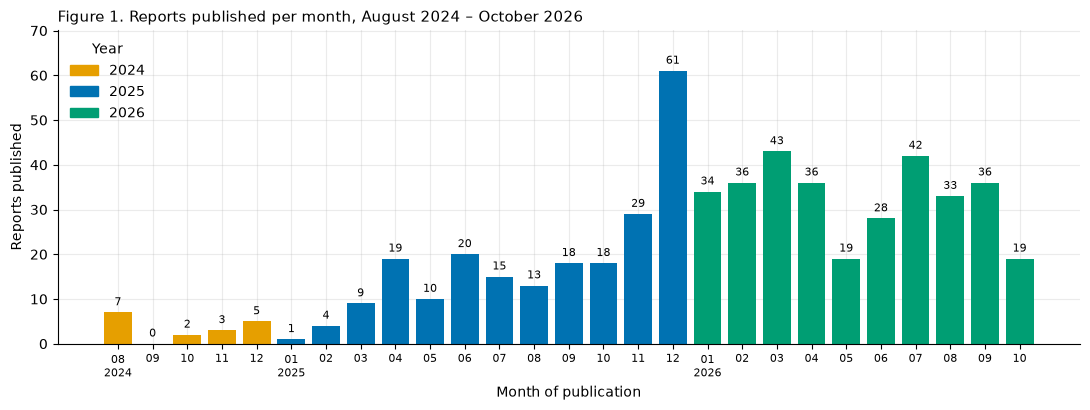

In [4]:
months = pd.period_range("2024-08", "2026-10", freq="M")
meta_df["period"] = pd.PeriodIndex(meta_df["year"] + "-" + meta_df["month"], freq="M")
by_month = meta_df.groupby("period").size().reindex(months, fill_value=0)
by_year = meta_df.groupby("year").size()
assert by_month.sum() == 560
assert by_year.to_dict() == {"2024": 17, "2025": 217, "2026": 326}
assert meta_df["period"].min() == months[0] and meta_df["period"].max() == months[-1]

coverage_table = by_month.rename("reports").rename_axis("month").reset_index()
coverage_table["month"] = coverage_table["month"].astype(str)
display(coverage_table.T)
print("Months in the period:", len(months), "| months without a report:", int((by_month == 0).sum()))

fig, ax = plt.subplots(figsize=(11, 4.2))
year_colour = {2024: C_ORANGE, 2025: C_BLUE, 2026: C_GREEN}
ax.bar(range(len(months)), by_month.values, color=[year_colour[p.year] for p in months], width=0.8)
for i, v in enumerate(by_month.values):
    ax.text(i, v + 1, str(int(v)), ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(months)))
ax.set_xticklabels([p.strftime("%m\n%Y") if (p.month == 1 or i == 0) else p.strftime("%m") for i, p in enumerate(months)], fontsize=8)
ax.set_ylabel("Reports published")
ax.set_xlabel("Month of publication")
ax.set_title("Figure 1. Reports published per month, August 2024 – October 2026", loc="left")
ax.set_ylim(0, by_month.max() * 1.15)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in year_colour.values()], labels=[str(y) for y in year_colour], title="Year", frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "F1_reports_per_month.png", bbox_inches="tight")
plt.show()

*Reading Figure 1.* Each bar is the number of reports published in one month; a bar of height 0 is a month in which the sample contains no report. The three colours separate the calendar years. The figure describes coverage only; it says nothing about the content of the reports.

**What the next cell does.** It counts the reports per directorate and year and draws Figure 2 as stacked horizontal bars, with the table of the numbers below it.

year,2024,2025,2026,total
directorate_en,,,,
FID1,1,15,29,45
FID2,0,6,24,30
FID3,1,43,61,105
FID4,4,48,44,96
FID5,2,24,60,86
FID6,4,38,52,94
FID7,5,43,56,104


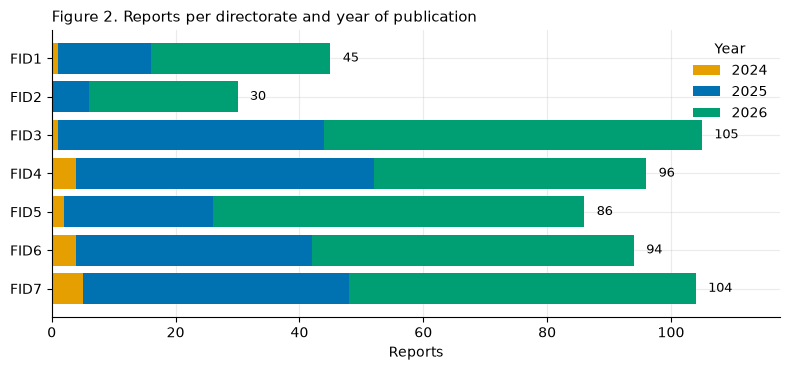

In [5]:
dir_year = pd.crosstab(meta_df["directorate_en"], meta_df["year"])
assert list(dir_year.index) == [f"FID{i}" for i in range(1, 8)]
assert dir_year.values.sum() == 560
display(dir_year.assign(total=dir_year.sum(axis=1)))

fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(dir_year))
for yr, col in zip(dir_year.columns, [C_ORANGE, C_BLUE, C_GREEN]):
    ax.barh(dir_year.index, dir_year[yr].values, left=left, color=col, label=str(yr))
    left += dir_year[yr].values
for y, tot in enumerate(left):
    ax.text(tot + 2, y, str(int(tot)), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Reports")
ax.set_title("Figure 2. Reports per directorate and year of publication", loc="left")
ax.legend(title="Year", frameon=False, loc="upper right")
ax.set_xlim(0, left.max() * 1.12)
fig.tight_layout()
fig.savefig(FIG_DIR / "F2_reports_per_directorate.png", bbox_inches="tight")
plt.show()

*Reading Figure 2.* Each bar is one directorate; its segments are the numbers of its reports by year of publication, and the number at the end is the total. The differences between the bars show the workload recorded in the register and are not a comparison of the directorates.

#### 2.2.6 Personal-data scan

**Question.** Do the texts contain personal data that must not be published?

**Logic.** The scan counts patterns that look like personal data. A count is a *candidate*: a ten-digit number that passes the checksum may be a number of a document, and a name after a role noun may be a place. For that reason the study publishes counts only and does not publish the texts or the matched strings.

**What the next cell does.** It counts, per pattern type, the reports with at least one hit and the total number of hits, and draws Figure 3 with the number of reports. No matched string is shown.

,pattern_type,reports_with_hits,total_matches
0,email,476,792
1,phone,126,148
2,person_name_after_role,74,139
3,egn_explicit_label,0,0
4,egn_checksum_candidate,2,2


Reports with at least one hit of any pattern: 504 of 560


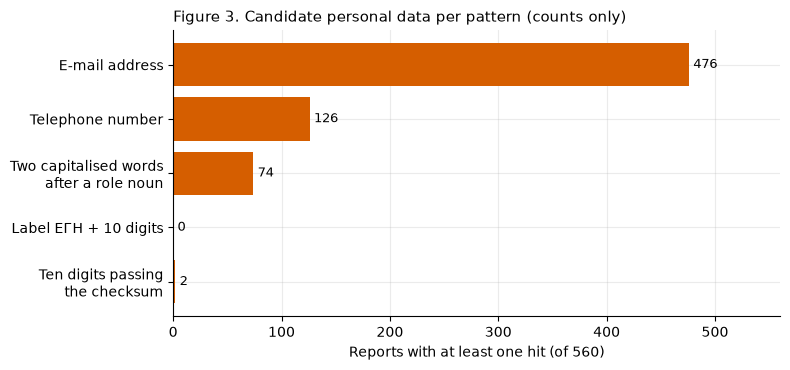

In [6]:
pii_summary = (
    pii_df.groupby("pattern_type")
    .agg(reports_with_hits=("report_key", "nunique"), total_matches=("match_count", "sum"))
    .reindex(["email", "phone", "person_name_after_role", "egn_explicit_label", "egn_checksum_candidate"])
    .fillna(0).astype(int).reset_index()
)
display(pii_summary)
print("Reports with at least one hit of any pattern:", pii_df["report_key"].nunique(), "of", len(meta_df))

_labels = {"email": "E-mail address", "phone": "Telephone number", "person_name_after_role": "Two capitalised words\nafter a role noun",
           "egn_explicit_label": "Label ЕГН + 10 digits", "egn_checksum_candidate": "Ten digits passing\nthe checksum"}
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([_labels[p] for p in pii_summary["pattern_type"]], pii_summary["reports_with_hits"], color=C_VERMILION)
for y, v in enumerate(pii_summary["reports_with_hits"]):
    ax.text(v + 4, y, str(int(v)), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Reports with at least one hit (of 560)")
ax.set_title("Figure 3. Candidate personal data per pattern (counts only)", loc="left")
ax.set_xlim(0, 560)
fig.tight_layout()
fig.savefig(FIG_DIR / "F3_pii_candidates.png", bbox_inches="tight")
plt.show()

*Reading Figure 3.* A bar is the number of reports in which the pattern was found at least once. A hit is a reason to keep the text out of the repository, not proof that a person is named. The counts above answer the question: e-mail addresses and telephone numbers are the most frequent hits and may belong to institutions, the label `ЕГН` was found in no report, and two reports contain a ten-digit number that passes the checksum. The texts are therefore not published.

#### 2.2.7 The classification table: rules, fetching and definition

##### Rules

**Question.** Which types of violation does the classifier distinguish, and how many findings does each type hold?

**Logic for a controller.** A finding is one assessed requirement in a report: the inspector either found that the requirement was breached (a violation) or recorded that it was met (no violation). Each finding is assigned to a **class** by the **action of the contracting authority**, not by the article of the law that it breaches. The index of a class is `section.class`. The 53 classes belong to 11 sections, from the choice of the award procedure (classifier section 1) to breaches of other statutes found during the checks (classifier section 11); classifier section 10 holds the findings on financial management and control, the ex-ante control and the double signature (Bulgaria, 2006a).

Each row of the table carries these attributes, which come from the text of the reports:

| Attribute | Values |
|---|---|
| `finding_no`, `school_name` | the number of the finding (a finding assigned to more than one class has more than one row) and the name of the school |
| `report_id`, `published`, `pages` | the path of the report (in the notation of Section 2.2.2), its date of publication and the pages of the report that the row refers to |
| `outcome` | `violation_with_act`, `violation_without_act`, `no_violation` |
| `act`, `act_state` | the number of the administrative violation act of the ADFI, and whether the number is given in the report, restored from the conclusion, unreadable, or there is no act |
| `law`, `provisions` | the statutes and the provisions cited by the inspector |
| `section`, `class_index`, `class_name` | the class of the finding |
| `basis_source` | the part of the report from which the class was read |
| `confidence` | `от самия извод` (from the conclusion itself), `от оценката в раздела` (from the assessment in the section), `от прочит` (from a reading of the text), `от заглавието на проверката` (from the title of the check) |

The classification is the author's. It was prepared from the text of the reports with rule-based text classification and is checked in the author's earlier study (Beluhov, 2026). The ADFI established the violations and issued the acts; the types are the author's.

##### Fetching the classification table

**What the next cell does.** The table is the one published by the earlier study, so the notebook does not carry a copy of its own. It downloads `data/adfi_classification.csv` from the repository `stem-collusion-npvu` at the fixed commit `c5feef1`, and compares the SHA-256 digest of the file with the expected one. If the file is already in `data/` with the right digest, nothing is downloaded. A wrong digest stops the notebook.

In [7]:
REF_SHA256 = "5b7aa7a71f373917276828d85856133a292ba37467939da734971c199dc04e0f"
CLS_FILE = DATA_DIR / "adfi_classification.csv"

if not (CLS_FILE.exists() and sha256_file(CLS_FILE) == REF_SHA256):
    with urllib.request.urlopen(REF_URL, timeout=60) as response:
        CLS_FILE.write_bytes(response.read())
assert sha256_file(CLS_FILE) == REF_SHA256, "The classification table differs from the published one"
print(f"{CLS_FILE.name}: {CLS_FILE.stat().st_size:,} bytes | SHA-256 {sha256_file(CLS_FILE)[:16]}... | source {REF_REPO}@{REF_COMMIT}")

cls_df = pd.read_csv(CLS_FILE, encoding="utf-8-sig", dtype=str)
print("Columns:", list(cls_df.columns))
print("Rows:", len(cls_df), "| reports:", cls_df["report_id"].nunique())

adfi_classification.csv: 977,933 bytes | SHA-256 5b7aa7a71f373917... | source beluhov/stem-collusion-npvu@c5feef1
Columns: ['finding_no', 'school_name', 'report_id', 'published', 'pages', 'outcome', 'act', 'act_state', 'law', 'provisions', 'section', 'class_index', 'class_name', 'basis_source', 'confidence']
Rows: 1824 | reports: 488


##### The classifier: definition of the 11 sections and 53 classes

**What the next cell does.** It defines the classifier as data: the 11 sections and the 53 classes with their Bulgarian and English names. This is the author's list of types. The cell after it joins the classification table to this definition and builds the table of classes with the number of rows of each class, and asserts that the totals are the ones that the study relies on.

The definition is needed because three classes (`1.05`, `5.04`, `10.04`) have no row in the table of the 560 reports. They exist in the classifier and have no row in these reports. Three more classes (`1.06`, `2.06`, `4.04`) have only rows with the outcome *no violation*.

In [8]:
CLASSIFIER_SECTIONS = [
    (1, "1. Избор на ред за възлагане", "1. Selection of Award Procedure"),
    (2, "2. Предмет и техническа спецификация", "2. Subject Matter and Technical Specification"),
    (3, "3. Изисквания към участниците", "3. Requirements for Tenderers"),
    (4, "4. Оферта и оценяване", "4. Tender Submission and Evaluation"),
    (5, "5. Откриване на поръчката", "5. Launching the Procurement"),
    (6, "6. Работа на комисията", "6. Evaluation Committee Work"),
    (7, "7. Сключване на договора", "7. Contract Conclusion"),
    (8, "8. Изпълнение на договора", "8. Contract Performance"),
    (9, "9. Публичност и досие", "9. Publicity and Procurement Dossier"),
    (10, "10. Финансово управление и контрол", "10. Financial Management and Control"),
    (11, "11. Нарушения по други закони, установени при проверка на поръчките", "11. Breaches of Other Statutes in Procurement Checks"),
]

CLASSIFIER_CLASSES = [
    ("1.01", "Разбиване на поръчки", "Splitting of procurements"),
    ("1.02", "Директно възлагане при стойност, която изисква обява или процедура", "Direct award at a value requiring a call or procedure"),
    ("1.03", "Покана до определени лица или пряко договаряне без законово основание", "Invitation to specific persons or direct negotiation without legal basis"),
    ("1.04", "Договаряне без изпратени доказателства до АОП", "Negotiation without evidence sent to PPA Agency"),
    ("1.05", "Строителство, възложено директно без писмен договор", "Works awarded directly without a written contract"),
    ("1.06", "Прогнозна стойност, определена без актуално проучване", "Estimated value determined without up-to-date market research"),
    ("2.01", "Пазарни консултации без оповестяване", "Market consultations without disclosure"),
    ("2.02", "Разнородни доставки в поръчка без обособени позиции", "Heterogeneous supplies in a procurement without lots"),
    ("2.03", "Разнородни доставки в една обособена позиция на разделена поръчка", "Heterogeneous supplies in a single lot of a divided procurement"),
    ("2.04", "Подправени спецификации – посочена търговска марка или модел", "Tailored specifications – brand or model specified"),
    ("2.05", "Пропуснати екологични изисквания към продуктите", "Omitted environmental requirements for products"),
    ("2.06", "Стандарт, изискан за доставяната стока", "Standard required for the supplied goods"),
    ("3.01", "Изискване за собствена сервизна база или система за поддръжка", "Requirement for own service base or support system"),
    ("3.02", "Сертификат за информационна сигурност или управление на услуги, изискан от участника в поръчка за доставка (ISO/IEC 27001, 27701, 20000-1)", "Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1)"),
    ("3.03", "Сертификат за качество, околна среда или безопасност на труда, изискан от участника (ISO 9001, 14001, 45001)", "Quality, environmental, or occupational health and safety certificate required from the tenderer (ISO 9001, 14001, 45001)"),
    ("3.04", "Изисквания към екипа на участника", "Requirements for the tenderer's team"),
    ("3.05", "Изискване за опит в сходни дейности", "Requirement for experience in similar activities"),
    ("3.06", "Изискване за оборот", "Turnover requirement"),
    ("3.07", "Изискване за оторизация от производителя", "Requirement for manufacturer authorization"),
    ("3.08", "Изискване за регистрация, която не се дължи или е завишена", "Requirement for registration that is not due or is excessive"),
    ("3.09", "Оценка за устойчивост EcoVadis, изискана от участника", "EcoVadis sustainability rating required from the tenderer"),
    ("3.10", "Изискване за обучение от организация с одобрена от министъра програма", "Requirement for training by an organization with a minister-approved program"),
    ("3.11", "Стеснени доказателства за критерий за подбор", "Narrowed evidence for a selection criterion"),
    ("4.01", "Изисквания към съдържанието на техническото предложение (работна програма, стратегия, подход за управление на риска) като условие за допускане", "Requirements for the content of the technical proposal (work program, strategy, risk management approach) as a condition for admission"),
    ("4.02", "Незаконосъобразна методика за оценка", "Unlawful evaluation methodology"),
    ("4.03", "Пределни единични цени като условие за допускане", "Maximum unit prices as a condition for admission"),
    ("4.04", "Декларация по чл. 47, ал. 3 от ЗОП, изискана към офертата", "Declaration under Art. 47(3) PPA required with the tender"),
    ("4.05", "Проект или визуализация на стоката, изискани към офертата", "Design or visualization of the goods required with the tender"),
    ("5.01", "Непълно обявление или обява", "Incomplete contract notice or call"),
    ("5.02", "Незаконосъобразно определени гаранции в обявлението или проекта на договор", "Unlawfully determined guarantees in the contract notice or draft contract"),
    ("5.03", "Промяна на датата на отваряне без съобщение", "Change of opening date without notice"),
    ("5.04", "Срок на договора над 5 години без мотиви", "Contract duration over 5 years without reasons"),
    ("5.05", "Краен срок за оферти в неприсъствен ден", "Tender submission deadline on a non-working day"),
    ("6.01", "Назначаване и състав на комисията; неподадена в срок декларация за липса на конфликт на интереси", "Appointment and composition of the committee; conflict-of-interest declaration not submitted on time"),
    ("6.02", "Допускане, оценяване или класиране в отклонение от условията", "Admission, evaluation, or ranking in deviation from the conditions"),
    ("7.01", "Договор, сключен без документи или без изпълнено условие", "Contract concluded without documents or without a fulfilled condition"),
    ("7.02", "Договор, различен от проекта и от офертата", "Contract different from the draft and from the tender"),
    ("7.03", "Договор, сключен преди влизане в сила на решението за откриване", "Contract concluded before entry into force of the launch decision"),
    ("8.01", "Изменение на договор без основание", "Contract modification without legal basis"),
    ("9.01", "Неизпратено в срок обявление за възложена поръчка при процедура", "Award notice not sent on time in a procedure"),
    ("9.02", "Неизпратено в срок обявление за възложена поръчка при събиране на оферти с обява", "Award notice not sent on time in a call for tenders"),
    ("9.03", "Неизпратено в срок обявление за приключване или изменение на договор", "Contract completion or modification notice not sent on time"),
    ("9.04", "Непубликуван в срок договор или приложение към него", "Contract or annex not published on time"),
    ("9.05", "Непубликувани в срок протоколи и доклади на комисията", "Committee protocols and reports not published on time"),
    ("9.06", "Непубликувани в срок решение, обявление или обява, документация, покани или разяснения", "Decision, contract notice or call, documentation, invitations, or clarifications not published on time"),
    ("9.07", "Непълно досие на поръчката", "Incomplete procurement dossier"),
    ("10.01", "Задължение или плащане без предварителен контрол", "Commitment or payment without ex-ante control"),
    ("10.02", "Задължение или плащане без двоен подпис", "Commitment or payment without double signature"),
    ("10.03", "Невъведен ред за предварителен контрол", "Unestablished procedure for ex-ante control"),
    ("10.04", "Неосъществен предварителен контрол за законосъобразност на поръчка над прага", "Unperformed ex-ante control for legality of a procurement above the threshold"),
    ("11.01", "Неизпратено в срок уведомление за предстоящо плащане чрез ИС „Разплащания с публични средства“", "Upcoming payment notification not sent on time via IS Public Payments"),
    ("11.02", "Плащане без потвърждение от НАП и Агенция „Митници“", "Payment without confirmation from NRA and Customs Agency"),
    ("11.03", "Неизпратено в срок уведомление за сключен договор чрез ИС „Разплащания с публични средства“", "Concluded contract notification not sent on time via IS Public Payments"),
]

assert len(CLASSIFIER_SECTIONS) == 11 and len(CLASSIFIER_CLASSES) == 53
assert len({c[0] for c in CLASSIFIER_CLASSES}) == 53


**What the next cell does.** It joins the table to the definition, checks that every class name of the table is the classifier's own, counts the rows per class, writes `data/derived/classifier_classes.csv` and asserts the totals.

In [9]:
sec_en = {num: en for num, bg, en in CLASSIFIER_SECTIONS}
sec_bg = {num: bg for num, bg, en in CLASSIFIER_SECTIONS}
base = pd.DataFrame(CLASSIFIER_CLASSES, columns=["class_index", "class_bg", "class_en"])
base["section_no"] = base["class_index"].str.split(".").str[0].astype(int)
base["section_bg"] = base["section_no"].map(sec_bg)
base["section_en"] = base["section_no"].map(sec_en)

cls_df["is_violation"] = cls_df["outcome"].ne("no_violation")
names_ok = cls_df[["class_index", "class_name"]].drop_duplicates().merge(base, on="class_index", how="left")
assert (names_ok["class_name"] == names_ok["class_bg"]).all(), "A class name in the table differs from the classifier"
assert set(cls_df["section"]) <= set(sec_bg.values())

counts = (
    cls_df.groupby("class_index")
    .agg(rows_violation=("is_violation", "sum"), rows_total=("is_violation", "size"), reports=("report_id", "nunique"))
    .reset_index()
)
classes = base.merge(counts, on="class_index", how="left").fillna({"rows_violation": 0, "rows_total": 0, "reports": 0})
for c in ("rows_violation", "rows_total", "reports"):
    classes[c] = classes[c].astype(int)
classes["rows_no_violation"] = classes["rows_total"] - classes["rows_violation"]
classes = classes[["class_index", "section_no", "section_en", "class_en", "section_bg", "class_bg",
                   "rows_violation", "rows_no_violation", "rows_total", "reports"]]
classes.to_csv(DERIVED_DIR / "classifier_classes.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

n_viol = int(classes["rows_violation"].sum())
n_noviol = int(classes["rows_no_violation"].sum())
assert (n_viol, n_noviol, n_viol + n_noviol) == (1203, 621, 1824)
assert (cls_df["outcome"] == "violation_with_act").sum() == 1148 and (cls_df["outcome"] == "violation_without_act").sum() == 55
assert int((classes["rows_total"] > 0).sum()) == 50
assert classes.loc[classes["rows_total"] == 0, "class_index"].tolist() == ["1.05", "5.04", "10.04"]
assert classes.loc[(classes["rows_total"] > 0) & (classes["rows_violation"] == 0), "class_index"].tolist() == ["1.06", "2.06", "4.04"]
assert cls_df["report_id"].nunique() == 488
_conf = pd.crosstab(cls_df["confidence"], cls_df["is_violation"])
assert _conf.loc["от самия извод"].tolist() == [393, 948] and _conf.loc["от оценката в раздела"].tolist() == [29, 188]
assert _conf.loc["от прочит"].tolist() == [176, 67] and _conf.loc["от заглавието на проверката"].tolist() == [23, 0]
print(f"Rows: {n_viol} violation + {n_noviol} no violation = {n_viol + n_noviol} | classes with rows: {int((classes['rows_total'] > 0).sum())} of 53")
display(classes[["class_index", "class_en", "rows_violation", "rows_no_violation", "rows_total", "reports"]])

Rows: 1203 violation + 621 no violation = 1824 | classes with rows: 50 of 53


,class_index,class_en,rows_violation,rows_no_violation,rows_total,reports
0,1.01,Splitting of procurements,10,4,14,14
1,1.02,Direct award at a value requiring a call or pr...,12,4,16,12
2,1.03,Invitation to specific persons or direct negot...,3,1,4,4
3,1.04,Negotiation without evidence sent to PPA Agency,2,0,2,2
4,1.05,Works awarded directly without a written contract,0,0,0,0
5,1.06,Estimated value determined without up-to-date ...,0,34,34,31
6,2.01,Market consultations without disclosure,7,44,51,48
7,2.02,Heterogeneous supplies in a procurement withou...,113,101,214,187
8,2.03,Heterogeneous supplies in a single lot of a di...,6,41,47,39
9,2.04,Tailored specifications – brand or model speci...,5,13,18,18


**Reading the table.** One line is one class of the classifier: its index, its English name (the Bulgarian name is in `data/derived/classifier_classes.csv`), the number of violation rows, of no-violation rows, of all rows, and the number of reports that contain at least one row of the class. The table is the complete, visible classifier of this study.

#### 2.2.8 Rows by section and by class

**Question.** How are the 1,824 rows distributed over the sections and the classes of the classifier?

**Logic.** Counting the rows shows what the classification holds before any hypothesis is tested. **This is a description of the table, not a test of H1a:** the test of Question 1 uses only the violation rows, orders the classes by size and cumulates the shares, and it belongs to the next part of the study.

**What the next cell does.** It draws Figure 4 (rows by section) with the table of the numbers above it. Figure 5 (rows by class) follows; a class with no row is marked `0`.

,section_no,section_en,rows_violation,rows_no_violation,rows_total
0,1,1. Selection of Award Procedure,27,43,70
1,2,2. Subject Matter and Technical Specification,162,226,388
2,3,3. Requirements for Tenderers,544,123,667
3,4,4. Tender Submission and Evaluation,197,68,265
4,5,5. Launching the Procurement,8,31,39
5,6,6. Evaluation Committee Work,4,75,79
6,7,7. Contract Conclusion,84,15,99
7,8,8. Contract Performance,2,1,3
8,9,9. Publicity and Procurement Dossier,125,29,154
9,10,10. Financial Management and Control,43,10,53


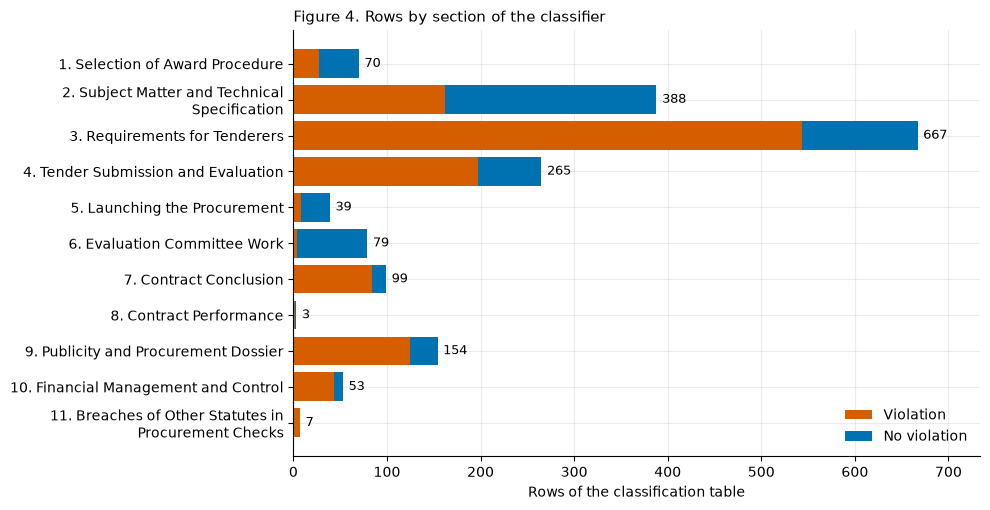

In [10]:
sec_tab = classes.groupby(["section_no", "section_en"])[["rows_violation", "rows_no_violation"]].sum().reset_index()
display(sec_tab.assign(rows_total=sec_tab["rows_violation"] + sec_tab["rows_no_violation"]))

fig, ax = plt.subplots(figsize=(10, 5.2))
labels = [textwrap.fill(s, 38) for s in sec_tab["section_en"]]
ax.barh(labels, sec_tab["rows_violation"], color=C_VERMILION, label="Violation")
ax.barh(labels, sec_tab["rows_no_violation"], left=sec_tab["rows_violation"], color=C_BLUE, label="No violation")
for y, (a, b) in enumerate(zip(sec_tab["rows_violation"], sec_tab["rows_no_violation"])):
    ax.text(a + b + 6, y, str(int(a + b)), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Rows of the classification table")
ax.set_title("Figure 4. Rows by section of the classifier", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(0, (sec_tab["rows_violation"] + sec_tab["rows_no_violation"]).max() * 1.1)
fig.tight_layout()
fig.savefig(FIG_DIR / "F4_rows_by_section.png", bbox_inches="tight")
plt.show()

*Reading Figure 4.* Each bar is one section; its red part is the number of violation rows and its blue part the number of rows where the requirement was assessed as met. The number at the end is the total.

**What the next cell does.** It draws Figure 5, one bar for each of the 53 classes in the order of the classifier.

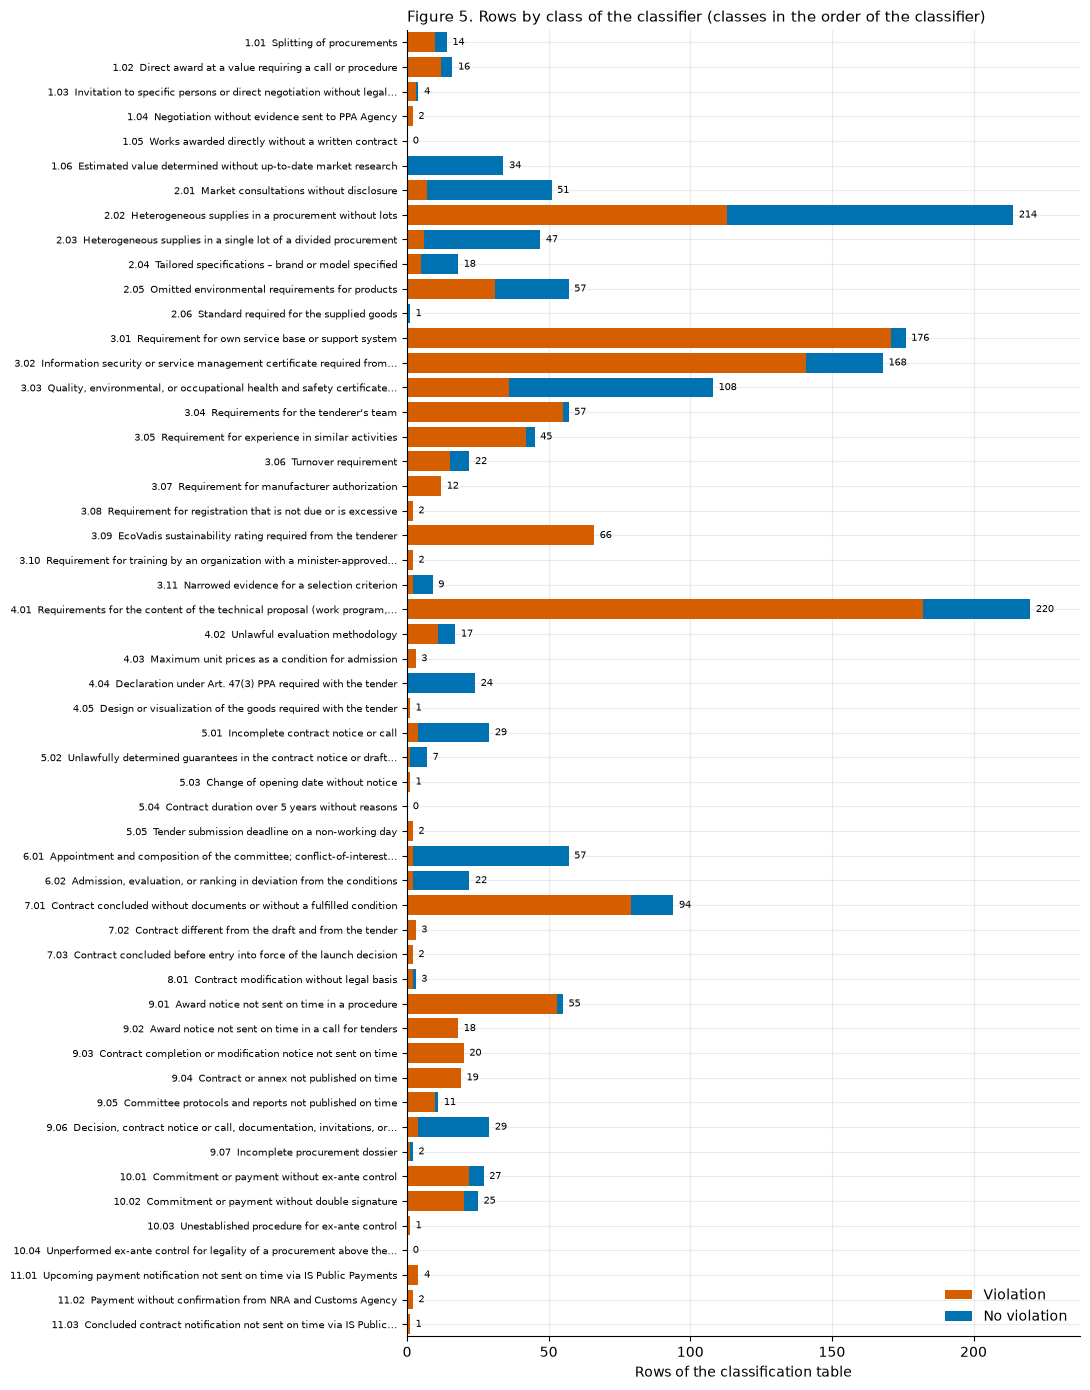

In [11]:
fig, ax = plt.subplots(figsize=(11, 14))
ylab = [f"{r.class_index}  " + textwrap.shorten(r.class_en, 70, placeholder="…") for r in classes.itertuples()]
ypos = np.arange(len(classes))
ax.barh(ypos, classes["rows_violation"], color=C_VERMILION, label="Violation")
ax.barh(ypos, classes["rows_no_violation"], left=classes["rows_violation"], color=C_BLUE, label="No violation")
for y, r in zip(ypos, classes.itertuples()):
    ax.text(r.rows_total + 2, y, str(r.rows_total), va="center", fontsize=7.5)
ax.set_yticks(ypos)
ax.set_yticklabels(ylab, fontsize=7.5)
ax.set_ylim(len(classes) - 0.5, -0.5)
ax.set_xlabel("Rows of the classification table")
ax.set_title("Figure 5. Rows by class of the classifier (classes in the order of the classifier)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(0, classes["rows_total"].max() * 1.08)
fig.tight_layout()
fig.savefig(FIG_DIR / "F5_rows_by_class.png", bbox_inches="tight")
plt.show()

*Reading Figure 5.* Each bar is one of the 53 classes in the order of the classifier, not in the order of size. The red part is the number of violation rows, the blue part the number of rows assessed as met. A class with `0` has no row in these 560 reports.

#### 2.2.9 Reconciliation of the reports and the rows

**Question.** How many of the 560 reports have rows in the classification table, and how do the 1,824 rows divide by outcome?

**Logic.** Each of the 560 reports is either in the table (it has at least one finding) or not. Every row of the table must belong to a report of the register, so the keys of the table must be a subset of the keys of the metadata.

**What the next cell does.** It brings the report paths of the table to report keys, checks that all of them are in the metadata, and draws Figure 6: the reports with and without rows, and the rows by outcome.

Reports with rows: 488 | without rows: 72 | rows: 1824


,rows
outcome,
violation_with_act,1148
no_violation,621
violation_without_act,55


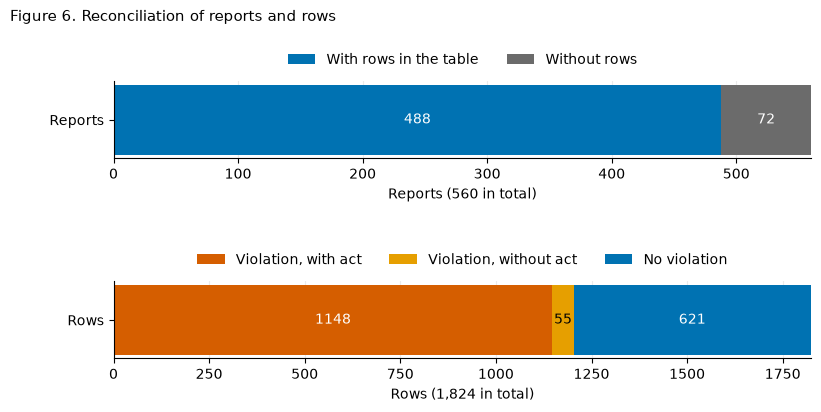

In [12]:
cls_df["report_key"] = cls_df["report_id"].map(normalize_report_key)
keys_in_table = set(cls_df["report_key"])
assert keys_in_table <= set(meta_df["report_key"]), "A report of the table is not in the register"
n_with, n_without = len(keys_in_table), len(meta_df) - len(keys_in_table)
assert (n_with, n_without) == (488, 72)
outcome_counts = cls_df["outcome"].value_counts()
print(f"Reports with rows: {n_with} | without rows: {n_without} | rows: {len(cls_df)}")
display(outcome_counts.rename("rows").to_frame())

fig, axes = plt.subplots(2, 1, figsize=(9, 3.6), gridspec_kw={"hspace": 1.6})
ax = axes[0]
ax.barh(["Reports"], [n_with], color=C_BLUE, label="With rows in the table")
ax.barh(["Reports"], [n_without], left=[n_with], color=C_GREY, label="Without rows")
ax.text(n_with / 2, 0, f"{n_with}", ha="center", va="center", color="white", fontsize=10)
ax.text(n_with + n_without / 2, 0, f"{n_without}", ha="center", va="center", color="white", fontsize=10)
ax.set_xlim(0, 560)
ax.set_xlabel("Reports (560 in total)")
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.02))
ax = axes[1]
left = 0
for key, col, lab in [("violation_with_act", C_VERMILION, "Violation, with act"), ("violation_without_act", C_ORANGE, "Violation, without act"),
                      ("no_violation", C_BLUE, "No violation")]:
    v = int(outcome_counts[key])
    ax.barh(["Rows"], [v], left=[left], color=col, label=lab)
    ax.text(left + v / 2, 0, str(v), ha="center", va="center", color="white" if key != "violation_without_act" else "black", fontsize=10)
    left += v
ax.set_xlim(0, len(cls_df))
ax.set_xlabel("Rows (1,824 in total)")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Figure 6. Reconciliation of reports and rows", x=0.01, ha="left", y=1.08, fontsize=11)
fig.savefig(FIG_DIR / "F6_reconciliation.png", bbox_inches="tight")
plt.show()

*Reading Figure 6.* The upper bar divides the 560 reports into those with at least one row in the table and those without; the lower bar divides the 1,824 rows into violations with an act, violations without an act and findings of no violation. The classification covers the reports as the table gives them; 72 reports have no row in it, because they hold neither a finding nor a conclusion that the classifier could assign to a class. The two units of analysis behind these counts, the findings and the rows, are reconciled in Section 2.2.10.

#### 2.2.10 The two units of analysis: findings and rows

**Question.** How many findings and how many rows does the classification table hold, how many of them are violations and how many are conclusions of no violation, and do the numbers agree with one another and with the study that published the table?

**Logic for a controller.** The table has two units, and a count is correct only if it says which unit it counts. A **finding** is one assessed requirement of a report, with one number `finding_no`: either a violation or a conclusion that there is no violation. A **row** is one finding in one class of the classifier. A finding that carries several classes has several rows, so counting rows alone would count such a finding more than once, and the same holds for the administrative violation acts of the ADFI. The two units are therefore counted separately and tied together by two identities:

$$ N_{\text{rows}} = N_{\text{viol\_rows}} + N_{\text{noviol\_rows}}, \qquad N_{\text{findings}} = \lvert\{\text{finding\_no}\}_{\text{viol}}\rvert + \lvert\{\text{finding\_no}\}_{\text{noviol}}\rvert $$

where $N_{\text{rows}}$ is the number of rows of the table, $N_{\text{viol\_rows}}$ and $N_{\text{noviol\_rows}}$ are its violation rows and its no-violation rows, and $\lvert\{\text{finding\_no}\}_{\text{viol}}\rvert$ and $\lvert\{\text{finding\_no}\}_{\text{noviol}}\rvert$ are the numbers of distinct finding numbers among the violation rows and among the no-violation rows. The second identity holds only if no finding is at the same time a violation and a conclusion of no violation; the next cell asserts it.

**Comparison with the earlier study.** Nine of the numbers are published in the study that produced the table (Beluhov, 2026): the reports, the reports with rows and without rows, the rows, the findings, the violations with and without an act and the conclusions of no violation are in its Section 4.2.1 "Source Tables and Invariants", and the number of distinct act cells is in its Section 4.2.7 "Key Quantities of the Audit Records". For these nine numbers the notebook sets the published number beside the counted one. The study gives no other totals, no count by class and no count by level of confidence, so these numbers are only counted here.

**Assumptions and limits.**

- The key of a report is unique in the register, and every key of the table is a key of the register. The table does not have to hold every key: 72 reports have no row (Section 2.2.9).
- A finding has one outcome. If one finding number stood in both groups, the second identity would be false.
- The acts are counted in two ways. A cell of the column `act` may list several act numbers, so the number of distinct separate numbers (706) is larger than the number of distinct non-empty cells (644). The earlier study counts cells. A violation with an act whose number cannot be read in the report has an empty cell and is in neither count.
- The check shows that the table agrees with itself and, for the nine numbers, with the published study. It does not show that the classification is correct, and the reports are a sample of the inspections.

**What the next cell does.** It splits the table into violation rows and no-violation rows and counts the findings, the rows, the reports and the acts. It sets the nine published numbers beside the counted ones, counts the rows of each class and of each level of confidence, asserts the checks above and sets `reconciliation_ok`. It writes `data/derived/reconciliation_totals.csv` and `data/derived/reconciliation_summary.csv`; the columns `expected`, `diff` and `source` are filled only for the nine published numbers.

In [13]:
viol = cls_df[cls_df["is_violation"]]
noviol = cls_df[~cls_df["is_violation"]]
findings_viol = set(viol["finding_no"])
findings_noviol = set(noviol["finding_no"])
findings_by_outcome = viol.groupby("outcome")["finding_no"].nunique()
classes_per_finding = cls_df.groupby("finding_no")["class_index"].nunique()
act_cells = cls_df["act"].dropna().str.strip()
act_cells = act_cells[act_cells != ""]
act_numbers = {token for cell in act_cells for token in cell.split()}

CONFIDENCE_EN = {
    "от самия извод": "from the conclusion itself",
    "от оценката в раздела": "from the assessment in the section",
    "от прочит": "from a reading of the text",
    "от заглавието на проверката": "from the title of the check",
}
assert set(cls_df["confidence"]) == set(CONFIDENCE_EN)
SRC_INVARIANTS = "Beluhov (2026), Section 4.2.1"
SRC_QUANTITIES = "Beluhov (2026), Section 4.2.7"

metrics = [
    ("totals", "Reports", len(meta_df), 560, SRC_INVARIANTS),
    ("totals", "Reports with rows", cls_df["report_key"].nunique(), 488, SRC_INVARIANTS),
    ("totals", "Reports without rows", len(meta_df) - cls_df["report_key"].nunique(), 72, SRC_INVARIANTS),
    ("totals", "Reports with a violation", viol["report_key"].nunique(), None, None),
    ("totals", "Reports with a conclusion of no violation", noviol["report_key"].nunique(), None, None),
    ("totals", "Rows", len(cls_df), 1824, SRC_INVARIANTS),
    ("totals", "Violation rows", len(viol), None, None),
    ("totals", "No-violation rows", len(noviol), None, None),
    ("totals", "Findings", cls_df["finding_no"].nunique(), 1373, SRC_INVARIANTS),
    ("totals", "Findings in more than one class", int((classes_per_finding > 1).sum()), None, None),
    ("totals", "Violations", len(findings_viol), None, None),
    ("totals", "Violations with an act", int(findings_by_outcome["violation_with_act"]), 739, SRC_INVARIANTS),
    ("totals", "Violations without an act", int(findings_by_outcome["violation_without_act"]), 45, SRC_INVARIANTS),
    ("totals", "Conclusions of no violation", len(findings_noviol), 589, SRC_INVARIANTS),
    ("totals", "Distinct act cells", len(set(act_cells)), 644, SRC_QUANTITIES),
    ("totals", "Distinct act numbers", len(act_numbers), None, None),
]
for conf_bg, conf_en in CONFIDENCE_EN.items():
    metrics.append(("confidence / violation rows", conf_en, int((viol["confidence"] == conf_bg).sum()), None, None))
for conf_bg, conf_en in CONFIDENCE_EN.items():
    metrics.append(("confidence / no-violation rows", conf_en, int((noviol["confidence"] == conf_bg).sum()), None, None))

totals = pd.DataFrame(metrics, columns=["table", "metric", "observed", "expected", "source"])
totals["observed"] = totals["observed"].astype(int)
totals["expected"] = totals["expected"].astype("Int64")
totals["diff"] = totals["observed"] - totals["expected"]
totals = totals[["table", "metric", "observed", "expected", "diff", "source"]]
assert int(totals["expected"].notna().sum()) == 9

summary = classes[["class_index", "class_en"]].copy()
summary["observed_viol_rows"] = summary["class_index"].map(viol["class_index"].value_counts()).fillna(0).astype(int)
summary["observed_noviol_rows"] = summary["class_index"].map(noviol["class_index"].value_counts()).fillna(0).astype(int)
summary["zero_count_class"] = ((summary["observed_viol_rows"] + summary["observed_noviol_rows"]) == 0).astype(int)

checks = {
    "the key of a report is unique in the register": bool(meta_df["report_key"].is_unique),
    "every key of the table is a key of the register": set(cls_df["report_key"]) <= set(meta_df["report_key"]),
    "no finding is both a violation and a conclusion of no violation": not (findings_viol & findings_noviol),
    "the findings split into violations and conclusions of no violation": len(findings_viol) + len(findings_noviol) == cls_df["finding_no"].nunique(),
    "a violation is either with an act or without an act": int(findings_by_outcome.sum()) == len(findings_viol),
    "the rows split into violation rows and no-violation rows": len(viol) + len(noviol) == len(cls_df),
    "every class index of the table is one of the 53 classes": set(cls_df["class_index"]) <= set(classes["class_index"]),
    "the section of a row is the section of its class index": bool((cls_df["section"] == cls_df["class_index"].str.split(".").str[0].astype(int).map(sec_bg)).all()),
    "the rows of the 53 classes add up to the rows of the table": int(summary[["observed_viol_rows", "observed_noviol_rows"]].sum().sum()) == len(cls_df),
    "no act number stands outside the violations with an act": bool((cls_df.loc[cls_df["outcome"] != "violation_with_act", "act"].fillna("").str.strip() == "").all()),
    "the nine published numbers equal the counted ones": bool((totals["diff"].dropna() == 0).all()),
}
checks_df = pd.Series(checks, name="passed").rename_axis("check").reset_index()
reconciliation_ok = bool(checks_df["passed"].all())
assert reconciliation_ok, "The reconciliation of the findings and the rows failed"

totals.to_csv(DERIVED_DIR / "reconciliation_totals.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")
summary.to_csv(DERIVED_DIR / "reconciliation_summary.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

print(f"reconciliation_ok = {reconciliation_ok} | findings: {len(findings_viol) + len(findings_noviol)} | rows: {len(cls_df)}")
display(checks_df)
display(totals)
print("Classes without a row:", summary.loc[summary["zero_count_class"] == 1, "class_index"].tolist())

reconciliation_ok = True | findings: 1373 | rows: 1824


,check,passed
0,the key of a report is unique in the register,True
1,every key of the table is a key of the register,True
2,no finding is both a violation and a conclusio...,True
3,the findings split into violations and conclus...,True
4,a violation is either with an act or without a...,True
5,the rows split into violation rows and no-viol...,True
6,every class index of the table is one of the 5...,True
7,the section of a row is the section of its cla...,True
8,the rows of the 53 classes add up to the rows ...,True
9,no act number stands outside the violations wi...,True


,table,metric,observed,expected,diff,source
0,totals,Reports,560,560,0,"Beluhov (2026), Section 4.2.1"
1,totals,Reports with rows,488,488,0,"Beluhov (2026), Section 4.2.1"
2,totals,Reports without rows,72,72,0,"Beluhov (2026), Section 4.2.1"
3,totals,Reports with a violation,410,<NA>,<NA>,NaN
4,totals,Reports with a conclusion of no violation,287,<NA>,<NA>,NaN
5,totals,Rows,1824,1824,0,"Beluhov (2026), Section 4.2.1"
6,totals,Violation rows,1203,<NA>,<NA>,NaN
7,totals,No-violation rows,621,<NA>,<NA>,NaN
8,totals,Findings,1373,1373,0,"Beluhov (2026), Section 4.2.1"
9,totals,Findings in more than one class,229,<NA>,<NA>,NaN


Classes without a row: ['1.05', '5.04', '10.04']


**Reading the tables.** The first table lists the checks; every one must be `True`, and `reconciliation_ok` is `True` only then. The second table is `data/derived/reconciliation_totals.csv`: `observed` is counted from the classification table, `expected` is the number published in the earlier study (Beluhov, 2026) with its `source`, and `diff` is `observed` minus `expected`. An empty `expected` means that the earlier study does not give the number, so it is only counted here. The rows of each of the 53 classes are in `data/derived/reconciliation_summary.csv`; the classes without a row are listed under the tables.

**What the next cell does.** It takes from the table one finding that carries three classes and one finding that has several rows in the same class, and shows their rows. They are the two cases in which the number of rows differs from the number of findings.

In [14]:
EXAMPLE_CLASSES = 3
multi_class = classes_per_finding[classes_per_finding == EXAMPLE_CLASSES]
example_multi = sorted(multi_class.index, key=int)[0]
same_class_rows = cls_df.groupby(["finding_no", "class_index"]).size()
same_class_rows = same_class_rows[same_class_rows > 1]
example_same = sorted({finding for finding, _ in same_class_rows.index}, key=int)[0]
shown = ["finding_no", "report_id", "class_index", "outcome", "provisions"]
print(f"Finding {example_multi}: {EXAMPLE_CLASSES} classes, {int((cls_df['finding_no'] == example_multi).sum())} rows")
display(cls_df.loc[cls_df["finding_no"] == example_multi, shown])
print(f"Finding {example_same}: several rows in one class")
display(cls_df.loc[cls_df["finding_no"] == example_same, shown])

Finding 63: 3 classes, 3 rows


,finding_no,report_id,class_index,outcome,provisions
68,63,2025/06/ДИД3-ПЛ-12-[1].md,2.02,violation_with_act,"чл. 2, ал. 2 от ЗОП"
69,63,2025/06/ДИД3-ПЛ-12-[1].md,3.02,violation_with_act,"чл. 2, ал. 2 от ЗОП"
70,63,2025/06/ДИД3-ПЛ-12-[1].md,3.03,violation_with_act,"чл. 2, ал. 2 от ЗОП"


Finding 1128: several rows in one class


,finding_no,report_id,class_index,outcome,provisions
1568,1128,2026/04/ДИД3-ВД-3-[1].md,2.02,no_violation,"чл. 2, ал. 2 от ЗОП"
1569,1128,2026/04/ДИД3-ВД-3-[1].md,2.02,no_violation,"чл. 49, ал. 1 от ЗОП"


*Reading the examples.* In the first finding each row has a different class, so the finding is one violation (or one conclusion) but has as many rows as classes. In the second finding all rows are in the same class and differ in the provisions that they cite; the finding is again one, and the rows must not be read as separate findings.

## 3. Rule-Based Check

### (1) Question Addressed

#### 3.1.1 Does the cited provision determine the class?

**Question.** When a finding cites a provision of a statute, does the provision alone tell which class of the classifier the finding belongs to?

**Logic for a controller.** This is Check 1 of Section 1.2.1. It does not read the finding. It reads only the provisions that the table cites for the finding and applies a fixed rule of the form "this provision of this statute means this class". If the classes of the table follow the cited provisions, the rules reproduce them and the check agrees with the table. If they do not, the classes of the table rest on more than the citation, and a controller learns how much of the classification a citation alone explains. The check compares the cited provision with the class. It does not test whether the class is correct, and a class that has no rule in the code cannot agree with the table. The rules and the classes come from the same classifier, so the check measures whether the provisions cited in the reports follow the guide of the classifier, not whether the classification is correct.

The keywords named in Section 1.2.1 are not applied here, because the published table does not carry the text of the conclusions.

### (2) Method: Rules on the Cited Provisions

#### 3.2.1 The unit of evaluation and the labels

**Question.** What is compared with what, and on which unit?

**Logic for a controller.** The unit is the **finding** (`finding_no`) of Section 2.2.10, which counts a violation or a conclusion of no violation once, however many classes it carries. For each finding the table gives the set of its classes and the text of its cited provisions. The rules give a predicted set of classes from the provisions alone. The predicted set is compared with the set of the table label by label, for the classes and for the sections (the section of a class is the number before the point of its index).

The first unit is all 1,373 findings, the 784 violations and the 589 conclusions of no violation. A conclusion of no violation also carries a class, and the comparison of violations with conclusions by class is the basis of H1b, so a check on the violations alone would leave half of the labels on which H1b rests untested. The second unit is the 784 violations alone, a check of sensitivity with the same formulas. The two units are shown side by side. A row of the table (a finding in one class) is not used as the unit, because a finding with several classes would be counted several times.

**Classes without rows.** The classifier has 53 classes. 50 of them have rows and 3 (1.05, 5.04 and 10.04) have none; among the violations alone 47 classes have rows. A class without rows has no support, so it has no recall and does not enter the macro averages of Section 3.2.2. If the rules predicted such a class, its false positives would enter the micro averages and would be shown in the table. A class that has rows but no rule can never be predicted: its recall is 0 and it enters the macro averages with that value.

**Rows and pairs.** The table has 1,824 rows, but finding 1128 has two rows in class 2.02: it cites Art. 2(2) PPA in one and Art. 49(1) PPA in the other. A finding is compared with a class once, so the number of distinct pairs of a finding and a class is 1,823. The support of the classes in Sections 3.2.4 and 3.2.5 counts the pairs and therefore adds up to 1,823, not to 1,824.

#### 3.2.2 The measures

For a label $c$ (a class or a section) and the findings $i = 1, \dots, N$, let $Y_i$ be the set of labels of finding $i$ in the table and $\hat{Y}_i$ the set of labels predicted by the rules. The counts per label are

$$ TP_c = \lvert\{i : c \in Y_i \wedge c \in \hat{Y}_i\}\rvert, \qquad FP_c = \lvert\{i : c \notin Y_i \wedge c \in \hat{Y}_i\}\rvert, \qquad FN_c = \lvert\{i : c \in Y_i \wedge c \notin \hat{Y}_i\}\rvert $$

and the measures of a label are

$$ P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c} = \frac{2 TP_c}{2 TP_c + FP_c + FN_c} $$

The micro measures pool the counts of all labels. The macro measures average the measures of the labels that have support:

$$ P_{\text{micro}} = \frac{\sum_c TP_c}{\sum_c (TP_c + FP_c)}, \qquad R_{\text{micro}} = \frac{\sum_c TP_c}{\sum_c (TP_c + FN_c)}, \qquad F1_{\text{micro}} = \frac{2 P_{\text{micro}} R_{\text{micro}}}{P_{\text{micro}} + R_{\text{micro}}} $$

$$ P_{\text{macro}} = \frac{1}{K_{\text{active}}} \sum_{c \in \text{active}} P_c, \qquad K_{\text{active}} = \lvert\{c : TP_c + FN_c > 0\}\rvert $$

$R_{\text{macro}}$ and $F1_{\text{macro}}$ are the averages of $R_c$ and $F1_c$ over the same labels.

Where $Y_i$ is the set of classes (or sections) of finding $i$ in the table; $\hat{Y}_i$ is the set that the rules predict from the cited provisions of the finding; $TP_c$ is the number of findings in which label $c$ is both in the table and predicted; $FP_c$ is the number in which it is predicted but not in the table; $FN_c$ is the number in which it is in the table but not predicted; the support of $c$ is $TP_c + FN_c$; and $K_{\text{active}}$ is the number of labels with support, the only labels in the macro averages.

A measure that is undefined (the precision of a label that is never predicted, the recall of a label without support) is left empty in the table. In the macro averages the precision of a label with support that is never predicted counts as 0.

#### 3.2.3 The rules

**Question.** Which provision of which statute is taken as a sign of which class, and on what basis?

**Logic for a controller.** A rule has the form (statute, article, paragraph, point) → class. The rules are the provisions that the classifier of the violations names for each class in its line "Разпоредби по класификатора": the classifier of the author, defined in Section 2.2.7, on which the classes of the table rest. That line is not part of the published table, and the provisions are recorded as data in the code cell below. No rule is added to them. A class is the action of the contracting authority, not an article of a statute, so a provision named by the classifier is a guide to the class and not a definition of it.

A line of the classifier that joins provisions with "и", "или" or "във връзка с" is read as a list of alternatives: any one of the provisions triggers the class. This reading is wider than the text of the classifier. Many classes name the same provision (for example, Art. 2(2) PPA is named by 18 classes), so one citation triggers many classes, and the measures of Section 3.2.4 show the false positives that follow.

A citation of the table triggers a rule only if the statute and the article are the same. A rule that names a paragraph needs the same paragraph, a rule that names a point needs the same point, and a rule without a paragraph or a point applies to every paragraph or point. A citation without a paragraph does not trigger a rule that names a paragraph, because the paragraph is not guessed. The letter under a point (for example "б. „д“") is not read. The statute is part of the rule, so Art. 58(1) PPA and Art. 58(1) of the Implementing Regulation (ППЗОП) are different provisions.

The classifier gives no date of edition for the provisions, and the text of the statutes is not compared with the rules here. Classes 11.01, 11.02 and 11.03 name provisions of the Tax and Social Insurance Procedure Code (ДОПК) that the classifier marks as not checked against the text of the code, so they have no rule.

**What the next cell does.** It lists the rules, one row per provision, with the wording of the classifier as the basis. It defines the reader of the citations and the function `rule_predict_classes`, which takes the text of the provisions of a finding and returns the set of classes. It counts the citations of the table that the reader cannot parse and lists the classes that have no rule.

In [15]:
CLASSIFIER_RULES = [
    ("1.01", "чл. 21, ал. 15 от ЗОП", [("ЗОП", "21", "15", "")]),
    ("1.02", "чл. 17, ал. 1 във връзка с чл. 20, ал. 2 или 3 от ЗОП", [("ЗОП", "17", "1", ""), ("ЗОП", "20", "2", ""), ("ЗОП", "20", "3", "")]),
    ("1.03", "чл. 191, ал. 1, т. 2 и чл. 182, ал. 1, т. 2 от ЗОП", [("ЗОП", "191", "1", "2"), ("ЗОП", "182", "1", "2")]),
    ("1.04", "чл. 132 от ППЗОП", [("ППЗОП", "132", "", "")]),
    ("1.05", "чл. 20, ал. 4, т. 1 и ал. 5 от ЗОП", [("ЗОП", "20", "4", "1"), ("ЗОП", "20", "5", "")]),
    ("1.06", "чл. 21, ал. 2 от ЗОП", [("ЗОП", "21", "2", "")]),
    ("2.01", "чл. 44 от ЗОП; чл. 19а, ал. 4 от ППЗОП", [("ЗОП", "44", "", ""), ("ППЗОП", "19а", "4", "")]),
    ("2.02", "чл. 2, ал. 2 от ЗОП, самостоятелно или с чл. 46, ал. 1 или чл. 49, ал. 1 от ЗОП; при проверка на кодовете по CPV – чл. 4, ал. 1 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "46", "1", ""), ("ЗОП", "49", "1", ""), ("ЗОП", "4", "1", "")]),
    ("2.03", "чл. 2, ал. 2 от ЗОП с чл. 46, ал. 1 или чл. 49, ал. 1 от ЗОП; при проверка на кодовете по CPV – чл. 4, ал. 1 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "46", "1", ""), ("ЗОП", "49", "1", ""), ("ЗОП", "4", "1", "")]),
    ("2.04", "чл. 49, ал. 2 от ЗОП", [("ЗОП", "49", "2", "")]),
    ("2.05", "чл. 47а от ЗОП", [("ЗОП", "47а", "", "")]),
    ("2.06", "чл. 2, ал. 2 във връзка с чл. 49, ал. 1 от ЗОП; чл. 48, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "49", "1", ""), ("ЗОП", "48", "2", "")]),
    ("3.01", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.02", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.03", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.04", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.05", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.06", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.07", "чл. 2, ал. 2 от ЗОП", [("ЗОП", "2", "2", "")]),
    ("3.08", "чл. 2, ал. 2, чл. 59, ал. 2 и чл. 60, ал. 1 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", ""), ("ЗОП", "60", "1", "")]),
    ("3.09", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.10", "чл. 2, ал. 2 и чл. 59, ал. 2 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "59", "2", "")]),
    ("3.11", "чл. 2, ал. 2 във връзка с чл. 64, ал. 6 и 7 от ЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "64", "6", ""), ("ЗОП", "64", "7", "")]),
    ("4.01", "чл. 2, ал. 2 от ЗОП; чл. 39, ал. 3, т. 1 от ППЗОП", [("ЗОП", "2", "2", ""), ("ППЗОП", "39", "3", "1")]),
    ("4.02", "чл. 70 от ЗОП", [("ЗОП", "70", "", "")]),
    ("4.03", "чл. 2, ал. 2 от ЗОП", [("ЗОП", "2", "2", "")]),
    ("4.04", "чл. 2, ал. 2 във връзка с чл. 47, ал. 3 от ЗОП; чл. 39, ал. 3, т. 1, б. „д“ от ППЗОП", [("ЗОП", "2", "2", ""), ("ЗОП", "47", "3", ""), ("ППЗОП", "39", "3", "1")]),
    ("4.05", "чл. 2, ал. 2 от ЗОП", [("ЗОП", "2", "2", "")]),
    ("5.01", "чл. 178, ал. 1 от ЗОП; чл. 7, ал. 2 от ППЗОП", [("ЗОП", "178", "1", ""), ("ППЗОП", "7", "2", "")]),
    ("5.02", "чл. 111 от ЗОП", [("ЗОП", "111", "", "")]),
    ("5.03", "чл. 53 от ППЗОП", [("ППЗОП", "53", "", "")]),
    ("5.04", "чл. 113, ал. 1 и 2 от ЗОП", [("ЗОП", "113", "1", ""), ("ЗОП", "113", "2", "")]),
    ("5.05", "чл. 28, ал. 4 от ППЗОП", [("ППЗОП", "28", "4", "")]),
    ("6.01", "чл. 103 от ЗОП; чл. 51, ал. 8 от ППЗОП", [("ЗОП", "103", "", ""), ("ППЗОП", "51", "8", "")]),
    ("6.02", "чл. 58, ал. 1 и чл. 61, ал. 2, т. 1 от ППЗОП", [("ППЗОП", "58", "1", ""), ("ППЗОП", "61", "2", "1")]),
    ("7.01", "чл. 112, ал. 1, т. 2 във връзка с чл. 58, ал. 1 от ЗОП", [("ЗОП", "112", "1", "2"), ("ЗОП", "58", "1", "")]),
    ("7.02", "чл. 112, ал. 4 от ЗОП", [("ЗОП", "112", "4", "")]),
    ("7.03", "чл. 65, ал. 2 от ППЗОП", [("ППЗОП", "65", "2", "")]),
    ("8.01", "чл. 116, ал. 1 от ЗОП", [("ЗОП", "116", "1", "")]),
    ("9.01", "чл. 26, ал. 1, т. 1 и чл. 185, т. 1 от ЗОП", [("ЗОП", "26", "1", "1"), ("ЗОП", "185", "", "1")]),
    ("9.02", "чл. 194, ал. 4 от ЗОП", [("ЗОП", "194", "4", "")]),
    ("9.03", "чл. 29, ал. 1 и 3, чл. 27 и чл. 185, т. 2 и 3 от ЗОП", [("ЗОП", "29", "1", ""), ("ЗОП", "29", "3", ""), ("ЗОП", "27", "", ""), ("ЗОП", "185", "", "2"), ("ЗОП", "185", "", "3")]),
    ("9.04", "чл. 36, ал. 1, т. 12 от ЗОП; чл. 19а, ал. 2, т. 5 от ППЗОП", [("ЗОП", "36", "1", "12"), ("ППЗОП", "19а", "2", "5")]),
    ("9.05", "чл. 192, ал. 4 от ЗОП; чл. 19а, ал. 2, т. 4 от ППЗОП", [("ЗОП", "192", "4", ""), ("ППЗОП", "19а", "2", "4")]),
    ("9.06", "чл. 36, ал. 1 от ЗОП; чл. 19а, ал. 2, т. 1 и 2 от ППЗОП", [("ЗОП", "36", "1", ""), ("ППЗОП", "19а", "2", "1"), ("ППЗОП", "19а", "2", "2")]),
    ("9.07", "чл. 121 и чл. 122 от ЗОП", [("ЗОП", "121", "", ""), ("ЗОП", "122", "", "")]),
    ("10.01", "чл. 13, ал. 3, т. 3 от ЗФУКПС", [("ЗФУКПС", "13", "3", "3")]),
    ("10.02", "чл. 13, ал. 3, т. 1 от ЗФУКПС", [("ЗФУКПС", "13", "3", "1")]),
    ("10.03", "чл. 13, ал. 1 във връзка с ал. 3, т. 3 и ал. 4 от ЗФУКПС", [("ЗФУКПС", "13", "1", ""), ("ЗФУКПС", "13", "3", "3"), ("ЗФУКПС", "13", "4", "")]),
    ("10.04", "чл. 237б от ЗОП във връзка с чл. 13, ал. 3, т. 3 от ЗФУКПС; чл. 19а, ал. 2, т. 9 от ППЗОП", [("ЗОП", "237б", "", ""), ("ЗФУКПС", "13", "3", "3"), ("ППЗОП", "19а", "2", "9")]),
]

RULES = pd.DataFrame(
    [(class_index, law, article, paragraph, point, wording)
     for class_index, wording, provisions in CLASSIFIER_RULES
     for law, article, paragraph, point in provisions],
    columns=["class_index", "law", "article", "paragraph", "point", "basis"],
)
assert RULES["class_index"].isin(base["class_index"]).all()

CITATION = re.compile(r"чл\.\s*(\d+[а-я]?)(?:,\s*ал\.\s*(\d+[а-я]?))?(?:,\s*т\.\s*(\d+[а-я]?))?\s+от\s+([^\s;]+)")


def parse_citations(provisions_text):
    return [(m.group(4), m.group(1), m.group(2) or "", m.group(3) or "") for m in CITATION.finditer(provisions_text or "")]


RULE_KEYS = list(RULES[["law", "article", "paragraph", "point", "class_index"]].itertuples(index=False, name=None))


def rule_predict_classes(provisions_text):
    predicted = set()
    for law, article, paragraph, point in parse_citations(provisions_text):
        for rule_law, rule_article, rule_paragraph, rule_point, class_index in RULE_KEYS:
            if (law, article) == (rule_law, rule_article) and rule_paragraph in ("", paragraph) and rule_point in ("", point):
                predicted.add(class_index)
    return predicted


display(RULES.drop_duplicates("class_index")[["class_index", "basis"]].reset_index(drop=True))
print(f"Provisions in the rules: {len(RULES)} | named by more than one class: {int((RULES.groupby(['law', 'article', 'paragraph', 'point'])['class_index'].nunique() > 1).sum())}")

segments = sorted({s.strip() for text in cls_df["provisions"].dropna() for s in text.split(";") if s.strip()})
unparsed = [s for s in segments if not CITATION.fullmatch(s)]
print(f"Distinct citations in the table: {len(segments)} | not parsed: {len(unparsed)}")

no_rule = classes.loc[~classes["class_index"].isin(RULES["class_index"]), ["class_index", "class_en", "rows_total", "rows_violation"]].reset_index(drop=True)
print(
    f"Classes with a rule: {RULES['class_index'].nunique()} of {len(classes)} | "
    f"without a rule but with rows: {int((no_rule['rows_total'] > 0).sum())} | "
    f"without a rule and without rows: {int((no_rule['rows_total'] == 0).sum())}"
)
display(no_rule)

,class_index,basis
0,1.01,"чл. 21, ал. 15 от ЗОП"
1,1.02,"чл. 17, ал. 1 във връзка с чл. 20, ал. 2 или 3..."
2,1.03,"чл. 191, ал. 1, т. 2 и чл. 182, ал. 1, т. 2 от..."
3,1.04,чл. 132 от ППЗОП
4,1.05,"чл. 20, ал. 4, т. 1 и ал. 5 от ЗОП"
5,1.06,"чл. 21, ал. 2 от ЗОП"
6,2.01,"чл. 44 от ЗОП; чл. 19а, ал. 4 от ППЗОП"
7,2.02,"чл. 2, ал. 2 от ЗОП, самостоятелно или с чл. 4..."
8,2.03,"чл. 2, ал. 2 от ЗОП с чл. 46, ал. 1 или чл. 49..."
9,2.04,"чл. 49, ал. 2 от ЗОП"


Provisions in the rules: 97 | named by more than one class: 7
Distinct citations in the table: 179 | not parsed: 0
Classes with a rule: 50 of 53 | without a rule but with rows: 3 | without a rule and without rows: 0


,class_index,class_en,rows_total,rows_violation
0,11.01,Upcoming payment notification not sent on time...,4,4
1,11.02,Payment without confirmation from NRA and Cust...,2,2
2,11.03,Concluded contract notification not sent on ti...,1,1


**Reading the table.** The classifier names 97 provisions for 50 of the 53 classes, and the rules are exactly these provisions. The reader parses all 179 distinct citations of the table. Seven provisions are named by more than one class, and Art. 2(2) PPA is named by 18 classes, so a finding that cites it triggers all of them. Classes 11.01, 11.02 and 11.03 (4, 2 and 1 rows) have no rule, because the classifier marks the text of ДОПК as not checked. Classes 1.05, 5.04 and 10.04 have a rule but no rows in the table. Classes 1.05 and 5.04 are never predicted. Class 10.04 is predicted for 22 findings and all 22 are false positives; the provision that triggers it is Art. 13(3), point 3 of the Financial Management and Control in the Public Sector Act (ЗФУКПС), which classes 10.01 and 10.03 name as well.

#### 3.2.4 Prediction and measures

**Question.** How well do the rules reproduce the classes of the table?

**Logic for a controller.** Agreement between the rules and the table is a statement about the citation, not about the finding. A high agreement would mean that the cited provision explains the class; a low agreement means that the provision does not, or that no rule exists for it. Both results are read with the counts of the cells, and the second also with the list of the classes without a rule from Section 3.2.3.

**What the next cell does.** It builds one record per finding with its cited provisions, its classes and sections in the table, and whether it is a violation. It predicts the classes with `rule_predict_classes`, counts $TP$, $FP$ and $FN$ per section and per class for the two units, computes the micro and macro measures of Section 3.2.2, writes `data/derived/rule_classifier_metrics.csv` and shows the sections of the two units side by side, with the classes that have a rule.

In [16]:
METRIC_COLUMNS = ["unit", "level", "label", "label_en", "support", "predicted", "tp", "fp", "fn", "precision", "recall", "f1"]


def finding_units(table):
    ordered = table.assign(_n=table["finding_no"].astype(int)).sort_values("_n", kind="stable")
    records = []
    for finding_no, group in ordered.groupby("finding_no", sort=False):
        provisions = "; ".join(dict.fromkeys(p for p in group["provisions"].fillna("") if p))
        true_classes = set(group["class_index"])
        records.append({
            "finding_no": finding_no,
            "provisions": provisions,
            "is_violation": bool(group["is_violation"].any()),
            "true_classes": true_classes,
            "true_sections": {c.split(".")[0] for c in true_classes},
        })
    return pd.DataFrame(records)


def label_counts(true_sets, pred_sets, labels):
    rows = []
    for label in labels:
        in_true = [label in t for t in true_sets]
        in_pred = [label in p for p in pred_sets]
        tp = sum(a and b for a, b in zip(in_true, in_pred))
        fp = sum((not a) and b for a, b in zip(in_true, in_pred))
        fn = sum(a and (not b) for a, b in zip(in_true, in_pred))
        rows.append((label, tp, fp, fn))
    return pd.DataFrame(rows, columns=["label", "tp", "fp", "fn"])


def ratio(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan


def measures(tp, fp, fn):
    return ratio(tp, tp + fp), ratio(tp, tp + fn), ratio(2 * tp, 2 * tp + fp + fn)


def metric_table(unit_name, level, true_sets, pred_sets, labels, names):
    counts = label_counts(true_sets, pred_sets, labels)
    records = []
    for label, tp, fp, fn in counts.itertuples(index=False):
        precision, recall, f1 = measures(tp, fp, fn)
        records.append([unit_name, level, label, names[label], tp + fn, tp + fp, tp, fp, fn, precision, recall, f1])
    detail = pd.DataFrame(records, columns=METRIC_COLUMNS)
    tp, fp, fn = (int(detail[c].sum()) for c in ("tp", "fp", "fn"))
    precision, recall, f1 = measures(tp, fp, fn)
    micro = [unit_name, level, "micro", "All labels (micro)", tp + fn, tp + fp, tp, fp, fn, precision, recall, f1]
    active = detail[detail["support"] > 0]
    macro = [unit_name, level, "macro", "Active labels (macro)", len(active), pd.NA, pd.NA, pd.NA, pd.NA,
             active["precision"].fillna(0).mean(), active["recall"].mean(), active["f1"].fillna(0).mean()]
    return pd.concat([detail, pd.DataFrame([micro, macro], columns=METRIC_COLUMNS)], ignore_index=True)


units = finding_units(cls_df)
assert len(units) == 1373 and int(units["is_violation"].sum()) == 784
assert len(cls_df) == 1824 and len(cls_df[["finding_no", "class_index"]].drop_duplicates()) == 1823
assert sum(len(c) for c in units["true_classes"]) == 1823
units["pred_classes"] = units["provisions"].map(rule_predict_classes)
units["pred_sections"] = units["pred_classes"].map(lambda s: {c.split(".")[0] for c in s})

section_labels = [str(n) for n in sec_en]
section_names = {str(n): name for n, name in sec_en.items()}
class_labels = base["class_index"].tolist()
class_names = dict(zip(base["class_index"], base["class_en"]))
unit_sets = {"all_findings": units, "violation_findings": units[units["is_violation"]]}

tables = []
for unit_name, subset in unit_sets.items():
    tables.append(metric_table(unit_name, "section", subset["true_sections"], subset["pred_sections"], section_labels, section_names))
    tables.append(metric_table(unit_name, "class", subset["true_classes"], subset["pred_classes"], class_labels, class_names))
rule_metrics = pd.concat(tables, ignore_index=True)
for column in ("support", "predicted", "tp", "fp", "fn"):
    rule_metrics[column] = rule_metrics[column].astype("Int64")
for column in ("precision", "recall", "f1"):
    rule_metrics[column] = rule_metrics[column].astype(float).round(4)
assert len(rule_metrics) == 136
rule_metrics.to_csv(DERIVED_DIR / "rule_classifier_metrics.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

for unit_name, subset in unit_sets.items():
    empty = int((subset["pred_classes"].map(len) == 0).sum())
    without_provisions = int((subset["provisions"] == "").sum())
    print(f"{unit_name}: {len(subset)} findings | empty prediction: {empty} | without a cited provision: {without_provisions}")

wide = None
for unit_name, tag in (("all_findings", "all"), ("violation_findings", "viol")):
    part = (
        rule_metrics[(rule_metrics["unit"] == unit_name) & (rule_metrics["level"] == "section")]
        .set_index("label")[["support", "precision", "recall", "f1"]]
        .add_suffix(f"_{tag}")
    )
    wide = part if wide is None else wide.join(part)
display(wide.reindex(section_labels + ["micro", "macro"]))

wide_classes = None
for unit_name, tag in (("all_findings", "all"), ("violation_findings", "viol")):
    part = (
        rule_metrics[(rule_metrics["unit"] == unit_name) & (rule_metrics["level"] == "class")]
        .set_index("label")[["support", "predicted", "tp", "precision", "recall"]]
        .add_suffix(f"_{tag}")
    )
    wide_classes = part if wide_classes is None else wide_classes.join(part)
display(wide_classes.reindex(class_labels + ["micro", "macro"]))

all_findings: 1373 findings | empty prediction: 184 | without a cited provision: 112
violation_findings: 784 findings | empty prediction: 30 | without a cited provision: 9


,support_all,precision_all,recall_all,f1_all,support_viol,precision_viol,recall_viol,f1_viol
label,,,,,,,,
1,70,0.9811,0.7429,0.8455,27,0.9615,0.9259,0.9434
2,385,0.4462,0.9377,0.6047,162,0.3419,0.9877,0.5079
3,361,0.4985,0.8947,0.6402,238,0.5452,0.9622,0.6960
4,262,0.3739,0.9504,0.5366,194,0.4385,0.9742,0.6048
5,38,0.9333,0.3684,0.5283,8,0.8750,0.8750,0.8750
6,79,1.0000,0.3924,0.5636,4,1.0000,1.0000,1.0000
7,99,0.9895,0.9495,0.9691,84,0.9878,0.9643,0.9759
8,3,1.0000,1.0000,1.0000,2,1.0000,1.0000,1.0000
9,154,0.9841,0.8052,0.8857,125,0.9915,0.9280,0.9587


,support_all,predicted_all,tp_all,precision_all,recall_all,support_viol,predicted_viol,tp_viol,precision_viol,recall_viol
label,,,,,,,,,,
1.01,14,12,12,1.0000,0.8571,10,9,9,1.0000,0.9000
1.02,16,14,11,0.7857,0.6875,12,14,11,0.7857,0.9167
1.03,4,1,1,1.0000,0.2500,3,1,1,1.0000,0.3333
1.04,2,2,2,1.0000,1.0000,2,2,2,1.0000,1.0000
1.05,0,0,0,NaN,NaN,0,0,0,NaN,NaN
1.06,34,24,24,1.0000,0.7059,0,0,0,NaN,NaN
2.01,51,42,41,0.9762,0.8039,7,8,7,0.8750,1.0000
2.02,213,713,205,0.2875,0.9624,113,426,111,0.2606,0.9823
2.03,47,713,41,0.0575,0.8723,6,426,6,0.0141,1.0000


**Reading the table.** The rules predict at least one class for 1,189 of the 1,373 findings and for 754 of the 784 violations; the other 184 and 30 findings get an empty prediction. 112 findings, 9 of them violations, cite no provision at all.

At the level of the sections the micro precision is 0.5201, the micro recall 0.8599 and F1 0.6481 on all findings, and 0.5347, 0.9575 and 0.6862 on the violations. The macro averages over the 11 sections are P 0.7461, R 0.7234, F1 0.6846 and P 0.7401, R 0.8743, F1 0.7783. Sections 1, 7, 8, 9 and 10 are reproduced with precision of at least 0.98 on all findings; sections 2, 3 and 4 have recall above 0.89 but precision of 0.37 to 0.50, and section 11 is never predicted (recall 0).

At the level of the classes the rules predict 12,386 labels for 1,823 labels of the table: TP 1,571, FP 10,815, FN 252, so the micro precision is 0.1268, the micro recall 0.8618 and F1 0.2211. On the violations the numbers are 8,017 predicted labels for 1,203, TP 1,141, FP 6,876, FN 62, with micro P 0.1423, R 0.9485 and F1 0.2475. The macro averages over the 50 and 47 active classes are P 0.5591, R 0.7905, F1 0.5139 and P 0.5752, R 0.8741, F1 0.5790.

The recall is high because every provision of a class is a trigger, and the precision is low because 18 classes (2.02, 2.03, 2.06, 3.01 to 3.11, 4.01, 4.03, 4.04 and 4.05) name Art. 2(2) PPA and each is predicted for 641 to 713 findings. Classes that name their own provisions are reproduced with high precision, for example 1.01 (precision 1.0000, recall 0.8571), 2.05 (1.0000, 0.9649) and 7.01 (0.9889, 0.9468). A class predicted by a rule is a sign of agreement with the table, not a proven violation.

#### 3.2.5 Is the cited article a guide to the type?

**Question.** Findings that cite only Art. 2(2) PPA are many. Are they spread over many classes, and how do the rules behave on them compared with the other findings?

**Logic for a controller.** If one provision is the only citation of findings in many different classes, a rule built on it cannot tell the classes apart, and the claim that such findings lower the agreement can be checked with counts. A finding is counted here only if its single citation is Art. 2(2) PPA; a finding that cites it together with other provisions is among the other findings.

**What the next cell does.** It marks the findings whose only citation is Art. 2(2) PPA and, for each unit and each of the two groups, counts the findings, the classes that they carry in the table, the labels in the table and the labels predicted, and gives the precision and the recall at the level of the classes.

In [17]:
ART_2_2 = ("ЗОП", "2", "2", "")
units["only_art_2_2"] = units["provisions"].map(lambda text: bool(text) and set(parse_citations(text)) == {ART_2_2})

records = []
for unit_name, subset in (("all_findings", units), ("violation_findings", units[units["is_violation"]])):
    for group_name, part in (("only Art. 2(2) PPA", subset[subset["only_art_2_2"]]), ("other findings", subset[~subset["only_art_2_2"]])):
        counts = label_counts(part["true_classes"], part["pred_classes"], class_labels)
        tp, fp, fn = (int(counts[c].sum()) for c in ("tp", "fp", "fn"))
        precision, recall, _ = measures(tp, fp, fn)
        n_classes = len(set().union(*part["true_classes"])) if len(part) else 0
        records.append((unit_name, group_name, len(part), ratio(len(part), len(subset)), n_classes, tp + fn, tp + fp, tp, precision, recall))
art_2_2 = pd.DataFrame(
    records,
    columns=["unit", "group", "findings", "share_of_unit", "classes_in_table", "true_labels", "predicted_labels", "tp", "precision", "recall"],
).round(4)
display(art_2_2)

,unit,group,findings,share_of_unit,classes_in_table,true_labels,predicted_labels,tp,precision,recall
0,all_findings,only Art. 2(2) PPA,331,0.2411,17,589,5958,587,0.0985,0.9966
1,all_findings,other findings,1042,0.7589,48,1234,6428,984,0.1531,0.7974
2,violation_findings,only Art. 2(2) PPA,254,0.3240,16,510,4572,508,0.1111,0.9961
3,violation_findings,other findings,530,0.6760,46,693,3445,633,0.1837,0.9134


**Reading the table.** 331 findings (24.11 % of the 1,373) cite only Art. 2(2) PPA; they carry 17 classes and 589 labels in the table. The rules predict 5,958 labels for them, 587 of them correct: precision 0.0985, recall 0.9966. Among the violations the number is 254 (32.40 %), with 16 classes and 510 labels, 4,572 predicted labels and 508 correct: precision 0.1111, recall 0.9961.

The other 1,042 findings (48 classes, 1,234 labels) get 6,428 predicted labels, 984 correct (precision 0.1531, recall 0.7974); the other 530 violations (46 classes, 693 labels) get 3,445, 633 correct (precision 0.1837, recall 0.9134).

The recall on the findings that cite only Art. 2(2) PPA is not lower than on the others, because that article triggers all 18 classes that name it. The statement that these findings lower the agreement is not supported by the recall. What the counts show is that a large share of the findings, spread over 17 classes, cite a provision that cannot tell the classes apart, and that the precision is low in both groups.

#### 3.2.6 How certain are the measures?

**Question.** How much would the measures of Section 3.2.4 change if another set of reports had been drawn?

**Logic for a controller.** The measures of Section 3.2.4 are numbers for the reports of this study: 488 reports with findings and 410 reports with violations. A different set of reports would give different numbers. The interval shows how far a number can move. The findings of one report are written by one team under one practice, so they are not independent of one another. The unit of resampling is therefore the report, not the finding. A wide interval means that the number should not be read as exact.

**Method.** The reports that have findings in the unit are the clusters $g = 1, \dots, G$. In replication $b = 1, \dots, B$ the reports are drawn $G$ times with replacement, and the findings of a drawn report are taken with it, as many times as the report was drawn. Let $m_g^{(b)}$ be the number of times report $g$ was drawn. The counts of a label $c$ in the replication are

$$ TP_c^{(b)} = \sum_{g=1}^{G} m_g^{(b)}\, TP_{c,g}, \qquad FP_c^{(b)} = \sum_{g=1}^{G} m_g^{(b)}\, FP_{c,g}, \qquad FN_c^{(b)} = \sum_{g=1}^{G} m_g^{(b)}\, FN_{c,g} $$

and the measures of Section 3.2.2 are computed from them. For the macro measures the average is taken over the labels that have support in that replication,

$$ K_{\text{active}}^{(b)} = \lvert\{c : TP_c^{(b)} + FN_c^{(b)} > 0\}\rvert, $$

and the precision of such a label that is never predicted counts as 0. The interval of a measure $\theta$ is the percentile interval (Efron and Tibshirani, 1994)

$$ \left[\, Q_{0.025}\big(\theta^{(1)}, \dots, \theta^{(B)}\big),\; Q_{0.975}\big(\theta^{(1)}, \dots, \theta^{(B)}\big) \,\right] $$

Where $G$ is the number of reports in the unit; $B$ is the number of replications, 2,000 (Section 1.2.1); $m_g^{(b)}$ is how many times report $g$ is drawn in replication $b$; $TP_{c,g}$, $FP_{c,g}$ and $FN_{c,g}$ are the counts of label $c$ in the findings of report $g$; $\theta^{(b)}$ is the value of the measure in replication $b$; and $Q_q$ is the $q$-quantile of the $B$ values.

The generator of the random numbers starts from a fixed number written in the cell, so a second run draws the same reports and gives the same limits; another starting number would move each limit a little. The same drawn reports are used for the sections and the classes and for the micro and the macro measures of a unit.

**Limits.** The reports are taken as independent of one another. The interval does not correct the choice of the reports: the reports are a sample, and a bias in the choice stays in the interval. The interval concerns the agreement of the rules with the table, not the correctness of the classification.

**What the next cell does.** It reads from the table the report of each finding and asserts that every finding is in exactly one report. For the two units it counts $TP$, $FP$ and $FN$ per report and per label, draws the replications, and computes the micro and the macro precision, recall and $F1$ at the level of the sections and of the classes. It asserts that the same function, run on the original sample with every report once, gives the estimates of Section 3.2.4. It writes `data/derived/rule_classifier_ci.csv` and shows the 24 rows, the number of reports of each unit and the estimates that lie outside their own interval. It also shows, for each unit and level, how many labels with support are active in a replication on average, the share of the replications in which each label with support is absent (the labels absent from at least 1 % of them), and the mean and the median of the macro precision of the sections.

In [18]:
FINDING_REPORT = cls_df.groupby("finding_no")["report_key"].agg(["nunique", "first"])
assert (FINDING_REPORT["nunique"] == 1).all()
assert len(FINDING_REPORT) == len(units) == 1373

rng = np.random.default_rng(20261117)
B = HYPOTHESIS_THRESHOLDS["bootstrap_replications"]
CI_COLUMNS = ["unit", "level", "averaging", "measure", "estimate", "ci_low", "ci_high", "clusters", "replicates"]
LEVELS = {"section": ("sections", section_labels), "class": ("classes", class_labels)}


def safe_ratio(numerator, denominator):
    return np.divide(numerator, denominator, out=np.zeros(np.shape(numerator)), where=denominator > 0)


def report_counts(subset, prefix, labels, codes, n_clusters):
    truth = np.array([[label in s for label in labels] for s in subset[f"true_{prefix}"]])
    predicted = np.array([[label in s for label in labels] for s in subset[f"pred_{prefix}"]])
    counts = np.zeros((n_clusters, 3, len(labels)), dtype=np.int64)
    for k, flags in enumerate((truth & predicted, ~truth & predicted, truth & ~predicted)):
        np.add.at(counts[:, k, :], codes, flags)
    return counts


def measure_arrays(weights, counts):
    total = np.tensordot(weights, counts, axes=(1, 0))
    tp, fp, fn = total[:, 0, :], total[:, 1, :], total[:, 2, :]
    pooled_tp, pooled_fp, pooled_fn = tp.sum(axis=1), fp.sum(axis=1), fn.sum(axis=1)
    active = (tp + fn) > 0
    n_active = active.sum(axis=1)
    return {
        ("micro", "precision"): safe_ratio(pooled_tp, pooled_tp + pooled_fp),
        ("micro", "recall"): safe_ratio(pooled_tp, pooled_tp + pooled_fn),
        ("micro", "f1"): safe_ratio(2 * pooled_tp, 2 * pooled_tp + pooled_fp + pooled_fn),
        ("macro", "precision"): (safe_ratio(tp, tp + fp) * active).sum(axis=1) / n_active,
        ("macro", "recall"): (safe_ratio(tp, tp + fn) * active).sum(axis=1) / n_active,
        ("macro", "f1"): (safe_ratio(2 * tp, 2 * tp + fp + fn) * active).sum(axis=1) / n_active,
    }


records = []
activity_rows = []
absent_rows = []
precision_rows = []
cluster_numbers = {}
for unit_name, subset in unit_sets.items():
    codes, names = pd.factorize(subset["finding_no"].map(FINDING_REPORT["first"]))
    n_clusters = len(names)
    cluster_numbers[unit_name] = n_clusters
    draws = rng.integers(0, n_clusters, size=(B, n_clusters))
    weights = np.stack([np.bincount(row, minlength=n_clusters) for row in draws])
    ones = np.ones((1, n_clusters), dtype=np.int64)
    for level, (prefix, labels) in LEVELS.items():
        counts = report_counts(subset, prefix, labels, codes, n_clusters)
        point = measure_arrays(ones, counts)
        arrays = measure_arrays(weights, counts)
        support = np.tensordot(weights, counts[:, 0, :] + counts[:, 2, :], axes=(1, 0))
        with_support = (counts[:, 0, :] + counts[:, 2, :]).sum(axis=0) > 0
        missing = (support[:, with_support] == 0).mean(axis=0)
        activity_rows.append([unit_name, level, int(with_support.sum()), round(float((support > 0).sum(axis=1).mean()), 2)])
        for label, share in zip(np.array(labels)[with_support], missing):
            if share >= 0.01:
                absent_rows.append([unit_name, level, label, round(float(share) * 100, 1)])
        if level == "section":
            precision = arrays[("macro", "precision")]
            precision_rows.append([unit_name, round(float(precision.mean()), 4), round(float(np.median(precision)), 4)])
        for (averaging, measure), values in arrays.items():
            low, high = np.quantile(values, [0.025, 0.975])
            estimate = float(point[(averaging, measure)][0])
            reference = rule_metrics[
                (rule_metrics["unit"] == unit_name) & (rule_metrics["level"] == level) & (rule_metrics["label"] == averaging)
            ][measure].iloc[0]
            assert abs(round(estimate, 4) - reference) < 1e-9, (unit_name, level, averaging, measure)
            records.append([unit_name, level, averaging, measure, round(estimate, 4), round(float(low), 4), round(float(high), 4), n_clusters, B])

ci_table = pd.DataFrame(records, columns=CI_COLUMNS)
assert len(ci_table) == 24
assert cluster_numbers["all_findings"] == 488
assert cluster_numbers["violation_findings"] == 410
ci_table.to_csv(DERIVED_DIR / "rule_classifier_ci.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

for unit_name, n_clusters in cluster_numbers.items():
    print(f"{unit_name}: {n_clusters} reports | replications: {B}")
display(ci_table)
outside = ci_table[(ci_table["estimate"] < ci_table["ci_low"]) | (ci_table["estimate"] > ci_table["ci_high"])]
print("Estimates outside their own interval:", len(outside))
display(outside)

activity = pd.DataFrame(activity_rows, columns=["unit", "level", "labels_with_support", "mean_active_labels"])
absent = pd.DataFrame(absent_rows, columns=["unit", "level", "label", "absent_percent"]).sort_values(["unit", "level", "absent_percent"], ascending=[True, True, False]).reset_index(drop=True)
macro_precision_sections = pd.DataFrame(precision_rows, columns=["unit", "mean_of_replications", "median_of_replications"])
display(activity)
display(absent)
display(macro_precision_sections)


all_findings: 488 reports | replications: 2000
violation_findings: 410 reports | replications: 2000


,unit,level,averaging,measure,estimate,ci_low,ci_high,clusters,replicates
0,all_findings,section,micro,precision,0.5201,0.5030,0.5372,488,2000
1,all_findings,section,micro,recall,0.8599,0.8403,0.8795,488,2000
2,all_findings,section,micro,f1,0.6481,0.6332,0.6634,488,2000
3,all_findings,section,macro,precision,0.7461,0.7211,0.7579,488,2000
4,all_findings,section,macro,recall,0.7234,0.6915,0.7556,488,2000
5,all_findings,section,macro,f1,0.6846,0.6515,0.7114,488,2000
6,all_findings,class,micro,precision,0.1268,0.1200,0.1341,488,2000
7,all_findings,class,micro,recall,0.8618,0.8426,0.8808,488,2000
8,all_findings,class,micro,f1,0.2211,0.2106,0.2321,488,2000
9,all_findings,class,macro,precision,0.5591,0.5247,0.6084,488,2000


Estimates outside their own interval: 0


,unit,level,averaging,measure,estimate,ci_low,ci_high,clusters,replicates


,unit,level,labels_with_support,mean_active_labels
0,all_findings,section,11,10.93
1,all_findings,class,50,46.72
2,violation_findings,section,11,10.84
3,violation_findings,class,47,42.86


,unit,level,label,absent_percent
0,all_findings,class,11.02,37.1
1,all_findings,class,11.03,37.1
2,all_findings,class,10.03,36.6
3,all_findings,class,5.03,36.4
4,all_findings,class,2.06,36.0
5,all_findings,class,4.05,35.2
6,all_findings,class,9.07,14.9
7,all_findings,class,3.08,13.7
8,all_findings,class,5.05,13.4
9,all_findings,class,3.10,12.8


,unit,mean_of_replications,median_of_replications
0,all_findings,0.7461,0.7464
1,violation_findings,0.7379,0.7394


**Reading the table.** The table has 24 intervals, 12 for the 488 reports with findings and 12 for the 410 reports with violations, each from 2,000 replications. Every estimate of Section 3.2.4 lies inside its own interval (0 outside), and the estimates are the same numbers as in that section.

At the level of the sections the micro F1 is 0.6481 [0.6332; 0.6634] on all findings and 0.6862 [0.6667; 0.7054] on the violations. The macro F1 is 0.6846 [0.6515; 0.7114] and 0.7783 [0.7424; 0.7956]. The micro recall on the violations is 0.9575 [0.9395; 0.9733], and the micro precision is 0.5201 [0.5030; 0.5372] on all findings and 0.5347 [0.5127; 0.5586] on the violations. The low precision of the sections is not a result of random variation between the reports: its upper limit is below 0.56 in both units.

At the level of the classes the micro F1 is 0.2211 [0.2106; 0.2321] on all findings and 0.2475 [0.2336; 0.2627] on the violations, and the micro precision is 0.1268 [0.1200; 0.1341] and 0.1423 [0.1332; 0.1526]. The low micro F1 of the classes has a narrow interval (widths 0.0215 and 0.0291, upper limits 0.2321 and 0.2627), so it does not come from random variation between the reports. Its source is shown in Section 3.2.5.

The macro intervals are wider than the micro intervals. At the level of the classes the macro F1 is 0.5139 [0.4876; 0.5630] on all findings (width 0.0754) and 0.5790 [0.5418; 0.6339] on the violations (width 0.0921), against widths of 0.0215 and 0.0291 for the micro F1. The macro precision on the violations is 0.5752 [0.5321; 0.6263] and the macro recall 0.8741 [0.8414; 0.9268]. A label with one or two findings counts as much as a label with hundreds, and such a label is often absent from a replication. On average 46.72 of the 50 classes with support are active in a replication on all findings, and 42.86 of the 47 on the violations. The classes absent from 35 % to 39 % of the replications are 2.06, 4.05, 5.03, 10.03, 11.02 and 11.03 on all findings, and 4.05, 5.02, 5.03, 9.07, 10.03, 11.02 and 11.03 on the violations (2.06 has no support among the violations).

Some macro estimates lie close to the upper limit, for example the macro precision of the sections: 0.7461 with the upper limit 0.7579 on all findings, and 0.7401 with 0.7589 on the violations. The estimate is not shifted: the mean of the replications is 0.7461 and 0.7379, and the median 0.7464 and 0.7394. The interval is not symmetric: on all findings the lower part is 0.0250 and the upper part 0.0118, and on the violations 0.0410 and 0.0188. Two sections are absent from some replications. Section 8 is absent from 5.0 % of the replications on all findings and from 11.4 % on the violations; it has support 3 on all findings and 2 on the violations, and Section 3.2.4 shows that it is reproduced with precision, recall and F1 of 1. When it is absent, it leaves the average, and the macro average falls. Section 11 is absent from 2.1 % of the replications on all findings and from 1.9 % on the violations. It is never predicted, so its precision is counted as 0, and its recall and F1 are 0 (support 7 in both units). When it is absent, the macro average rises, but it is absent less often than section 8. On the violations section 6 is also absent from 2.1 % of the replications.

**Limits of the reading.** The reports are taken as independent, the choice of the reports is not corrected, and the intervals concern the agreement of the rules with the table. They do not say that a class predicted by a rule is a proven violation.

**What the next cell does.** It draws Figure 7: the $F1$ of the rules against the table, with its 95 % interval, for the two units. In each panel the bars are the micro and the macro $F1$ at the level of the sections and of the classes.

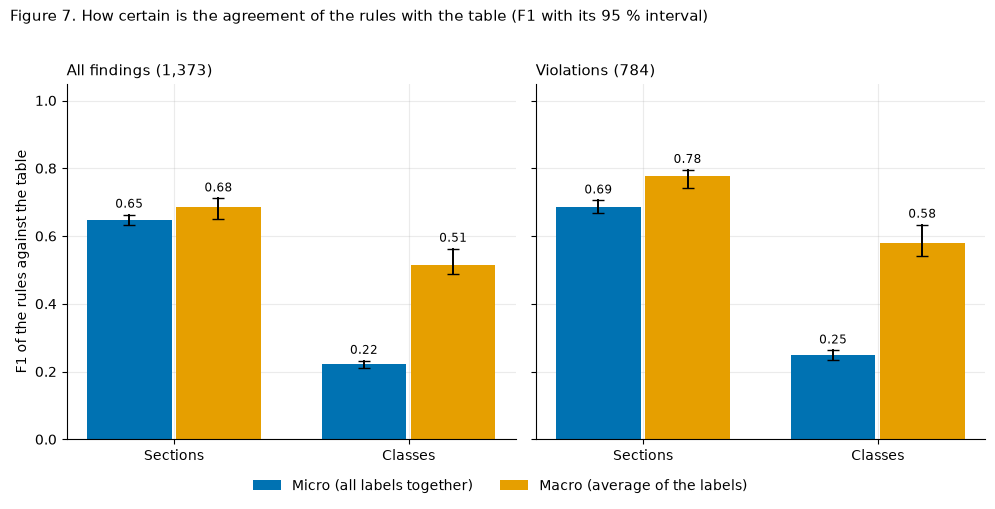

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
panel_titles = {
    "all_findings": f"All findings ({len(units):,})",
    "violation_findings": f"Violations ({int(units['is_violation'].sum()):,})",
}
for ax, unit_name in zip(axes, unit_sets):
    part = ci_table[(ci_table["unit"] == unit_name) & (ci_table["measure"] == "f1")]
    for j, level in enumerate(("section", "class")):
        for offset, averaging, colour, name in ((-0.19, "micro", C_BLUE, "Micro (all labels together)"), (0.19, "macro", C_ORANGE, "Macro (average of the labels)")):
            row = part[(part["level"] == level) & (part["averaging"] == averaging)].iloc[0]
            x = j + offset
            ax.bar(x, row["estimate"], width=0.36, color=colour, label=name if j == 0 else None)
            ax.plot([x, x], [row["ci_low"], row["ci_high"]], color="black", linewidth=1.4, marker="_", markersize=9)
            ax.text(x, row["ci_high"] + 0.02, f"{row['estimate']:.2f}", ha="center", fontsize=8.5)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Sections", "Classes"])
    ax.set_ylim(0, 1.05)
    ax.set_title(panel_titles[unit_name], loc="left")
axes[0].set_ylabel("F1 of the rules against the table")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, ncol=2, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Figure 7. How certain is the agreement of the rules with the table (F1 with its 95 % interval)", x=0.01, ha="left", y=1.02, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "F7_rule_f1_ci.png", bbox_inches="tight")
plt.show()

*Reading Figure 7.* Each bar is the F1 of the rules against the table for one level and one kind of average. The line on the bar is the 95 % interval from 3.2.6, and the number above the bar is the F1. The left panel shows all findings and the right panel shows the violations.

The bars of the sections are higher than the bars of the classes in both panels. The lines of the micro bars are short (width 0.0215 to 0.0302 on all findings), and the lines of the macro bars of the classes are long (0.0754 on all findings and 0.0921 on the violations). At the level of the classes the micro and the macro lines do not overlap in either panel, so the gap between 0.2211 and 0.5139 on all findings, and between 0.2475 and 0.5790 on the violations, is not a result of random variation between the reports. At the level of the sections the lines overlap on all findings (the micro F1 0.6481 [0.6332; 0.6634] and the macro F1 0.6846 [0.6515; 0.7114]) and do not overlap on the violations (0.6862 [0.6667; 0.7054] against 0.7783 [0.7424; 0.7956]). A long line means that the number should not be read as exact; it does not make the classification more or less correct.

### (3) Limits

#### 3.3.1 What the check does and does not show

- The rules are code in this notebook. They are the provisions that the classifier of the violations names for each class, read as alternatives, and the text of the statutes is not compared with them. The check measures the agreement between the cited provision and the class, not the correctness of the classification.
- The table carries the cited provisions but not the text of the conclusions, so the keywords of Section 1.2.1 are not applied.
- `provisions` is a column of the table, not the text of a report. A finding without a cited provision gets an empty prediction by construction; the number of such findings is printed in Section 3.2.4.
- `provisions` is a column of the table that holds the articles cited in the conclusions of the reports. The provision of a class is not entered there when a conclusion cites none, so the agreement of the rules with the table is not circular.
- The conjunctions "и" and "във връзка с" of the classifier are read as alternatives. This is wider than the text of the classifier and raises the recall.
- A class without a rule (11.01, 11.02, 11.03) has recall 0. Classes that name the same provision cannot be told apart by the rules, so a low precision is a result of the shared provisions and is read as such.
- The reports are a sample of the reports of the Agency, and the measures describe this sample.
- The uncertainty of the measures is given in Section 3.2.6; its limits (the reports are taken as independent, the choice of the reports is not corrected, and the interval is about the agreement with the table) are stated there.
- A class predicted for a finding is a sign of agreement with the table, not a proven violation.


## 4. Manual Check: the Sample

### (1) Question Addressed

#### 4.1.1 Does the class of the table agree with a reading of the report?

**Question.** When a person reads a finding in the report and chooses its class from the classifier, is it the class that the table gives?

**Logic for a controller.** This is Check 2 of Section 1.2.1. Check 1 compares the table with the cited provisions and does not read the finding. Check 2 asks a reader to classify a sample of findings without seeing the table, and then compares the classes of the reader with the classes of the table. The comparison measures the agreement of two classifications. It does not prove that a violation occurred. This section draws the sample and writes the protocol for the annotator. The measures are not computed here, because the annotation has not been made.

### (2) Method: a Stratified Blind Sample

#### 4.2.1 The unit and the strata

**Question.** From which units is the sample drawn, and into which groups are the units divided?

**Logic for a controller.** The unit is the **finding** (`finding_no`) of Section 2.2.10. A finding is counted once, however many classes it carries. The findings are divided into **strata**. A stratum is a section of the classifier together with an outcome, a violation or no violation. The strata make sure that a small group, such as the findings of section 8, is not missed by chance. A finding with classes in several sections must fall in one stratum only, otherwise it could be drawn twice. Its section is the section of its smallest class index, where the index is compared as a pair of numbers (2.02 before 2.10, and 2.10 before 3.01). Its outcome is a violation if the finding is a violation, and no violation otherwise. No finding has both outcomes.

$$ N=\sum_{h=1}^{H} N_h $$

Where $H$ is the number of non-empty strata; $N_h$ is the number of findings in stratum $h$; and $N$ is the number of all findings.

**What the next cell does.** It gives every finding its stratum, counts the findings in each stratum and checks that every finding is in exactly one stratum.

In [20]:
VAL_DIR = ROOT / "validation"
VAL_DIR.mkdir(exist_ok=True)
SAMPLE_N = HYPOTHESIS_THRESHOLDS["manual_sample_n"]
SECTION_FLOOR = 5
OUTCOMES = ["violation", "no_violation"]

rows = cls_df[["finding_no", "class_index", "is_violation"]].assign(
    section_no=cls_df["class_index"].str.split(".").str[0].astype(int),
    class_no=cls_df["class_index"].str.split(".").str[1].astype(int),
).sort_values(["section_no", "class_no"])
by_finding = rows.groupby("finding_no")
assert (by_finding["is_violation"].nunique() == 1).all()
findings = pd.DataFrame({
    "section": by_finding["section_no"].first(),
    "outcome": np.where(by_finding["is_violation"].first(), "violation", "no_violation"),
})
findings.index = findings.index.astype(int)
findings = findings.sort_index()
assert len(findings) == 1373
assert (findings["outcome"] == "violation").sum() == 784 and (findings["outcome"] == "no_violation").sum() == 589

strata = (
    findings.groupby(["section", "outcome"]).size().rename("population_findings").reset_index()
    .assign(order=lambda d: d["outcome"].map(OUTCOMES.index))
    .sort_values(["section", "order"]).drop(columns="order").reset_index(drop=True)
)
assert strata["population_findings"].sum() == len(findings)
print(f"Findings: {len(findings)} | strata: {len(strata)}")
display(strata)

Findings: 1373 | strata: 21


,section,outcome,population_findings
0,1,violation,27
1,1,no_violation,43
2,2,violation,162
3,2,no_violation,213
4,3,violation,226
5,3,no_violation,122
6,4,violation,98
7,4,no_violation,60
8,5,violation,8
9,5,no_violation,29


**Reading the table.** The 1,373 findings fall into 21 strata. Section 11 has only violations (7 findings), so the stratum of no violation in section 11 is empty. The largest stratum is the violations of section 3 (226 findings), and the smallest is the conclusions of no violation of section 8 (1 finding). Section 8 has 3 findings in all. In section 6 the violations are 4 findings and the conclusions of no violation are 73. The strata differ greatly in size, so a sample drawn without strata could miss the small ones.

#### 4.2.2 The size of the sample in each stratum

**Question.** How many findings are drawn from each stratum?

**Logic for a controller.** The sample has $n=150$ findings (Section 1.2.1). If every stratum gave a number proportional to its size, the small strata would get none, and nothing could be said about them. Two floors therefore apply. Every non-empty stratum gets at least 1 finding, and every section gets at least $\min(5, N_s)$ findings, where $N_s$ is the number of findings of the section. The rest follows the size of the strata. Because of the floors the sample is not proportional, and every drawn finding carries a weight.

**Method.** The quota of stratum $h$ is

$$ q_h = n\,\frac{N_h}{N}, $$

Where $n$ is the size of the sample; $N_h$ is the number of findings in stratum $h$; and $N$ is the number of all findings.

The quotas are rounded by the method of the largest remainder. Each stratum gets $\lfloor q_h\rfloor$, and the remaining findings go one by one to the strata with the largest fractional parts. A tie goes to the stratum that comes first in the table. A section is **fixed** if the rounded numbers of its strata add up to less than $f_s=\min(5, N_s)$, or if one of its strata gets 0. A fixed section gets $t=\max(f_s, k)$ findings, where $k$ is the number of its non-empty strata. Each of its strata gets 1, and the other $t-k$ findings are shared by the largest remainder of $(t-k)N_h/\sum N_h$, the sum taken over the strata of the section, and never above $N_h$. The remaining findings are shared again between the strata of the sections that are not fixed. The steps repeat until no new section is fixed. The weight of a stratum is

$$ w_h=\frac{N_h}{n_h}, $$

Where $n_h$ is the number of findings drawn from stratum $h$. One drawn finding stands for $w_h$ findings of its stratum.

**What the next cell does.** It computes the numbers $n_h$ by these rules and checks that they add up to 150, that no stratum is empty or above its size, and that every section reaches its floor. It shows the table with the weights.

In [21]:
def distribute(quotas, total, caps):
    quotas = np.round(np.asarray(quotas, dtype=float), 9)
    caps = np.asarray(caps)
    given = np.minimum(np.floor(quotas).astype(int), caps)
    remainder = quotas - np.floor(quotas)
    while given.sum() < total:
        open_strata = np.flatnonzero(given < caps)
        j = open_strata[np.argmax(remainder[open_strata])]
        given[j] += 1
        remainder[j] -= 1
    assert given.sum() == total
    return given


section_size = strata.groupby("section")["population_findings"].sum()
floor = section_size.clip(upper=SECTION_FLOOR)
fixed = {}
while True:
    free = strata[~strata["section"].isin(fixed)]
    left = SAMPLE_N - sum(int(v.sum()) for v in fixed.values())
    size = free["population_findings"]
    rounded = pd.Series(distribute(left * size / size.sum(), left, size), index=free.index)
    section_total = rounded.groupby(free["section"]).sum()
    section_min = rounded.groupby(free["section"]).min()
    new = [s for s in section_total.index if section_total[s] < floor[s] or section_min[s] == 0]
    if not new:
        break
    for s in new:
        part = strata[strata["section"] == s]
        size_s = part["population_findings"]
        k = len(part)
        t = max(int(floor[s]), k)
        extra = distribute((t - k) * size_s / size_s.sum(), t - k, size_s - 1)
        fixed[s] = pd.Series(1 + extra, index=part.index)
        assert int(fixed[s].sum()) == t

target = pd.concat([rounded, *fixed.values()]).sort_index()
design = strata.assign(target_n=target.astype(int))
design["weight"] = (design["population_findings"] / design["target_n"]).round(6)
section_n = design.groupby("section")["target_n"].sum()
assert design["target_n"].sum() == SAMPLE_N
assert (design["target_n"] >= 1).all() and (design["target_n"] <= design["population_findings"]).all()
assert (section_n >= floor).all()
print(f"Sections fixed by a floor: {sorted(fixed)} | findings in the sample: {design['target_n'].sum()} | weights from {design['weight'].min():.2f} to {design['weight'].max():.2f}")
display(design)
display(section_n.rename("sample_findings").to_frame())

Sections fixed by a floor: [5, 6, 8, 10, 11] | findings in the sample: 150 | weights from 1.00 to 18.25


,section,outcome,population_findings,target_n,weight
0,1,violation,27,3,9.000000
1,1,no_violation,43,5,8.600000
2,2,violation,162,17,9.529412
3,2,no_violation,213,22,9.681818
4,3,violation,226,24,9.416667
5,3,no_violation,122,13,9.384615
6,4,violation,98,10,9.800000
7,4,no_violation,60,6,10.000000
8,5,violation,8,2,4.000000
9,5,no_violation,29,3,9.666667


,sample_findings
section,
1,8
2,39
3,37
4,16
5,5
6,5
7,11
8,3
9,16


**Reading the table.** The sample has 150 findings, from 3 in section 8 to 39 in section 2. Sections 5, 6, 8, 10 and 11 are fixed by the floor. In section 8 all 3 findings are drawn, with the weight 1.00. In section 11, 5 of the 7 findings are drawn (weight 1.40). In section 6, 1 of the 4 violations is drawn (weight 4.00) and 4 of the 73 conclusions of no violation (weight 18.25), so one drawn conclusion of no violation in section 6 stands for 18.25 findings. The strata of the sections that are not fixed (1, 2, 3, 4, 7 and 9) have weights between 7.50 and 10.00. In section 5 the weights are 4.00 for the violations and 9.67 for the conclusions of no violation, and in section 10 they are 10.75 and 5.00. A share computed without the weights would give the 3 findings of section 8 the same importance as 3 findings of section 2, and the weights prevent this.

#### 4.2.3 The draw

**Question.** Which findings are drawn, and can the draw be repeated?

**Logic for a controller.** In each stratum the findings are listed in the order of `finding_no`, and $n_h$ of them are drawn without replacement, each with the same chance. The strata are drawn in the order of the section, the violations first, and the drawn findings are then listed by `finding_no`. The generator of the random numbers starts from a fixed number written in the cell, so the same draw can be repeated and checked. The file for the annotator holds the number of the finding, the key and the date of the report, and the pages. It holds neither the class, nor the section, nor the outcome.

**What the next cell does.** It draws the sample and writes `validation/sample_design.csv` and `validation/sample_blind.csv`. It checks that the report and the date of every drawn finding are one row of `data/adfi_reports_meta.csv`. It repeats the draw with a new generator from the same number and compares the SHA-256 digests of the files. It counts the reports of the sample and the classes of the table that the sample reaches.

In [22]:
finding_report = cls_df.groupby("finding_no")["report_key"].agg(["nunique", "first"])
assert (finding_report["nunique"] == 1).all()


def merge_pages(values):
    numbers = {int(p) for v in values.dropna() for p in v.split(",")}
    return ", ".join(str(n) for n in sorted(numbers))


finding_pages = cls_df.groupby("finding_no")["pages"].agg(merge_pages)


def draw(generator):
    chosen = []
    for row in design.itertuples(index=False):
        in_stratum = (findings["section"] == row.section) & (findings["outcome"] == row.outcome)
        pool = np.sort(findings.index[in_stratum].to_numpy())
        chosen.append(generator.choice(pool, size=row.target_n, replace=False))
    return np.sort(np.concatenate(chosen))


def sample_files(drawn):
    keys = [str(f) for f in drawn]
    blind_part = pd.DataFrame({
        "finding_no": drawn,
        "report_key": finding_report["first"].reindex(keys).to_numpy(),
        "pages": finding_pages.reindex(keys).to_numpy(),
    }).merge(meta_df[["report_key", "published_date"]], on="report_key", how="left", validate="many_to_one")
    blind_part["manual_class_index"] = ""
    blind_part = blind_part[["finding_no", "report_key", "published_date", "pages", "manual_class_index"]]
    drawn_n = findings.loc[drawn].groupby(["section", "outcome"]).size().rename("drawn_n").reset_index()
    design_part = design.merge(drawn_n, on=["section", "outcome"], how="left")
    design_part["shortfall"] = design_part["target_n"] - design_part["drawn_n"]
    design_part = design_part[["section", "outcome", "population_findings", "target_n", "drawn_n", "shortfall", "weight"]]
    return design_part, blind_part


def csv_bytes(frame):
    return frame.to_csv(sep=";", index=False, lineterminator="\n").encode("utf-8")


sample_rng = np.random.default_rng(20261118)
drawn = draw(sample_rng)
design_out, blind = sample_files(drawn)
assert len(drawn) == SAMPLE_N and len(set(drawn.tolist())) == SAMPLE_N
assert (design_out["shortfall"] == 0).all()
assert blind["published_date"].notna().all() and blind["pages"].ne("").all()
match = blind.merge(meta_df[["report_key", "published_date"]], on=["report_key", "published_date"], how="left", indicator=True)
assert len(match) == len(blind) and (match["_merge"] == "both").all()

(VAL_DIR / "sample_design.csv").write_bytes(csv_bytes(design_out))
(VAL_DIR / "sample_blind.csv").write_bytes(csv_bytes(blind))

again_design, again_blind = sample_files(draw(np.random.default_rng(20261118)))
check = pd.DataFrame({
    "file": ["sample_design.csv", "sample_blind.csv"],
    "sha256_file": [sha256_file(VAL_DIR / "sample_design.csv"), sha256_file(VAL_DIR / "sample_blind.csv")],
    "sha256_repeat": [hashlib.sha256(csv_bytes(again_design)).hexdigest(), hashlib.sha256(csv_bytes(again_blind)).hexdigest()],
})
check["same"] = check["sha256_file"] == check["sha256_repeat"]
assert check["same"].all()

per_report = blind["report_key"].value_counts()
sections_per_finding = rows.groupby("finding_no")["section_no"].nunique().loc[[str(f) for f in drawn]]
sample_classes = (
    cls_df[cls_df["finding_no"].isin(blind["finding_no"].astype(str))]
    .groupby("class_index")["finding_no"].nunique()
    .reindex(classes["class_index"], fill_value=0)
)
print(f"Findings: {len(blind)} | reports: {len(per_report)} | most findings from one report: {per_report.max()} | findings in more than one section: {int((sections_per_finding > 1).sum())}")
print(f"Classes of the table with no finding in the sample: {int((sample_classes == 0).sum())} | with 1 or 2 findings: {int(sample_classes.between(1, 2).sum())} | with 3 or more: {int((sample_classes >= 3).sum())}")
print(f"Keys of the sample with a Latin letter: {blind.loc[blind['report_key'].str.contains('[A-Za-z]'), 'report_key'].nunique()} | {blind.loc[blind['report_key'].str.contains('[A-Za-z]'), 'report_key'].unique().tolist()}")
display(design_out)
display(check.assign(sha256_file=check["sha256_file"].str[:16], sha256_repeat=check["sha256_repeat"].str[:16]))
display(blind.head())

Findings: 150 | reports: 130 | most findings from one report: 3 | findings in more than one section: 13
Classes of the table with no finding in the sample: 14 | with 1 or 2 findings: 16 | with 3 or more: 23
Keys of the sample with a Latin letter: 1 | ['2026/07/ДИД3-MH-12-[1]']


,section,outcome,population_findings,target_n,drawn_n,shortfall,weight
0,1,violation,27,3,3,0,9.000000
1,1,no_violation,43,5,5,0,8.600000
2,2,violation,162,17,17,0,9.529412
3,2,no_violation,213,22,22,0,9.681818
4,3,violation,226,24,24,0,9.416667
5,3,no_violation,122,13,13,0,9.384615
6,4,violation,98,10,10,0,9.800000
7,4,no_violation,60,6,6,0,10.000000
8,5,violation,8,2,2,0,4.000000
9,5,no_violation,29,3,3,0,9.666667


,file,sha256_file,sha256_repeat,same
0,sample_design.csv,190d74481805e70b,190d74481805e70b,True
1,sample_blind.csv,711d4146e731fd99,711d4146e731fd99,True


,finding_no,report_key,published_date,pages,manual_class_index
0,8,2024/08/ДИД6-БС-15-[3],01.08.2024 г.,13,
1,15,2024/12/ДИД5-ПД-31-[1],04.12.2024 г.,"5, 13",
2,22,2025/03/ДИД3-МН-2-[1],17.03.2025 г.,14,
3,35,2025/04/ДИД3-ПЛ-8-[1],22.04.2025 г.,12,
4,49,2025/05/ДИД4-БЛ-7-[1],28.05.2025 г.,10,


**Reading the table.** The draw gives 150 different findings from 130 reports. The largest number of findings from one report is 3. 13 findings have classes in more than one section; each of them is drawn once, from the stratum of its smallest class index. Every stratum gives its number $n_h$, so the shortfall is 0 in all strata. The repeated draw gives the same digests as the files (the first 16 characters are `190d74481805e70b` for `sample_design.csv` and `711d4146e731fd99` for `sample_blind.csv`). One key of the sample, `2026/07/ДИД3-MH-12-[1]`, has the Latin letters M and H in its designation, as in the source. The first rows of `sample_blind.csv` show what the annotator receives. The pages can be several, as in the second row (`5, 13`). The classes of the table are counted here only to describe the sample. Of the 53 classes, 14 have no finding in the sample, 16 have one or two, and 23 have three or more. The annotator does not see these counts.

#### 4.2.4 The protocol for the annotator

**Question.** What exactly does the annotator do, and with what?

**Logic for a controller.** The annotation is blind: the annotator classifies every finding without the class of the table. The check is meaningful only if the annotator reads the finding in the report and does not copy a class from the table. The classes of the table stay in `data/adfi_classification.csv`, and they are joined to the sample by `finding_no` when the measures are computed.

**Protocol.** The annotator fills the column `manual_class_index` of `validation/sample_blind.csv`. The annotator receives `finding_no`, `report_key`, `published_date` and `pages`. The report is found in the public register (ADFI, 2026) by the month and the date of publication and by the designation of the report. The designation is the last part of `report_key` without the suffix `-[n]`, and without `_[n]` where the key has it. The suffix is part of the key of this study and is not searched for in the register. For `2024/08/ДИД6-БС-15-[3]` the designation is `ДИД6-БС-15`, the month is 08.2024 and the date is `01.08.2024 г.`. In a few designations of the source some letters are Latin, for example `ДИД3-MH-12`. If the register does not find such a designation, the annotator searches for it with the Cyrillic letters. The date is needed because the same designation can occur on more than one date. `pages` are the page numbers of the report on which the conclusion stands. In the column `manual_class_index` the annotator writes the index of the class from the list below, for example `7.01`. A finding that spans several classes gets all of them, separated by `;` without a space, for example `3.01;3.02`. The annotator does not open `adfi_classification.csv` and does not look at the classes of the findings before all 150 rows are filled.

**What the next cell does.** It lists the 53 classes of the classifier with their index and their English name. The annotator chooses the index from this list.

In [23]:
with pd.option_context("display.max_colwidth", None):
    display(classes[["class_index", "class_en"]].rename(columns={"class_en": "class"}))

,class_index,class
0,1.01,Splitting of procurements
1,1.02,Direct award at a value requiring a call or procedure
2,1.03,Invitation to specific persons or direct negotiation without legal basis
3,1.04,Negotiation without evidence sent to PPA Agency
4,1.05,Works awarded directly without a written contract
5,1.06,Estimated value determined without up-to-date market research
6,2.01,Market consultations without disclosure
7,2.02,Heterogeneous supplies in a procurement without lots
8,2.03,Heterogeneous supplies in a single lot of a divided procurement
9,2.04,Tailored specifications – brand or model specified


**Reading the table.** The list has 53 classes, from 1.01 to 11.03. The annotator writes the index from the first column in the column `manual_class_index`. The list is built from the classifier, so it holds also the classes that have no finding in the table, because a reader could choose them.

#### 4.2.5 How the measures will be computed

**Question.** How will the classes of the annotator be compared with the classes of the table when the column `manual_class_index` is filled?

**Logic for a controller.** Three things will be computed. The first is the share of findings for which the set of classes of the annotator is the same as the set of the table. The second is the uncertainty of that share in the sample. The third is the agreement of the two classifications for each class and each section. The measures are **not computed in this section**, because the column is empty.

**Method.** Let $k_h$ be the number of findings of stratum $h$ for which the two sets of classes are the same, and $\hat p_h=k_h/n_h$. The share for all findings of the table is

$$ \hat p_w=\sum_{h=1}^{H}\frac{N_h}{N}\,\hat p_h, $$

Where $H$ is the number of strata; $N_h$ and $n_h$ are the number of findings of stratum $h$ in the table and in the sample; and $N$ is the number of all findings. Without the weights the share $k/n$ describes the findings of the sample, not the findings of the table. The interval of Wilson (1927) for the share in the sample, with $\hat p=k/n$ and $z=1.96$ (Section 1.2.2), is

$$ \frac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}{1+z^2/n}, $$

Where $n$ is the number of findings in the sample; $k$ is the number of findings with the same set of classes in both classifications; and $z$ is the quantile of the normal distribution. The interval treats the findings as independent (Section 4.3.1).

A finding may carry several classes, so the agreement is measured label by label, for the sections and for the classes. For a label $c$, each finding has an indicator "the label is given", once in the classification of the annotator and once in the table. The agreement is Cohen's kappa (Cohen, 1960)

$$ \kappa_c=\frac{p_o-p_e}{1-p_e}, $$

Where $p_o$ is the share of findings for which the two indicators are equal; and $p_e$ is the share expected by chance from the shares of the label in the two classifications. The macro kappa is the average of $\kappa_c$ over the labels that are given at least once in either classification. The micro kappa is computed on all pairs of a finding and a label together. The kappa is not computed on strings made of joined sets of classes.

### (3) Limits

#### 4.3.1 What the sample does and does not show

- The sample is drawn from the classification table, and the reports are a sample of the inspections. A share from the sample says nothing about inspections outside the 560 reports.
- The blinding is procedural: the correct classes are in the same repository, in `adfi_classification.csv`. The check works only if the annotator does not open it.
- The floors make the sample non-proportional: the weights of the strata range from 1.00 to 18.25. Estimates are therefore weighted. Without the weights a share describes the findings of the sample, not the findings of the table.
- The interval of Wilson for a share from the sample treats the findings as independent, but the findings of one report are not. The sample holds 130 reports, and the largest number of findings from one report is 3. Grouping by report is left to the stage that computes the measures.
- Of the 53 classes, 14 have no finding in the sample and 16 have one or two. The kappa of such a class is not read on its own. Only the kappa of the sections and the average over the labels are read.
- Agreement between the class of the annotator and the class of the table is not proof that a violation occurred. Neither of the two is a proven violation.
- The measures (the share of exact agreement, the interval of Wilson and the kappa) are not computed here, because the column `manual_class_index` is empty.

## 5. Question 1: Concentration of the Violation Types

### (1) Question Addressed

#### 5.1.1 Do a few types of violation carry most of the violation rows?

**Question.** Are the violation rows spread evenly over the 53 classes of the classifier, or do a few classes carry most of them?

**Logic for a controller.** This is Question 1 of Section 1.1.2. A control body has limited time. If a handful of types of action carried most of the violation rows, a control point placed on those types would cover most of what the inspections find. If the rows were spread over many types, no control point would be worth more than another. The question is asked about the types of action (the classes), not about the articles of the law, and its unit is the violation row. A finding with several classes has several rows and is counted once in each of its classes. H1a is tested by the rule fixed in Section 1.2.1. The result is an **indicator** of where control attention could be placed, not a proof that any act was a violation. The section also describes how often each statute is cited in the violation rows; that part is a description and not a test.

### (2) Method: Concentration of the Violation Rows

#### 5.2.1 The measure and the rule

**Question.** Which number decides H1a, and in which order are the classes taken?

**Logic for a controller.** The unit is the violation row (1,203 rows), as H1a is defined in Section 1.1.2. The notation is the one of that section: $v_k$ is the number of violation rows in class $k$, and

$$ s_k=\frac{v_k}{\sum_{j=1}^{K} v_j},\qquad C(m)=\sum_{i=1}^{m} s_{(i)}, $$

where $s_{(1)}\ge s_{(2)}\ge\dots$ are the shares in descending order, so that $C(m)$ is the share of all violation rows that the $m$ most frequent classes carry. The classes are ordered by the number of their violation rows from the largest to the smallest; two classes with the same number are ordered by the class index.

**Decision rule.** H1a is confirmed if $C(10)\ge 0.80$. The numbers 10 and 0.80 are `H1a_max_classes` and `H1a_min_cum_share` of `HYPOTHESIS_THRESHOLDS` (Section 1.3.2) and were fixed before the computation. A helper number makes the result easier to read: $m_{80}=\min\{m : C(m)\ge 0.80\}$, which is `classes_for_80pct` in the code. H1a holds exactly when $m_{80}\le 10$. The rule is the point value $C(10)$ and nothing else.

**How certain is the result.** Two intervals are given for the share of a class. The first is the interval of Wilson (Wilson, 1927) with $z=1.96$ and $n=1{,}203$, the formula of Section 1.2.2; it treats the rows as independent. The second is a cluster bootstrap (Efron and Tibshirani, 1994) that takes the report as the cluster: the 410 reports with at least one violation row are resampled with replacement $B=2{,}000$ times (`bootstrap_replications`), the shares are computed again from the resampled rows, and the 2.5 % and 97.5 % percentiles of the replications form the interval, in the same way as in Section 3.2.6. The same replications give an interval for $C(10)$, the share of the replications in which $C(10)\ge 0.80$, and the spread of $m_{80}$. These numbers help to read the result; they do not change the rule.

#### 5.2.2 The classes in the order of their size

**Question.** How many violation rows does each class carry, and how much do the first classes carry together?

**What the next cell does.** It orders the 53 classes by the number of violation rows and computes for each the share, the cumulative share, the interval of Wilson and the interval of the cluster bootstrap. It counts the reports with at least one violation row in each class (`reports_violation`; this is not the column `reports` of `classifier_classes.csv`, which counts all rows). It checks the totals, evaluates the rule of 5.2.1 and writes `data/derived/class_concentration.csv`.

In [24]:
def wilson_interval(k, n, z=1.96):
    p = np.asarray(k, dtype=float) / n
    denominator = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


H1A_MAX_CLASSES = HYPOTHESIS_THRESHOLDS["H1a_max_classes"]
H1A_MIN_CUM_SHARE = HYPOTHESIS_THRESHOLDS["H1a_min_cum_share"]
B_H1A = HYPOTHESIS_THRESHOLDS["bootstrap_replications"]

h1a_rows_total = len(viol)
h1a_codes, h1a_report_names = pd.factorize(viol["report_key"])
h1a_clusters = len(h1a_report_names)

conc = classes[["class_index", "class_en", "rows_violation"]].copy()
conc["reports_violation"] = conc["class_index"].map(viol.groupby("class_index")["report_key"].nunique()).fillna(0).astype(int)
conc = conc.sort_values(["rows_violation", "class_index"], ascending=[False, True]).reset_index(drop=True)
conc.insert(0, "rank", np.arange(1, len(conc) + 1))
conc["share"] = conc["rows_violation"] / h1a_rows_total
conc["cum_rows"] = conc["rows_violation"].cumsum()
conc["cum_share"] = conc["cum_rows"] / h1a_rows_total
conc["share_ci_low"], conc["share_ci_high"] = wilson_interval(conc["rows_violation"].to_numpy(), h1a_rows_total)

rng_h1a = np.random.default_rng(20261119)
h1a_draws = rng_h1a.integers(0, h1a_clusters, size=(B_H1A, h1a_clusters))
h1a_weights = np.stack([np.bincount(row, minlength=h1a_clusters) for row in h1a_draws])
h1a_class_position = {c: i for i, c in enumerate(conc["class_index"])}
h1a_cluster_class = np.zeros((h1a_clusters, len(conc)), dtype=np.int64)
np.add.at(h1a_cluster_class, (h1a_codes, viol["class_index"].map(h1a_class_position).to_numpy()), 1)
h1a_boot_rows = h1a_weights @ h1a_cluster_class
h1a_boot_total = h1a_boot_rows.sum(axis=1)
conc["cluster_ci_low"] = np.quantile(h1a_boot_rows / h1a_boot_total[:, None], 0.025, axis=0)
conc["cluster_ci_high"] = np.quantile(h1a_boot_rows / h1a_boot_total[:, None], 0.975, axis=0)

h1a_boot_cum = np.cumsum(-np.sort(-h1a_boot_rows, axis=1), axis=1) / h1a_boot_total[:, None]
h1a_boot_c10 = h1a_boot_cum[:, H1A_MAX_CLASSES - 1]
h1a_boot_m80 = (h1a_boot_cum >= H1A_MIN_CUM_SHARE).argmax(axis=1) + 1
h1a_boot_c10_low, h1a_boot_c10_high = np.quantile(h1a_boot_c10, [0.025, 0.975])
h1a_boot_share_confirmed = float((h1a_boot_c10 >= H1A_MIN_CUM_SHARE).mean())

h1a_c10_rows = int(conc.loc[H1A_MAX_CLASSES - 1, "cum_rows"])
h1a_c10 = h1a_c10_rows / h1a_rows_total
h1a_classes_for_80pct = int((conc["cum_rows"] >= H1A_MIN_CUM_SHARE * h1a_rows_total).idxmax() + 1)
h1a_confirmed = bool(h1a_c10 >= H1A_MIN_CUM_SHARE)

assert int(conc["rows_violation"].sum()) == 1203
assert int((conc["rows_violation"] > 0).sum()) == 47
assert h1a_clusters == 410
assert h1a_c10_rows == 938
assert h1a_classes_for_80pct == 11
assert (int(conc.loc[H1A_MAX_CLASSES - 1, "rows_violation"]), int(conc.loc[H1A_MAX_CLASSES, "rows_violation"])) == (36, 31)
assert h1a_confirmed == (h1a_classes_for_80pct <= H1A_MAX_CLASSES)

class_concentration = conc[["rank", "class_index", "class_en", "rows_violation", "share", "share_ci_low", "share_ci_high",
                            "cluster_ci_low", "cluster_ci_high", "cum_rows", "cum_share", "reports_violation"]].copy()
for column in ("share", "share_ci_low", "share_ci_high", "cluster_ci_low", "cluster_ci_high", "cum_share"):
    class_concentration[column] = class_concentration[column].round(4)
class_concentration.to_csv(DERIVED_DIR / "class_concentration.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

print(f"C({H1A_MAX_CLASSES}) = {h1a_c10_rows}/{h1a_rows_total} = {h1a_c10:.4f} | classes_for_80pct = {h1a_classes_for_80pct} | H1a_confirmed = {h1a_confirmed}")
print(f"Cluster bootstrap ({h1a_clusters} reports, B = {B_H1A}): C({H1A_MAX_CLASSES}) 95 % interval [{h1a_boot_c10_low:.4f}; {h1a_boot_c10_high:.4f}]")
print(f"Share of the replications with C({H1A_MAX_CLASSES}) >= {H1A_MIN_CUM_SHARE:.2f}: {h1a_boot_share_confirmed:.4f}")
print(f"classes_for_80pct in the replications: minimum {int(h1a_boot_m80.min())}, median {float(np.median(h1a_boot_m80)):.0f}, maximum {int(h1a_boot_m80.max())}")
with pd.option_context("display.max_colwidth", None):
    display(class_concentration)

C(10) = 938/1203 = 0.7797 | classes_for_80pct = 11 | H1a_confirmed = False
Cluster bootstrap (410 reports, B = 2000): C(10) 95 % interval [0.7436; 0.8210]
Share of the replications with C(10) >= 0.80: 0.1995
classes_for_80pct in the replications: minimum 9, median 11, maximum 14


,rank,class_index,class_en,rows_violation,share,share_ci_low,share_ci_high,cluster_ci_low,cluster_ci_high,cum_rows,cum_share,reports_violation
0,1,4.01,"Requirements for the content of the technical proposal (work program, strategy, risk management approach) as a condition for admission",182,0.1513,0.1322,0.1726,0.1310,0.1734,182,0.1513,170
1,2,3.01,Requirement for own service base or support system,171,0.1421,0.1235,0.1630,0.1272,0.1571,353,0.2934,162
2,3,3.02,"Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1)",141,0.1172,0.1002,0.1366,0.1032,0.1321,494,0.4106,137
3,4,2.02,Heterogeneous supplies in a procurement without lots,113,0.0939,0.0787,0.1117,0.0799,0.1085,607,0.5046,110
4,5,7.01,Contract concluded without documents or without a fulfilled condition,79,0.0657,0.0530,0.0811,0.0525,0.0792,686,0.5702,73
5,6,3.09,EcoVadis sustainability rating required from the tenderer,66,0.0549,0.0434,0.0692,0.0434,0.0668,752,0.6251,61
6,7,3.04,Requirements for the tenderer's team,55,0.0457,0.0353,0.0590,0.0357,0.0564,807,0.6708,54
7,8,9.01,Award notice not sent on time in a procedure,53,0.0441,0.0338,0.0572,0.0325,0.0561,860,0.7149,48
8,9,3.05,Requirement for experience in similar activities,42,0.0349,0.0259,0.0469,0.0260,0.0446,902,0.7498,42
9,10,3.03,"Quality, environmental, or occupational health and safety certificate required from the tenderer (ISO 9001, 14001, 45001)",36,0.0299,0.0217,0.0412,0.0213,0.0389,938,0.7797,36


**Reading the table.** One line is one class, in the order of 5.2.1. The ten largest classes carry 938 of the 1,203 violation rows, so $C(10)=0.7797$, below the 0.80 of the rule. The eleventh class (2.05, 31 rows) brings the cumulative share to 969 rows (0.8055), so `classes_for_80pct` is 11. **H1a is rejected**: 11 classes are needed, not at most 10. The tenth class (3.03) has 36 rows and the eleventh has 31, so there is no tie at the border. The largest class, 4.01, carries 182 rows (0.1513; interval of Wilson [0.1322; 0.1726], cluster bootstrap [0.1310; 0.1734]); the next two, 3.01 and 3.02, carry 171 and 141 rows. 47 of the 53 classes have violation rows; the last six lines (1.05, 1.06, 10.04, 2.06, 4.04, 5.04) have none, and six classes have one row.

The cluster bootstrap gives for $C(10)$ the interval [0.7436; 0.8210], which contains 0.80, and in 0.1995 of the 2,000 replications $C(10)\ge 0.80$. In the replications `classes_for_80pct` ranges from 9 to 14 with the median 11. The result is therefore near the threshold, and with another selection of reports the rule could have been met; this does not change the decision, because the rule is the point value. For some classes the two intervals differ much: the 22 rows of class 10.01 come from 7 reports, and its interval of Wilson [0.0121; 0.0275] is narrower than the bootstrap interval [0.0049; 0.0363]. The interval of Wilson treats rows of one report as independent, so for such classes it understates the uncertainty. The classes are types of action, and the shares are an indicator of where control attention could be placed, not a proof of a violation.

#### 5.2.3 The concentration in a figure

**What the next cell does.** It draws Figure 8. The bars are the violation rows of the classes that have at least one, in descending order, labelled by the class index; the full names are in the table of 5.2.2. The line is the cumulative share $C(m)$ on the right axis. The horizontal line marks 80 %, and the vertical line marks the tenth class, the place where the rule is read.

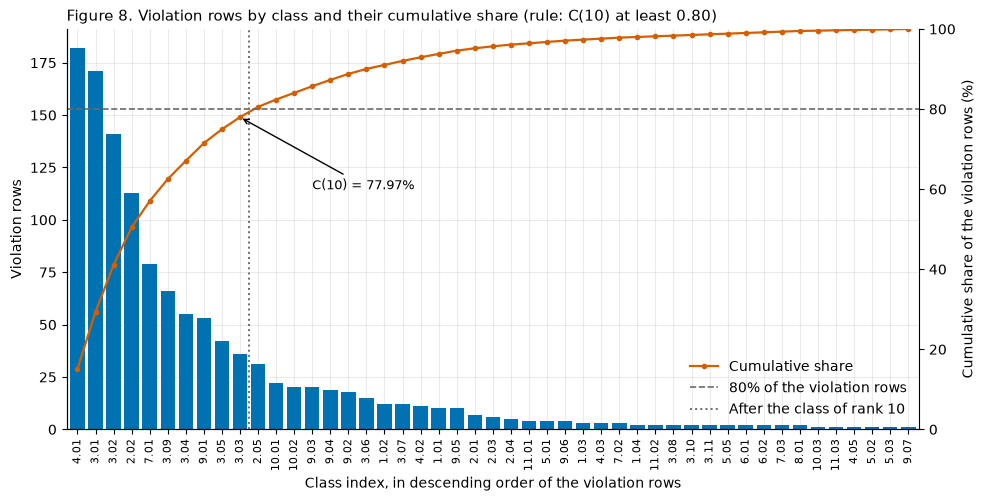

In [25]:
h1a_shown = conc[conc["rows_violation"] > 0]
h1a_x = h1a_shown["rank"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar(h1a_x, h1a_shown["rows_violation"], color=C_BLUE, width=0.8)
ax.set_xticks(h1a_x)
ax.set_xticklabels(h1a_shown["class_index"], rotation=90, fontsize=8)
ax.set_xlim(0.4, len(h1a_shown) + 0.6)
ax.set_xlabel("Class index, in descending order of the violation rows")
ax.set_ylabel("Violation rows")

ax_cum = ax.twinx()
ax_cum.plot(h1a_x, h1a_shown["cum_share"] * 100, color=C_VERMILION, marker="o", markersize=3, linewidth=1.6, label="Cumulative share")
ax_cum.axhline(H1A_MIN_CUM_SHARE * 100, color=C_GREY, linestyle="--", linewidth=1.2, label=f"{H1A_MIN_CUM_SHARE:.0%} of the violation rows")
ax_cum.axvline(H1A_MAX_CLASSES + 0.5, color=C_GREY, linestyle=":", linewidth=1.4, label=f"After the class of rank {H1A_MAX_CLASSES}")
ax_cum.set_ylim(0, 100)
ax_cum.set_ylabel("Cumulative share of the violation rows (%)")
ax_cum.grid(False)
ax_cum.spines["right"].set_visible(True)
ax_cum.annotate(f"C({H1A_MAX_CLASSES}) = {h1a_c10:.2%}", xy=(H1A_MAX_CLASSES, h1a_c10 * 100), xytext=(H1A_MAX_CLASSES + 4, h1a_c10 * 100 - 18),
                arrowprops={"arrowstyle": "->", "color": "black"}, fontsize=9)
ax_cum.legend(frameon=False, loc="lower right")
ax.set_title(f"Figure 8. Violation rows by class and their cumulative share (rule: C({H1A_MAX_CLASSES}) at least {H1A_MIN_CUM_SHARE:.2f})", loc="left")
fig.savefig(FIG_DIR / "F8_class_concentration.png", bbox_inches="tight")
plt.show()

**Reading Figure 8.** Each bar is one of the 47 classes that have violation rows, labelled by the class index, and the six classes without violation rows are not drawn. The line is the cumulative share. The four largest bars (4.01, 3.01, 3.02 and 2.02) carry 607 rows, 0.5046 of all violation rows. The line crosses the 80 % line between the tenth and the eleventh bar: at the vertical line, after the tenth class, it stands at 0.7797, and at the eleventh class at 0.8055. After the eleventh class the bars are low and the line rises slowly; the last six drawn bars are single rows. The picture shows a concentration that is strong but just short of the rule.

#### 5.2.4 Violation rows by cited statute

**Question.** Under which statutes do the violation rows fall?

**Logic for a controller.** The column `law` of the table names the statute or statutes that the conclusion cites. The statutes are the Public Procurement Act (PPA; Bulgaria, 2016a), the Financial Management and Control in the Public Sector Act (FMCPSA; Bulgaria, 2006a), the Regulations for the Implementation of the Public Procurement Act (RIPPA; Bulgaria, 2016b) and the Tax and Social Insurance Procedure Code (TSIPC; Bulgaria, 2005). Each statute is counted in every row in which it is cited. A row that cites two statutes is counted for both, so the numbers add up to more than the 1,203 rows and the shares to more than 100 %. A row without a cited statute is counted as "no statute cited". This is a description of the recorded findings and not a test.

**What the next cell does.** It splits the cell of `law` into statutes, counts the violation rows of each statute, and gives the share of the 1,203 rows with the interval of Wilson and the interval of the cluster bootstrap, taken from the same replications as in 5.2.2. It writes `data/derived/violation_rows_by_statute.csv`. Under the table it gives the number of reports with at least one violation row, with its interval of Wilson; the number is also in `reconciliation_totals.csv`, and only the interval is new.

In [26]:
STATUTES = [("ЗОП", "PPA"), ("ЗФУКПС", "FMCPSA"), ("ППЗОП", "RIPPA"), ("ДОПК", "TSIPC")]
STATUTE_NONE = ("не е цитиран закон", "no statute cited")

law_tokens = viol["law"].fillna("").str.split(",").apply(lambda parts: {part.strip() for part in parts if part.strip()})
assert set().union(*law_tokens) <= {bg for bg, en in STATUTES}

stat_rows = []
for statute_bg, statute_en in [*STATUTES, STATUTE_NONE]:
    if statute_bg == STATUTE_NONE[0]:
        stat_mask = law_tokens.apply(len).eq(0).to_numpy()
    else:
        stat_mask = law_tokens.apply(lambda tokens, name=statute_bg: name in tokens).to_numpy()
    stat_count = int(stat_mask.sum())
    stat_boot = (h1a_weights @ np.bincount(h1a_codes, weights=stat_mask, minlength=h1a_clusters)) / h1a_boot_total
    stat_wilson = wilson_interval(stat_count, h1a_rows_total)
    stat_rows.append([statute_bg, statute_en, stat_count, stat_count / h1a_rows_total, float(stat_wilson[0]), float(stat_wilson[1]),
                      float(np.quantile(stat_boot, 0.025)), float(np.quantile(stat_boot, 0.975))])

violation_rows_by_statute = pd.DataFrame(stat_rows, columns=["statute_bg", "statute_en", "rows", "share", "share_ci_low", "share_ci_high",
                                                            "cluster_ci_low", "cluster_ci_high"])
assert violation_rows_by_statute["rows"].tolist() == [1094, 43, 56, 9, 17]
rows_with_two_statutes = int((law_tokens.apply(len) > 1).sum())
assert int(violation_rows_by_statute["rows"].sum()) == h1a_rows_total + rows_with_two_statutes

for column in ("share", "share_ci_low", "share_ci_high", "cluster_ci_low", "cluster_ci_high"):
    violation_rows_by_statute[column] = violation_rows_by_statute[column].round(4)
violation_rows_by_statute.to_csv(DERIVED_DIR / "violation_rows_by_statute.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

n_reports_violation = viol["report_key"].nunique()
n_reports_total = len(meta_df)
assert (n_reports_violation, n_reports_total) == (410, 560)
reports_wilson = wilson_interval(n_reports_violation, n_reports_total)

print(f"Violation rows: {h1a_rows_total} | rows that cite two statutes: {rows_with_two_statutes} | sum of the counts: {int(violation_rows_by_statute['rows'].sum())}")
with pd.option_context("display.max_colwidth", None):
    display(violation_rows_by_statute)
print(f"Reports with at least one violation row: {n_reports_violation} of {n_reports_total} ({n_reports_violation / n_reports_total:.4f}) | interval of Wilson [{reports_wilson[0]:.4f}; {reports_wilson[1]:.4f}]")

Violation rows: 1203 | rows that cite two statutes: 16 | sum of the counts: 1219


,statute_bg,statute_en,rows,share,share_ci_low,share_ci_high,cluster_ci_low,cluster_ci_high
0,ЗОП,PPA,1094,0.9094,0.8918,0.9243,0.8770,0.9373
1,ЗФУКПС,FMCPSA,43,0.0357,0.0266,0.0478,0.0146,0.0614
2,ППЗОП,RIPPA,56,0.0466,0.0360,0.0600,0.0295,0.0683
3,ДОПК,TSIPC,9,0.0075,0.0039,0.0142,0.0017,0.0159
4,не е цитиран закон,no statute cited,17,0.0141,0.0088,0.0225,0.0051,0.0263


Reports with at least one violation row: 410 of 560 (0.7321) | interval of Wilson [0.6940; 0.7671]


**Reading the table.** One line is one statute. The PPA is cited in 1,094 of the 1,203 violation rows (0.9094; interval of Wilson [0.8918; 0.9243]; cluster bootstrap [0.8770; 0.9373]). The RIPPA is cited in 56 rows (0.0466), the FMCPSA in 43 rows (0.0357) and the TSIPC in 9 rows (0.0075); 17 rows (0.0141) cite no statute. The counts add up to 1,219, which is 16 more than the 1,203 rows, because 16 rows cite two statutes. The bootstrap intervals of the small statutes are wider than the intervals of Wilson (for the FMCPSA [0.0146; 0.0614] against [0.0266; 0.0478]), because the interval of Wilson treats the rows as independent and the bootstrap does not. 410 of the 560 reports (0.7321; interval of Wilson [0.6940; 0.7671]) have at least one violation row. These are the statutes that the conclusions cite, not a count of the provisions that were broken, and a share of a sample of reports is not the frequency of violations in procurements that were not inspected.

#### 5.2.5 How robust is the result to the unit?

**Question.** Does the decision on H1a depend on what is counted as one unit?

**Logic for a controller.** A report can record the same type of action in several items or criteria of one inspection, and each of them is a violation row. Counting every class once per report, the unit "report × class", asks in how many inspections a type occurs and not how many rows it has. A second variation keeps only the violation rows with an act. This check was **not fixed before the computation**. It was added after the result of Section 5.2.2 was known, and it is an additional check (a sensitivity check). The decision on H1a stays the one of Section 5.2.2: **rejected**. The rule of Section 1.2.1 and the unit of Section 1.1.2 are not changed, and the first line of the table is the decision.

**What the next cell does.** It computes $C(10)$ and `classes_for_80pct` for three units in the same way as in Section 5.2.2 (the classes are ordered by the number, a tie by the class index): the violation rows (the unit of H1a), the violation rows with an act only, and the pairs report × class. It compares each value with the 0.80 of the rule, checks the numbers and writes `data/derived/h1a_sensitivity.csv`. There is no bootstrap in this check.

In [27]:
def concentration_of(frame):
    counts = frame.groupby("class_index").size().rename("n").reset_index()
    counts = counts.sort_values(["n", "class_index"], ascending=[False, True]).reset_index(drop=True)
    total = int(counts["n"].sum())
    top_rows = int(counts["n"].iloc[:H1A_MAX_CLASSES].sum())
    needed = int((counts["n"].cumsum() >= H1A_MIN_CUM_SHARE * total).idxmax() + 1)
    return total, top_rows, top_rows / total, needed


SENSITIVITY_UNITS = [
    ("violation rows (the unit of H1a)", viol, "decision (fixed before computation)"),
    ("violation rows with an act only", viol[viol["outcome"] == "violation_with_act"], "sensitivity (added after the result)"),
    ("report × class (each class counted once per report)", viol.drop_duplicates(["report_key", "class_index"]), "sensitivity (added after the result)"),
]
sensitivity_records = []
sensitivity_top_rows = []
for unit_name, unit_frame, unit_role in SENSITIVITY_UNITS:
    unit_total, unit_top_rows, unit_c10, unit_needed = concentration_of(unit_frame)
    sensitivity_top_rows.append(unit_top_rows)
    sensitivity_records.append({
        "unit": unit_name,
        "n": unit_total,
        "c10": unit_c10,
        "classes_for_80pct": unit_needed,
        "meets_threshold": bool(unit_c10 >= H1A_MIN_CUM_SHARE),
        "role": unit_role,
    })
h1a_sensitivity = pd.DataFrame(sensitivity_records)

assert h1a_sensitivity["n"].tolist() == [1203, 1148, 1095]
assert sensitivity_top_rows == [938, 897, 893]
assert h1a_sensitivity["c10"].round(4).tolist() == [0.7797, 0.7814, 0.8155]
assert h1a_sensitivity["classes_for_80pct"].tolist() == [11, 11, 10]
assert h1a_sensitivity["meets_threshold"].tolist() == [False, False, True]
assert (h1a_sensitivity.loc[0, "c10"], h1a_sensitivity.loc[0, "classes_for_80pct"]) == (h1a_c10, h1a_classes_for_80pct)
assert h1a_sensitivity["meets_threshold"].tolist() == (h1a_sensitivity["classes_for_80pct"] <= H1A_MAX_CLASSES).tolist()

h1a_sensitivity["c10"] = h1a_sensitivity["c10"].round(4)
h1a_sensitivity.to_csv(DERIVED_DIR / "h1a_sensitivity.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

with pd.option_context("display.max_colwidth", None):
    display(h1a_sensitivity)

,unit,n,c10,classes_for_80pct,meets_threshold,role
0,violation rows (the unit of H1a),1203,0.7797,11,False,decision (fixed before computation)
1,violation rows with an act only,1148,0.7814,11,False,sensitivity (added after the result)
2,report × class (each class counted once per report),1095,0.8155,10,True,sensitivity (added after the result)


**Reading the table.** H1a is rejected by the rule that was fixed in advance: for the violation rows $C(10)=0.7797$ and 11 classes are needed. The variation with an act only gives 0.7814 and 11 classes, and it does not reach the threshold either. When each class is counted once per report, the threshold is reached: $C(10)=0.8155$ with 10 classes. So the conclusion that the violation rows are strongly concentrated holds for all three units, and the decision by the threshold of 80 % depends on the unit. For the unit of H1a, $C(10)$ is near the threshold: the interval of Section 5.2.2 [0.7436; 0.8210] contains 0.80, and in 0.1995 of the replications $C(10)\ge 0.80$. Separately, for report × class the point value is above the threshold; there is no bootstrap for this unit, and nothing is said about its uncertainty. The decision does not change, because the rule and the unit were fixed before the computation. The shares are an **indicator** of where control attention could be placed, the reports are a sample of the inspections, and a share of them is not the frequency of violations in procurements that were not inspected.

### (3) Limits

#### 5.3.1 What the concentration does and does not show

- The unit is the row: a finding with several classes is counted once in each of its classes, so the violation rows are not the same as the violations. H1a is defined on rows in Section 1.1.2.
- The threshold (10 of 53 classes and 80 %) is a convention of the author, fixed before the computation. It names a level of concentration at which a control point on a handful of types would be practical; it is not a statistical law.
- The interval of Wilson treats the rows as independent. The bootstrap by report does not, because it resamples whole reports, but it takes the selection of the reports as given and does not correct it.
- The reports are a sample of the inspections. A share describes the recorded findings of these reports, not the probability of a violation in procurements that were not inspected.
- The check of the robustness in Section 5.2.5 was chosen after the result was known. It does not change the decision on H1a.
- The concentration is an **indicator** of where control attention could be placed. It is not a proven violation and not an assessment of a school or a directorate.

## 6. Question 2: Differences between the Directorates

### (1) Question Addressed

#### 6.1.1 Is the same type of action recorded as a violation equally often in all directorates?

**Question.** For one class of the classifier, does the share of violations among the inspected units differ between the seven directorates `FID1`–`FID7`?

**Logic for a controller.** This is Question 2 of Section 1.1.3 and H1b of Section 1.2.1. The seven directorates inspect different schools. If the share of one type of action that ends in a violation differs between directorates, the reason may be a different practice of the schools, a different composition of the inspected procurements, or a different reading of the same text by the inspectors; the data cannot tell these apart. The result is therefore an **indicator** that deserves a look, not a verdict on a directorate. The question is asked for each class separately, and its unit is the pair report × class, not the row.

### (2) Method: the Unit, the Test and the Adjustment

#### 6.2.1 The unit and the eligible classes

**Question.** What is one unit, and which classes can be tested?

**Logic for a controller.** The unit is one pair (report, class), as in Section 1.1.3. Its outcome is **violation** if the pair has at least one row with a violation, and **no violation** if all its rows record no violation. A report can record the same class in several items of one inspection, with a violation in one item and no violation in another. Such a pair has both kinds of rows and is counted as a violation. This rule is part of the definition of the unit; Section 1.1.3 does not state it, and the number of such pairs is shown separately as `mixed_units`. A class is **eligible** if it has at least `H1b_min_units_per_outcome` units (10, Section 1.3.2) in each of the two outcomes, the condition of Section 1.2.1. A class with only one outcome cannot be tested, and the table of a class with fewer units is too thin for the test.

**What the next cell does.** It gives each report its directorate from `meta_df`, groups the rows of the classification table into units, and counts for each class the units with a violation, the units without a violation and the mixed units. It lists the classes that have both outcomes, marks the eligible ones and checks the totals.

In [28]:
H1B_MIN_UNITS = HYPOTHESIS_THRESHOLDS["H1b_min_units_per_outcome"]
H1B_DIRECTORATES = [f"FID{h1b_i}" for h1b_i in range(1, 8)]

h1b_rows = cls_df[["report_key", "class_index", "is_violation"]].copy()
h1b_rows["directorate"] = h1b_rows["report_key"].map(dict(zip(meta_df["report_key"], meta_df["directorate_en"])))
assert h1b_rows["directorate"].notna().all()
assert set(h1b_rows["directorate"]) <= set(H1B_DIRECTORATES)
h1b_rows["is_no_violation"] = ~h1b_rows["is_violation"]

h1b_units = h1b_rows.groupby(["report_key", "directorate", "class_index"], as_index=False).agg(
    n_viol_rows=("is_violation", "sum"), n_noviol_rows=("is_no_violation", "sum"))
h1b_units["has_violation"] = h1b_units["n_viol_rows"] > 0
h1b_units["mixed"] = h1b_units["has_violation"] & (h1b_units["n_noviol_rows"] > 0)

h1b_by_class = h1b_units.groupby("class_index").agg(
    units_viol=("has_violation", "sum"), units=("has_violation", "size"), mixed_units=("mixed", "sum")).reset_index()
h1b_by_class["units_noviol"] = h1b_by_class["units"] - h1b_by_class["units_viol"]
h1b_both = h1b_by_class[(h1b_by_class["units_viol"] > 0) & (h1b_by_class["units_noviol"] > 0)].copy()
h1b_both["eligible"] = (h1b_both["units_viol"] >= H1B_MIN_UNITS) & (h1b_both["units_noviol"] >= H1B_MIN_UNITS)
h1b_both = h1b_both.merge(classes[["class_index", "class_en"]], on="class_index", how="left")
h1b_both = h1b_both.sort_values("class_index", key=lambda h1b_s: h1b_s.map(lambda h1b_c: tuple(int(h1b_t) for h1b_t in h1b_c.split(".")))).reset_index(drop=True)

h1b_eligible = h1b_both.loc[h1b_both["eligible"], "class_index"].tolist()
h1b_mixed_total = int(h1b_units["mixed"].sum())
h1b_mixed_classes = int(h1b_units.loc[h1b_units["mixed"], "class_index"].nunique())

assert len(h1b_units) == 1643
assert len(h1b_both) == 29
assert (h1b_mixed_total, h1b_mixed_classes) == (15, 7)
assert h1b_eligible == ["2.02", "2.05", "3.02", "3.03", "4.01", "7.01"]

print(f"Units: {len(h1b_units)} | classes with both outcomes: {len(h1b_both)} | mixed units: {h1b_mixed_total} in {h1b_mixed_classes} classes | eligible classes: {len(h1b_eligible)} {h1b_eligible}")
with pd.option_context("display.max_colwidth", None):
    display(h1b_both[["class_index", "class_en", "units_viol", "units_noviol", "mixed_units", "eligible"]])

Units: 1643 | classes with both outcomes: 29 | mixed units: 15 in 7 classes | eligible classes: 6 ['2.02', '2.05', '3.02', '3.03', '4.01', '7.01']


,class_index,class_en,units_viol,units_noviol,mixed_units,eligible
0,1.01,Splitting of procurements,10,4,0,False
1,1.02,Direct award at a value requiring a call or procedure,8,4,0,False
2,1.03,Invitation to specific persons or direct negotiation without legal basis,3,1,0,False
3,2.01,Market consultations without disclosure,7,41,0,False
4,2.02,Heterogeneous supplies in a procurement without lots,110,77,7,True
5,2.03,Heterogeneous supplies in a single lot of a divided procurement,6,33,1,False
6,2.04,Tailored specifications – brand or model specified,5,13,0,False
7,2.05,Omitted environmental requirements for products,31,26,0,True
8,3.01,Requirement for own service base or support system,162,3,2,False
9,3.02,"Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1)",137,24,2,True


**Reading the table.** The rows of the classification table form 1,643 units. The 29 classes that have both outcomes hold 1,457 of them. The other 21 classes that have rows have one outcome only and cannot be tested. Six of the 29 classes are eligible: 2.02, 2.05, 3.02, 3.03, 4.01 and 7.01, with 187, 57, 161, 100, 204 and 87 units. The class closest to the threshold is 7.01, with 14 units without a violation. The other 23 classes fail the threshold of 10 in one outcome; class 3.01, for example, has 162 units with a violation and 3 without. There are 15 mixed units in 7 classes (2.02, 2.03, 3.01, 3.02, 4.01, 7.01 and 9.06), and 11 of them are in four of the eligible classes: 7 in 2.02, 2 in 3.02, 1 in 4.01 and 1 in 7.01. They are counted as violations, as the definition of the unit says.

#### 6.2.2 The permutation test and the adjustment

**Question.** In each eligible class, does the share of violations differ between the directorates by more than chance would give, and how large is the difference?

**Logic for a controller.** The notation and the formulas are those of Section 1.1.3: $O_{ij}$, $E_{ij}$, $N$, $\chi^2$, $R$, $p$, $q$ and $V$. For one class the table has two rows (violation and no violation) and one column for each directorate that has at least one unit in the class; $r$ is the number of these directorates. The directorate labels are shuffled over the units of the class while the outcomes stay fixed, $R=10{,}000$ times (`H1b_permutations`), and $p=(1+b)/(R+1)$, where $b$ is the number of shuffles with $\chi^{2*}\ge\chi^2_{\text{obs}}$ (Pearson, 1900; Phipson and Smyth, 2010). The p-values of the eligible classes are adjusted together by the Benjamini–Hochberg procedure (Benjamini and Hochberg, 1995). The size of a difference is Cramér's V (Cramér, 1946); with two outcomes, $V=\sqrt{\chi^2/(N\min(r-1,\,1))}$, which is $\sqrt{\chi^2/N}$ when $r\ge 2$.

**Decision rule.** H1b is confirmed if $q<0.05$ (`H1b_fdr_alpha`) for at least one eligible class. One generator, `rng_h1b`, initialised with 20261119, serves all classes, taken in the order of the class index, so that the p-values can be reproduced. The table also counts the cells with $E_{ij}<5$. They show where the large-sample approximation of $\chi^2$ would be doubtful, which is why the p-value comes from the shuffles.

**What the next cell does.** For each eligible class it computes $\chi^2$, $p$ and $V$ and counts the cells with $E_{ij}<5$. Then it adjusts the p-values to $q$, marks the classes with $q<0.05$, decides H1b, checks the numbers that do not depend on the shuffles and writes `data/derived/heterogeneity_by_class.csv`.

In [29]:
H1B_R = HYPOTHESIS_THRESHOLDS["H1b_permutations"]
H1B_ALPHA = HYPOTHESIS_THRESHOLDS["H1b_fdr_alpha"]
rng_h1b = np.random.default_rng(20261119)


def h1b_chi2(outcome, group, totals, expected_viol, expected_noviol):
    observed_viol = np.bincount(group[outcome == 1], minlength=totals.size).astype(float)
    observed_noviol = totals - observed_viol
    return float(np.sum((observed_viol - expected_viol) ** 2 / expected_viol + (observed_noviol - expected_noviol) ** 2 / expected_noviol))


h1b_records = []
h1b_chi2_values = []
h1b_v_values = []
h1b_p_values = []
for h1b_class in h1b_eligible:
    h1b_sub = h1b_units[h1b_units["class_index"] == h1b_class]
    h1b_present = [h1b_d for h1b_d in H1B_DIRECTORATES if (h1b_sub["directorate"] == h1b_d).any()]
    h1b_outcome = h1b_sub["has_violation"].to_numpy(dtype=int)
    h1b_group = h1b_sub["directorate"].map({h1b_d: h1b_j for h1b_j, h1b_d in enumerate(h1b_present)}).to_numpy(dtype=int)
    h1b_totals = np.bincount(h1b_group, minlength=len(h1b_present)).astype(float)
    h1b_n = len(h1b_sub)
    h1b_n_viol = int(h1b_outcome.sum())
    h1b_e_viol = h1b_totals * h1b_n_viol / h1b_n
    h1b_e_noviol = h1b_totals * (h1b_n - h1b_n_viol) / h1b_n

    h1b_observed = h1b_chi2(h1b_outcome, h1b_group, h1b_totals, h1b_e_viol, h1b_e_noviol)
    h1b_at_least = 0
    for h1b_step in range(H1B_R):
        if h1b_chi2(h1b_outcome, rng_h1b.permutation(h1b_group), h1b_totals, h1b_e_viol, h1b_e_noviol) >= h1b_observed - 1e-12:
            h1b_at_least += 1
    h1b_p = (1 + h1b_at_least) / (H1B_R + 1)
    h1b_v = float(np.sqrt(h1b_observed / (h1b_n * min(len(h1b_present) - 1, 1))))

    h1b_record = {
        "class_index": h1b_class,
        "class_en": classes.loc[classes["class_index"] == h1b_class, "class_en"].iloc[0],
        "n": h1b_n,
        "n_viol": h1b_n_viol,
        "n_noviol": h1b_n - h1b_n_viol,
        "mixed_units": int(h1b_sub["mixed"].sum()),
    }
    for h1b_d in H1B_DIRECTORATES:
        h1b_in_d = h1b_sub[h1b_sub["directorate"] == h1b_d]
        h1b_record[f"{h1b_d}_viol"] = int(h1b_in_d["has_violation"].sum())
        h1b_record[f"{h1b_d}_total"] = len(h1b_in_d)
    h1b_record["cells_expected_below_5"] = int((h1b_e_viol < 5).sum() + (h1b_e_noviol < 5).sum())
    h1b_records.append(h1b_record)
    h1b_chi2_values.append(h1b_observed)
    h1b_v_values.append(h1b_v)
    h1b_p_values.append(h1b_p)

h1b_p_array = np.array(h1b_p_values)
h1b_m = len(h1b_p_array)
h1b_order = np.argsort(h1b_p_array, kind="stable")
h1b_scaled = h1b_p_array[h1b_order] * h1b_m / np.arange(1, h1b_m + 1)
h1b_q_sorted = np.clip(np.minimum.accumulate(h1b_scaled[::-1])[::-1], 0.0, 1.0)
h1b_q_array = np.empty(h1b_m)
h1b_q_array[h1b_order] = h1b_q_sorted

h1b_table = pd.DataFrame(h1b_records)
h1b_cells_below_5 = h1b_table.pop("cells_expected_below_5")
h1b_table["chi2"] = [round(h1b_x, 4) for h1b_x in h1b_chi2_values]
h1b_table["p_perm"] = [round(h1b_x, 6) for h1b_x in h1b_p_values]
h1b_table["q_bh"] = [round(float(h1b_x), 6) for h1b_x in h1b_q_array]
h1b_table["cramers_v"] = [round(h1b_x, 4) for h1b_x in h1b_v_values]
h1b_table["cells_expected_below_5"] = h1b_cells_below_5
h1b_table["significant"] = h1b_q_array < H1B_ALPHA

h1b_significant = h1b_table.loc[h1b_table["significant"], "class_index"].tolist()
h1b_confirmed = bool((h1b_q_array < H1B_ALPHA).any())

assert h1b_table["n"].tolist() == [187, 57, 161, 100, 204, 87]
assert h1b_table["n_viol"].tolist() == [110, 31, 137, 36, 170, 73]
assert h1b_table["chi2"].tolist() == [37.1459, 11.9230, 34.3484, 18.3843, 7.5307, 11.4485]
assert h1b_table["cramers_v"].tolist() == [0.4457, 0.4574, 0.4619, 0.4288, 0.1921, 0.3628]
assert h1b_table["cells_expected_below_5"].tolist() == [2, 12, 7, 6, 3, 9]
assert (h1b_p_array >= 1 / (H1B_R + 1) - 1e-15).all() and (h1b_p_array <= 1).all()
assert (np.diff(h1b_q_sorted) >= -1e-15).all() and (h1b_q_array >= h1b_p_array - 1e-15).all() and (h1b_q_array <= 1).all()
assert h1b_confirmed == (len(h1b_significant) > 0)

h1b_table.to_csv(DERIVED_DIR / "heterogeneity_by_class.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

print(f"H1b: {h1b_m} eligible classes tested | q < {H1B_ALPHA} in {len(h1b_significant)} {h1b_significant} | H1b_confirmed = {h1b_confirmed}")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None, "display.width", 250):
    display(h1b_table)

H1b: 6 eligible classes tested | q < 0.05 in 3 ['2.02', '3.02', '3.03'] | H1b_confirmed = True


,class_index,class_en,n,n_viol,n_noviol,mixed_units,FID1_viol,FID1_total,FID2_viol,FID2_total,FID3_viol,FID3_total,FID4_viol,FID4_total,FID5_viol,FID5_total,FID6_viol,FID6_total,FID7_viol,FID7_total,chi2,p_perm,q_bh,cramers_v,cells_expected_below_5,significant
0,2.02,Heterogeneous supplies in a procurement without lots,187,110,77,7,5,17,2,8,24,30,18,45,19,24,26,30,16,33,37.1459,0.000100,0.000300,0.4457,2,True
1,2.05,Omitted environmental requirements for products,57,31,26,0,5,7,1,2,5,7,4,7,4,16,8,9,4,9,11.9230,0.056094,0.084142,0.4574,12,False
2,3.02,"Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1)",161,137,24,2,4,10,2,4,31,34,25,25,29,29,22,26,24,33,34.3484,0.000100,0.000300,0.4619,7,True
3,3.03,"Quality, environmental, or occupational health and safety certificate required from the tenderer (ISO 9001, 14001, 45001)",100,36,64,0,1,9,0,5,8,21,11,24,1,6,10,13,5,22,18.3843,0.003800,0.007599,0.4288,6,True
4,4.01,"Requirements for the content of the technical proposal (work program, strategy, risk management approach) as a condition for admission",204,170,34,1,11,15,5,6,28,38,41,44,35,43,25,30,25,28,7.5307,0.267973,0.267973,0.1921,3,False
5,7.01,Contract concluded without documents or without a fulfilled condition,87,73,14,1,3,3,1,1,19,20,12,14,3,7,17,20,18,22,11.4485,0.080492,0.096590,0.3628,9,False


**Reading the table.** Three of the six classes have $q<0.05$: 2.02 ($\chi^2=37.1459$, $V=0.4457$, $q=0.0003$), 3.02 ($\chi^2=34.3484$, $V=0.4619$, $q=0.0003$) and 3.03 ($\chi^2=18.3843$, $V=0.4288$, $q=0.0076$). In 2.02 and 3.02 none of the 10,000 shuffles reached the observed $\chi^2$, so $p$ has its smallest possible value, $1/10{,}001\approx 0.0001$. The other three classes do not reach the level: 2.05 ($p=0.0561$, $q=0.0841$), 7.01 ($p=0.0805$, $q=0.0966$) and 4.01 ($p=0.2680$, $q=0.2680$, $V=0.1921$); in 4.01 the share of violations is high in every directorate, from 73 % to 93 %. The $V$ of 2.05 (0.4574) is as large as in the three significant classes, but its table has 57 units, and with that few units the shuffles do not reject. By the rule of Section 1.2.1, H1b is **confirmed**: in at least one eligible class the share of violations differs between the directorates. The column `cells_expected_below_5` counts, out of 14 cells, those with $E_{ij}<5$: 2 in 2.02, 12 in 2.05, 7 in 3.02, 6 in 3.03, 3 in 4.01 and 9 in 7.01. The result is an **indicator** of a difference in the recorded findings, not a statement about the cause or about a directorate.

#### 6.2.3 The differences in a figure

**What the next cell does.** It draws Figure 9, one panel for each class with $q<0.05$. A bar is the share of the units with a violation in one directorate, and the line on it is the Wilson interval of that share (Wilson, 1927), the formula of Section 1.2.2. Under each bar are the directorate and its number of units $n$ in the class. The title of a panel gives the class and its $q$.

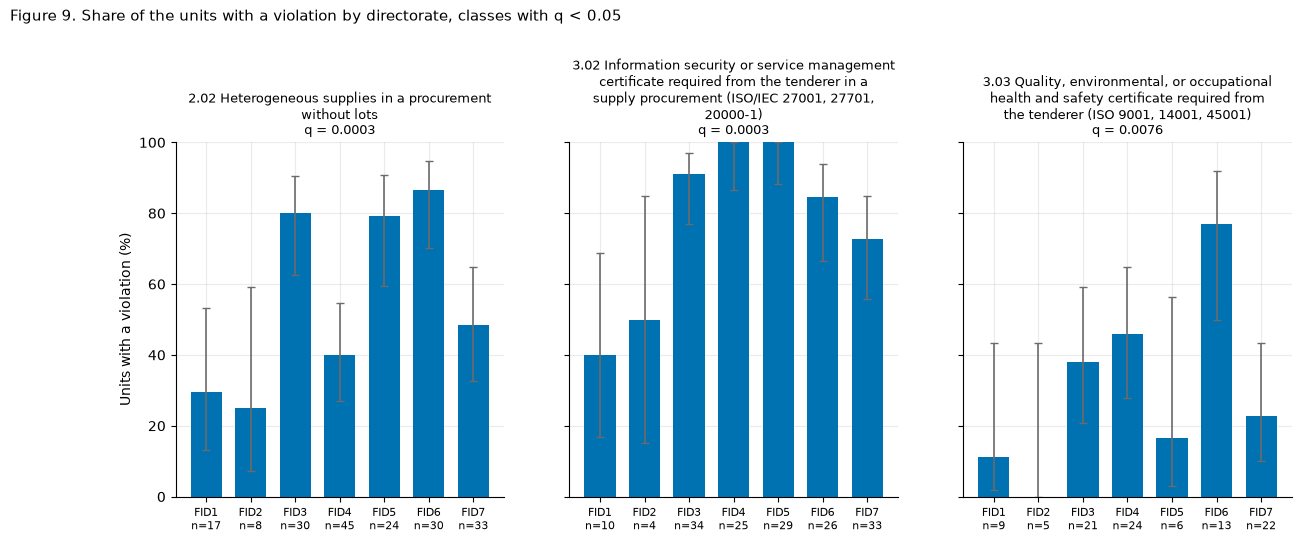

In [30]:
h1b_sig = h1b_table[h1b_table["significant"]]
h1b_fig, h1b_axes = plt.subplots(1, len(h1b_sig), figsize=(4.8 * len(h1b_sig), 4.6), sharey=True)
h1b_axes = np.atleast_1d(h1b_axes)
h1b_x = np.arange(len(H1B_DIRECTORATES))
for h1b_ax, h1b_row in zip(h1b_axes, h1b_sig.to_dict("records")):
    h1b_k = np.array([h1b_row[f"{h1b_d}_viol"] for h1b_d in H1B_DIRECTORATES])
    h1b_t = np.array([h1b_row[f"{h1b_d}_total"] for h1b_d in H1B_DIRECTORATES])
    assert (h1b_t > 0).all()
    h1b_share = h1b_k / h1b_t
    h1b_low, h1b_high = wilson_interval(h1b_k, h1b_t)
    h1b_ax.bar(h1b_x, h1b_share * 100, color=C_BLUE, width=0.7)
    h1b_ax.errorbar(h1b_x, h1b_share * 100, yerr=[(h1b_share - h1b_low) * 100, (h1b_high - h1b_share) * 100], fmt="none", ecolor=C_GREY, capsize=3, linewidth=1.2)
    h1b_ax.set_xticks(h1b_x)
    h1b_ax.set_xticklabels([f"{h1b_d}\nn={h1b_n}" for h1b_d, h1b_n in zip(H1B_DIRECTORATES, h1b_t)], fontsize=8)
    h1b_ax.set_ylim(0, 100)
    h1b_ax.set_title(f"{h1b_row['class_index']} {textwrap.fill(h1b_row['class_en'], 44)}\nq = {h1b_row['q_bh']:.4f}", fontsize=9)
h1b_axes[0].set_ylabel("Units with a violation (%)")
h1b_fig.suptitle(f"Figure 9. Share of the units with a violation by directorate, classes with q < {H1B_ALPHA}", x=0.01, ha="left", y=1.17, fontsize=11)
h1b_fig.savefig(FIG_DIR / "F9_directorate_shares.png", bbox_inches="tight")
plt.show()

**Reading Figure 9.** Each panel is one of the three classes with $q<0.05$, in the order of the class index. In 2.02 the share of units with a violation is 80 % in `FID3`, 79 % in `FID5` and 87 % in `FID6`, against 29 % in `FID1`, 25 % in `FID2`, 40 % in `FID4` and 48 % in `FID7`. In 3.02 every unit of `FID4` (25 of 25) and of `FID5` (29 of 29) has a violation, and `FID3` has 91 % (31 of 34), while `FID1` has 40 % (4 of 10) and `FID2` 50 % (2 of 4). In 3.03 the highest share is 77 % in `FID6` (10 of 13), and the lowest are 0 % in `FID2` (0 of 5), 11 % in `FID1` (1 of 9) and 17 % in `FID5` (1 of 6). The Wilson intervals of the small directorates are wide: `FID2` has only 8, 4 and 5 units in the three classes. The panels show where the shares differ and not why; they are an **indicator** and not a statement that a directorate is right or wrong.

### (3) Limits

#### 6.3.1 What the test does and does not show

- The difference is an **indicator**. It shows that the share of violations differs between directorates in a class. It does not say that a directorate is right or wrong, and it is not an assessment of any directorate.
- The test does not separate a different practice of the schools, a different composition of the inspected procurements and a different reading of the text by the inspectors (Section 1.1.3).
- Several directorates have few units in a class. Many cells have an expected count $E_{ij}<5$, most of all in `FID2`, and the power of the test is low for differences that rest on a small directorate. The p-value comes from the shuffles and does not rely on the large-sample approximation, but a small table still carries little information.
- A pair report × class with both kinds of rows is counted as a violation (Section 6.2.1). The unit therefore says that a type of action was recorded as a violation at least once in a report, not how often.
- The reports are a sample of the inspections. A share describes the recorded findings of these reports, not the probability of a violation in procurements that were not inspected.
- Only 6 of the 29 classes that have both outcomes were eligible and tested. For the other classes the study says nothing about the differences between the directorates.

## 7. Findings on Ex-Ante Control (Classifier Section 10)

### (1) Question Addressed

#### 7.1.1 How many violation rows concern ex-ante control and the double signature, and are they separate from the procurement rules?

**Question.** How many of the 1,203 violation rows fall in section 10 of the classifier (classes `10.01`–`10.04`), in how many reports do they occur, how often is an act attached, and are these findings separate from the findings under the procurement rules?

**Logic for a controller.** Section 10 gathers the findings on financial management and control: a commitment or a payment made without ex-ante control (`10.01`), without the double signature (`10.02`) or without an established procedure for ex-ante control (`10.03`), and the unperformed ex-ante control for the legality of a procurement above the threshold (`10.04`). These findings are not about how a procurement was run but about whether the control over the money was done, so a controller wants to know whether they are kept apart from the findings under the procurement rules. For this part Section 1.2.1 states **no hypothesis and no threshold**. The part describes the recorded findings and takes no decision. The counts are an **indicator** of what the inspectors recorded, not proof of a violation, and the reports are a sample of the inspections.

### (2) Method: the Classes, the Counts and the Check of the Separation

#### 7.2.1 The four classes and their separation from the procurement rules

**Question.** What does each class of section 10 count, and how is it shown that these rows are separate from the rows under the procurement rules?

**Logic for a controller.** The classifier ties each class to provisions (Section 3.2.3). Class `10.01` rests on Art. 13(3), item 3 of the FMCPSA (Bulgaria, 2006a), class `10.02` on Art. 13(3), item 1 of the FMCPSA, and class `10.03` on Art. 13(1) in conjunction with Art. 13(3), item 3 and Art. 13(4) of the FMCPSA. Class `10.04` rests on Art. 237b of the PPA (Bulgaria, 2016a) in conjunction with Art. 13(3), item 3 of the FMCPSA and Art. 19a(2), item 9 of the RIPPA (Bulgaria, 2016b). For each class the table counts the violation rows, split into rows with an act and rows without an act, the share of rows with an act with its interval of Wilson (Wilson, 1927), the reports with a violation row, and the no-violation rows and reports. A share of rows with an act is not defined for a class without violation rows and is shown as "—". The share of section 10 in the 1,203 violation rows and its intervals are not measured again: they are taken from the FMCPSA line of Section 5.2.4, after a check that this line has the same 43 rows. The separation is shown by four counts that must all be zero: the violation rows of section 10 that cite another statute than the FMCPSA in the column `law`; the violation rows outside section 10 that cite the FMCPSA in `law`; the violation rows outside section 10 that name the FMCPSA in `provisions`; and the findings of section 10 that have a row in another class.

**What the next cell does.** It selects the violation rows and the no-violation rows of the classes `10.01`–`10.04`, builds the table by class and writes `data/derived/ex_ante_control_by_class.csv` without act numbers, school names or report keys. It prints the totals, compares the 43 rows with the FMCPSA line of Section 5.2.4, runs the four counts of the separation, and counts the reports by the classes of section 10 that they contain. All the figures that the reading below uses are checked by `assert`.

In [31]:
S10_PREFIX = "10."
S10_LAW = "ЗФУКПС"

s10_classes = classes.loc[classes["class_index"].str.startswith(S10_PREFIX), ["class_index", "class_en"]].reset_index(drop=True)
s10_viol = viol[viol["class_index"].str.startswith(S10_PREFIX)]
s10_noviol = noviol[noviol["class_index"].str.startswith(S10_PREFIX)]
s10_outside = viol[~viol["class_index"].str.startswith(S10_PREFIX)]

s10_rows = []
for s10_index, s10_name in zip(s10_classes["class_index"], s10_classes["class_en"]):
    s10_v = s10_viol[s10_viol["class_index"] == s10_index]
    s10_n = s10_noviol[s10_noviol["class_index"] == s10_index]
    s10_with_act = int((s10_v["outcome"] == "violation_with_act").sum())
    s10_without_act = int((s10_v["outcome"] == "violation_without_act").sum())
    if len(s10_v) > 0:
        s10_low, s10_high = wilson_interval(s10_with_act, len(s10_v))
        s10_share, s10_low, s10_high = s10_with_act / len(s10_v), float(s10_low), float(s10_high)
    else:
        s10_share, s10_low, s10_high = np.nan, np.nan, np.nan
    s10_rows.append([s10_index, s10_name, len(s10_v), s10_with_act, s10_without_act, s10_share, s10_low, s10_high,
                     s10_v["report_key"].nunique(), len(s10_n), s10_n["report_key"].nunique()])

ex_ante_control_by_class = pd.DataFrame(s10_rows, columns=["class_index", "class_en", "rows_violation", "rows_with_act", "rows_without_act",
                                                          "act_share", "act_share_ci_low", "act_share_ci_high", "reports_violation",
                                                          "rows_no_violation", "reports_no_violation"])
for s10_column in ("act_share", "act_share_ci_low", "act_share_ci_high"):
    ex_ante_control_by_class[s10_column] = ex_ante_control_by_class[s10_column].round(4)

assert ex_ante_control_by_class["class_index"].tolist() == ["10.01", "10.02", "10.03", "10.04"]
assert ex_ante_control_by_class["rows_violation"].tolist() == [22, 20, 1, 0]
assert ex_ante_control_by_class["rows_with_act"].tolist() == [22, 19, 1, 0]
assert ex_ante_control_by_class["rows_without_act"].tolist() == [0, 1, 0, 0]
assert ex_ante_control_by_class["reports_violation"].tolist() == [7, 6, 1, 0]
assert ex_ante_control_by_class["rows_no_violation"].tolist() == [5, 5, 0, 0]
assert ex_ante_control_by_class["reports_no_violation"].tolist() == [4, 4, 0, 0]
assert ex_ante_control_by_class.loc[3, ["act_share", "act_share_ci_low", "act_share_ci_high"]].isna().all()
ex_ante_control_by_class.to_csv(DERIVED_DIR / "ex_ante_control_by_class.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

s10_rows_total = len(s10_viol)
s10_findings = s10_viol["finding_no"].nunique()
s10_reports = s10_viol["report_key"].nunique()
s10_with_act_total = int((s10_viol["outcome"] == "violation_with_act").sum())
s10_act_share = s10_with_act_total / s10_rows_total
s10_act_low, s10_act_high = wilson_interval(s10_with_act_total, s10_rows_total)
all_with_act_total = int((viol["outcome"] == "violation_with_act").sum())
all_act_share = all_with_act_total / len(viol)
all_act_low, all_act_high = wilson_interval(all_with_act_total, len(viol))

s10_statute = violation_rows_by_statute.set_index("statute_en").loc["FMCPSA"]
assert (int(s10_statute["rows"]), float(s10_statute["share"])) == (43, 0.0357)
assert (float(s10_statute["share_ci_low"]), float(s10_statute["share_ci_high"])) == (0.0266, 0.0478)
assert (float(s10_statute["cluster_ci_low"]), float(s10_statute["cluster_ci_high"])) == (0.0146, 0.0614)
assert int(s10_statute["rows"]) == s10_rows_total

s10_noviol_reports = set(s10_noviol["report_key"])
s10_all_reports = cls_df.loc[cls_df["class_index"].str.startswith(S10_PREFIX), "report_key"].nunique()
assert (s10_rows_total, s10_findings, s10_reports, n_reports_violation) == (43, 43, 11, 410)
assert (s10_with_act_total, s10_rows_total - s10_with_act_total) == (42, 1)
assert (len(s10_noviol), len(s10_noviol_reports), len(s10_noviol_reports & set(s10_viol["report_key"])), s10_all_reports) == (10, 4, 0, 15)
assert (all_with_act_total, len(viol)) == (1148, 1203)

s10_not_fmcpsa_law = int((s10_viol["law"] != S10_LAW).sum())
s10_outside_law = int(s10_outside["law"].fillna("").str.contains(S10_LAW).sum())
s10_outside_provisions = int(s10_outside["provisions"].fillna("").str.contains(S10_LAW).sum())
s10_split_findings = int((cls_df["finding_no"].isin(set(s10_viol["finding_no"])) & ~cls_df["class_index"].str.startswith(S10_PREFIX)).sum())
assert (s10_not_fmcpsa_law, s10_outside_law, s10_outside_provisions, s10_split_findings) == (0, 0, 0, 0)

s10_per_report = sorted(s10_viol.groupby("report_key").size().tolist(), reverse=True)
assert s10_per_report == [9, 7, 6, 4, 4, 3, 3, 3, 2, 1, 1]
assert sum(s10_per_report) == s10_rows_total
s10_cooccurrence = (s10_viol.groupby("report_key")["class_index"].apply(lambda s10_s: " + ".join(sorted(set(s10_s))))
                    .value_counts().rename_axis("classes_in_report").rename("reports").reset_index()
                    .sort_values(["reports", "classes_in_report"], ascending=[False, True]).reset_index(drop=True))
assert dict(zip(s10_cooccurrence["classes_in_report"], s10_cooccurrence["reports"])) == {"10.01": 4, "10.02": 3, "10.01 + 10.02": 3, "10.03": 1}

print(f"Section 10: {s10_rows_total} violation rows, {s10_findings} findings, {s10_reports} reports of {n_reports_violation} with a violation row | share of the {len(viol)} violation rows {s10_statute['share']:.4f} (row FMCPSA of 5.2.4)")
print(f"Interval of Wilson [{s10_statute['share_ci_low']:.4f}; {s10_statute['share_ci_high']:.4f}] | cluster bootstrap [{s10_statute['cluster_ci_low']:.4f}; {s10_statute['cluster_ci_high']:.4f}] (taken from 5.2.4)")
print(f"With act: section 10 {s10_with_act_total} of {s10_rows_total} ({s10_act_share:.4f}; Wilson [{s10_act_low:.4f}; {s10_act_high:.4f}]) | all violation rows {all_with_act_total} of {len(viol)} ({all_act_share:.4f}; Wilson [{all_act_low:.4f}; {all_act_high:.4f}])")
print(f"No-violation rows of section 10: {len(s10_noviol)} in {len(s10_noviol_reports)} reports, none of them among the {s10_reports} | reports with a row of section 10: {s10_all_reports}")
print(f"Separation: rows of section 10 with another statute in law: {s10_not_fmcpsa_law} | rows outside section 10 citing {S10_LAW} in law: {s10_outside_law}, in provisions: {s10_outside_provisions} | findings of section 10 with a row in another class: {s10_split_findings}")
print(f"Violation rows per report, in descending order: {s10_per_report} | the largest report {s10_per_report[0]} of {s10_rows_total} ({s10_per_report[0] / s10_rows_total:.4f}), the two largest {s10_per_report[0] + s10_per_report[1]}")
with pd.option_context("display.max_colwidth", None):
    display(ex_ante_control_by_class.astype(object).fillna("—"))
    display(s10_cooccurrence)

Section 10: 43 violation rows, 43 findings, 11 reports of 410 with a violation row | share of the 1203 violation rows 0.0357 (row FMCPSA of 5.2.4)
Interval of Wilson [0.0266; 0.0478] | cluster bootstrap [0.0146; 0.0614] (taken from 5.2.4)
With act: section 10 42 of 43 (0.9767; Wilson [0.8794; 0.9959]) | all violation rows 1148 of 1203 (0.9543; Wilson [0.9410; 0.9647])
No-violation rows of section 10: 10 in 4 reports, none of them among the 11 | reports with a row of section 10: 15
Separation: rows of section 10 with another statute in law: 0 | rows outside section 10 citing ЗФУКПС in law: 0, in provisions: 0 | findings of section 10 with a row in another class: 0
Violation rows per report, in descending order: [9, 7, 6, 4, 4, 3, 3, 3, 2, 1, 1] | the largest report 9 of 43 (0.2093), the two largest 16


,class_index,class_en,rows_violation,rows_with_act,rows_without_act,act_share,act_share_ci_low,act_share_ci_high,reports_violation,rows_no_violation,reports_no_violation
0,10.01,Commitment or payment without ex-ante control,22,22,0,1.0,0.8513,1.0,7,5,4
1,10.02,Commitment or payment without double signature,20,19,1,0.95,0.7639,0.9911,6,5,4
2,10.03,Unestablished procedure for ex-ante control,1,1,0,1.0,0.2065,1.0,1,0,0
3,10.04,Unperformed ex-ante control for legality of a procurement above the threshold,0,0,0,—,—,—,0,0,0


,classes_in_report,reports
0,10.01,4
1,10.01 + 10.02,3
2,10.02,3
3,10.03,1


**Reading the table.** Section 10 has 43 violation rows, 43 findings and 11 reports, of the 410 reports with a violation row. The 43 rows are 0.0357 of the 1,203 violation rows; the interval of Wilson is [0.0266; 0.0478] and the cluster bootstrap is [0.0146; 0.0614], both taken from the FMCPSA line of 5.2.4. The bootstrap interval is much wider than the interval of Wilson, because the rows are concentrated in a few reports: one report has 9 of the 43 rows (0.2093) and the two largest have 16, while the interval of Wilson treats the rows as independent. Class `10.01` has 22 rows in 7 reports and `10.02` has 20 rows in 6 reports. Class `10.03` has one row in one report, and `10.04` has no row. By report, 4 reports have only `10.01`, 3 only `10.02`, 3 both and 1 only `10.03`.

An act is attached to 42 of the 43 rows (0.9767; interval of Wilson [0.8794; 0.9959]). The one row without an act is in `10.02`, where 19 of 20 rows have an act (0.95 [0.7639; 0.9911]); in `10.01` it is 22 of 22 (1.0 [0.8513; 1.0]) and in `10.03` 1 of 1 (1.0 [0.2065; 1.0]). For all violation rows the share is 1,148 of 1,203 (0.9543 [0.9410; 0.9647]). The intervals overlap, so the table does not show a difference. Section 10 also has 10 no-violation rows, 5 in `10.01` and 5 in `10.02`, in 4 reports, and none of these 4 reports is among the 11. Together 15 reports have a row of section 10.

The four counts of the separation are all 0. Every violation row of section 10 has `law` equal to the FMCPSA. No violation row outside section 10 cites the FMCPSA, neither in `law` nor in `provisions`, and no finding of section 10 has a row in another class. In this table the findings on ex-ante control are therefore completely separate from the findings under the procurement rules. This is a statement about the recorded rows, an **indicator**, and not about the controls that were not recorded.

#### 7.2.2 The rows in a figure

**What the next cell does.** It draws Figure 10 with two panels. Panel (a) shows the rows of each class `10.01`–`10.04`, split into violation rows with an act, violation rows without an act and no-violation rows; the number over a bar is the total of the rows of the class. Panel (b) shows the number of violation rows of section 10 in each of the 11 reports, in descending order. The numbers 1 to 11 only give the order and are not report keys. The figure is saved as `fig/F10_ex_ante_control.png`.

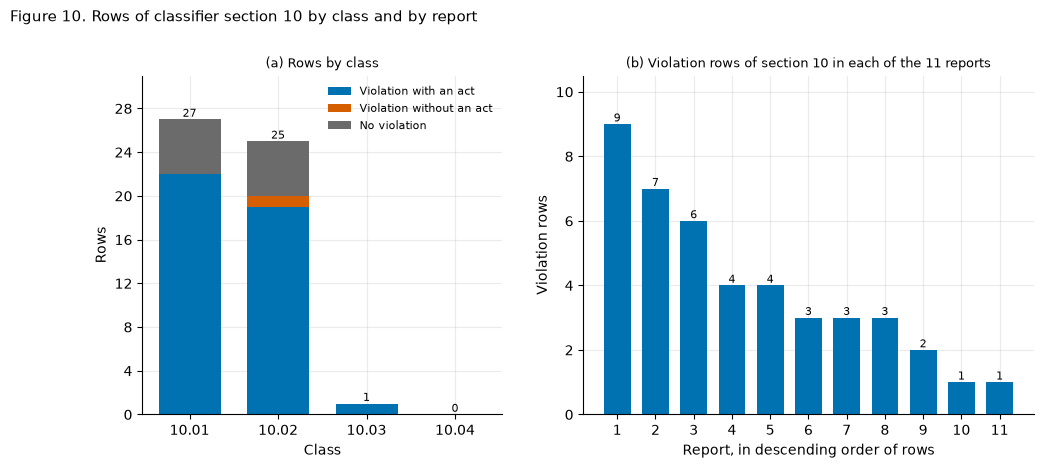

In [32]:
s10_fig, s10_axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
s10_x = np.arange(len(ex_ante_control_by_class))
s10_with = ex_ante_control_by_class["rows_with_act"].to_numpy()
s10_without = ex_ante_control_by_class["rows_without_act"].to_numpy()
s10_none = ex_ante_control_by_class["rows_no_violation"].to_numpy()

s10_ax = s10_axes[0]
s10_ax.bar(s10_x, s10_with, color=C_BLUE, width=0.7, label="Violation with an act")
s10_ax.bar(s10_x, s10_without, bottom=s10_with, color=C_VERMILION, width=0.7, label="Violation without an act")
s10_ax.bar(s10_x, s10_none, bottom=s10_with + s10_without, color=C_GREY, width=0.7, label="No violation")
for s10_i, s10_top in enumerate(s10_with + s10_without + s10_none):
    s10_ax.text(s10_i, s10_top, str(int(s10_top)), ha="center", va="bottom", fontsize=8)
s10_ax.set_xticks(s10_x)
s10_ax.set_xticklabels(ex_ante_control_by_class["class_index"])
s10_ax.set_xlabel("Class")
s10_ax.set_ylabel("Rows")
s10_ax.set_ylim(0, 31)
s10_ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
s10_ax.legend(frameon=False, fontsize=8, loc="upper right")
s10_ax.set_title("(a) Rows by class", fontsize=9)

s10_ax = s10_axes[1]
s10_report_x = np.arange(1, len(s10_per_report) + 1)
s10_ax.bar(s10_report_x, s10_per_report, color=C_BLUE, width=0.7)
for s10_i, s10_n_rows in zip(s10_report_x, s10_per_report):
    s10_ax.text(s10_i, s10_n_rows, str(s10_n_rows), ha="center", va="bottom", fontsize=8)
s10_ax.set_xticks(s10_report_x)
s10_ax.set_xlabel("Report, in descending order of rows")
s10_ax.set_ylabel("Violation rows")
s10_ax.set_ylim(0, 10.5)
s10_ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
s10_ax.set_title(f"(b) Violation rows of section 10 in each of the {len(s10_per_report)} reports", fontsize=9)

s10_fig.suptitle("Figure 10. Rows of classifier section 10 by class and by report", x=0.01, ha="left", y=1.03, fontsize=11)
s10_fig.savefig(FIG_DIR / "F10_ex_ante_control.png", bbox_inches="tight")
plt.show()

**Reading Figure 10.** In panel (a) class `10.01` has 27 rows: 22 violation rows with an act and 5 no-violation rows. Class `10.02` has 25 rows: 19 violation rows with an act, 1 without an act and 5 no-violation rows. Class `10.03` has one violation row with an act, and `10.04` has no row. In panel (b) the 11 reports have 9, 7, 6, 4, 4, 3, 3, 3, 2, 1 and 1 violation rows. The three largest reports have 22 of the 43 rows, and two reports have one row each. The rows are therefore concentrated in a few reports, which is why the cluster bootstrap interval of the share is wider than the interval of Wilson. The figure shows where the recorded rows are and not how well the control worked in the schools.

### (3) Limits

#### 7.3.1 What the section does and does not show

- The counts are an **indicator** of the findings that the inspectors recorded, not proof of a violation. The reports are a sample of the inspections, and a share describes these reports, not the schools that were not inspected.
- The classes of section 10 show only the findings that are recorded in the checks of the procurements. Control that was examined outside these chapters is not in the table.
- The number of rows and of reports is small (43 rows in 11 reports), so the intervals are wide, and the rows are concentrated in a few reports, so the cluster bootstrap interval is wider than the interval of Wilson.
- A row without an act does not mean that the violation is lighter. The table has only one such row, and a share of rows with an act in a class with one or a few rows carries little information.
- The absence of rows in `10.04` does not show that the control under Art. 237b of the PPA was carried out. It shows only that the table has no such finding.

## 8. Supervised Check: Predicting the Class from the Cited Provisions (Check 3)

### (1) Question Addressed

#### 8.1.1 Can a trained model reproduce the sections and the classes of the table from the cited provisions of a finding?

**Question.** When a model is trained on some of the reports and tested on reports that it has not seen, how well does it reproduce the sections and the classes that the table gives to a finding, if its only input is the list of provisions cited for the finding?

**Logic for a controller.** Section 3 asked whether fixed rules reproduce the table; this section asks whether a model that learns from the table does so for new reports. A high agreement would mean that the cited provisions carry the information on the type of the finding, so that a controller can expect the type from the citation. A low agreement means that the provisions do not carry it, or that the classes are too rare to be learned. The check measures **learnability against the table**, not the correctness of the table: the targets are the sections and the classes of the table itself, and the check says nothing on whether a class is the right one for a finding (that is the question of the manual sample in Section 4). For this part Section 1.2.1 states **no hypothesis and no threshold** apart from the 5 folds fixed there. The result is an **indicator** of how far the provisions explain the classes, not proof of a violation, and the reports are a sample of the inspections.

### (2) Method: TF-IDF Features, One-vs-Rest Logistic Regression and Folds Grouped by Report

#### 8.2.1 The features, the model, the folds and the measures

**Question.** How is the prediction built so that a finding is never predicted by a model that has seen a finding of the same report, and which settings are fixed before the computation?

**Logic for a controller.** The unit is the finding of Section 3.2.4: 1,373 findings, 784 of them violations. The only input is the text of the column `provisions`, for example `чл. 20, ал. 3, т. 2 от ЗОП; чл. 20, ал. 4, т. 3 от ЗОП`. The statute is already in this text, so the column `law` is not used separately. The classes, the sections, the basis, the confidence, the act and the school of the table are not used as input. A finding without a cited provision (112 findings, 9 of them violations) has an empty input.

The text is turned into weights of **tokens** and of pairs of neighbouring tokens (TF-IDF; Salton and Buckley, 1988), with the scikit-learn settings used here (Pedregosa et al., 2011). The weight of a term $t$ in the provisions of the finding $d$ is

$$w(t,d)=\bigl(1+\ln \mathrm{tf}_{t,d}\bigr)\left(\ln\frac{1+N}{1+\mathrm{df}_t}+1\right),\qquad \mathbf{x}_d=\frac{\mathbf{w}_d}{\lVert\mathbf{w}_d\rVert_2}.$$

Where: $\mathrm{tf}_{t,d}$ is the number of times that the term $t$ occurs in the provisions of the finding $d$; $N$ is the number of findings of the training part; $\mathrm{df}_t$ is the number of findings of the training part whose provisions contain $t$; $\mathbf{w}_d$ is the vector of the weights $w(t,d)$ of the finding $d$; $\mathbf{x}_d$ is the same vector scaled to length 1. The terms and the values of $\mathrm{df}_t$ come from the training part only.

For every section and every class $c$ one logistic regression is trained against all the other labels (one-vs-rest; Pedregosa et al., 2011):

$$\Pr(y_{d,c}=1\mid\mathbf{x}_d)=\sigma\bigl(\mathbf{w}_c^{\top}\mathbf{x}_d+b_c\bigr),\qquad \sigma(z)=\frac{1}{1+e^{-z}},$$

and the label $c$ is predicted for $d$ when this probability is above 0.5. The weights $\mathbf{w}_c$ and the intercept $b_c$ minimise

$$\tfrac12\lVert\mathbf{w}_c\rVert^2+C\sum_{d}\log\Bigl(1+e^{-\tilde y_{d,c}\,(\mathbf{w}_c^{\top}\mathbf{x}_d+b_c)}\Bigr),\qquad \tilde y_{d,c}=2y_{d,c}-1 .$$

Where: $y_{d,c}\in\{0,1\}$ is the label of the table, 1 if the finding $d$ has the section or the class $c$ and 0 otherwise; $\tilde y_{d,c}\in\{-1,+1\}$ is the same label with the values $-1$ and $+1$, needed only in the formula of the loss; $\sigma$ is the logistic function; $C$ is the inverse of the strength of the penalty. Because the 0.5 threshold is applied to every label separately, a finding can get several labels or none.

The folds are grouped by report (Pedregosa et al., 2011). Every report is in exactly one of the $K=5$ test parts, and in every split the reports of the training part and of the test part are disjoint: $\mathcal{G}^{(k)}_{\text{train}}\cap\mathcal{G}^{(k)}_{\text{test}}=\varnothing$ for $k=1,\dots,5$. `GroupKFold` without shuffling takes the reports in descending order of the number of their findings and puts each one in the part that has the fewest findings so far; the split is therefore the same at every run. The vectoriser and the models are fitted on the training part only. A label with no positive example in the training part cannot be learned: it is left out of the fit and never predicted in that part, and the number of such labels is shown for every part. The 5 predictions of the test parts together give one out-of-fold prediction for each of the 1,373 findings. The 784 violations are the subset of the same predictions and the models are not trained again for them.

The measures are those of Section 3.2.2 (precision, recall and F1, micro and macro), computed with the same function `metric_table` on the out-of-fold predictions. They are also computed on every test part alone, and the table shows the smallest and the largest value of the 5 parts as the **fold range**. The fold range is not a confidence interval.

**Fixed settings.** `C=1.0`, `solver="lbfgs"` and the threshold 0.5 are the defaults of scikit-learn. `token_pattern`, `ngram_range=(1, 2)`, `sublinear_tf=True` and `max_iter=1000` are chosen before the computation; nothing is tuned on the test parts. The default pattern keeps only tokens of two or more characters, and in the provisions the one-character tokens (the digits 1 to 9 and the abbreviation `т` of the item) are 10 of the 86 different tokens and 3,802 of the 12,900 occurrences (29.5 %), so two citations that differ only in a one-digit number would get the same input. The pattern `(?u)\b\w+\b` keeps them, and the pairs of neighbouring tokens keep the pairs such as the article with its paragraph and their order. There is no class weighting. The effect of these settings on the recall was not measured.

**What the next cell does.** It checks the versions of scikit-learn and scipy against `requirements.txt` in the same way as Section 1.3.2, builds the 5 parts from the reports of `FINDING_REPORT` and checks that the reports of the training part and of the test part do not overlap and that every finding is in a test part exactly once. In every part it fits the vectoriser and one logistic regression for each label with a positive example, with warnings turned into errors, and predicts the sections and the classes of the test part. It computes the measures for the 1,373 findings and for the 784 violations with `metric_table`, the measures of every part and their fold range, writes `data/derived/tfidf_groupkfold_metrics.csv` (136 rows, the same columns as `rule_classifier_metrics.csv`), and shows the size of the parts, the fold range and the measures of Check 1 and Check 3 side by side. All the figures used in the reading below are checked by `assert`.

In [33]:
import warnings

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.multiclass import OneVsRestClassifier

tf_rows = []
for tf_name in ("scikit-learn", "scipy"):
    try:
        tf_have = md_meta.version(tf_name)
    except md_meta.PackageNotFoundError:
        tf_have = "not installed"
    tf_rows.append((tf_name, _pinned[tf_name], tf_have, tf_have == _pinned[tf_name]))
TF_VERSIONS = pd.DataFrame(tf_rows, columns=["package", "pinned", "installed", "match"])
display(TF_VERSIONS)
assert TF_VERSIONS["match"].all(), "Installed versions differ from requirements.txt"

TF_VECTORIZER = {"token_pattern": r"(?u)\b\w+\b", "ngram_range": (1, 2), "sublinear_tf": True}
TF_K = HYPOTHESIS_THRESHOLDS["kfold_splits"]
TF_LEVELS = {
    "section": ("true_sections", section_labels, section_names),
    "class": ("true_classes", class_labels, class_names),
}
TF_MEASURES = ("precision", "recall", "f1")

tf_report = units["finding_no"].map(FINDING_REPORT["first"]).to_numpy()
tf_text = units["provisions"].reset_index(drop=True)
tf_n = len(units)
tf_violation = units["is_violation"].to_numpy()
tf_none = (units["provisions"] == "").to_numpy()
assert tf_n == 1373 and int(tf_violation.sum()) == 784
assert int(tf_none.sum()) == 112 and int((tf_none & tf_violation).sum()) == 9
assert len(set(tf_report)) == 488 and len(set(tf_report[tf_violation])) == 410

tf_token_counts = pd.Series([t for text in units["provisions"] for t in re.findall(r"\w+", text.lower())]).value_counts()
tf_one_char = tf_token_counts[tf_token_counts.index.str.len() == 1]
assert (len(tf_token_counts), len(tf_one_char), int(tf_one_char.sum()), int(tf_token_counts.sum())) == (86, 10, 3802, 12900)
assert units["provisions"].nunique() == 288 and (units["provisions"] != "").sum() == 1261

tf_folds = list(GroupKFold(n_splits=TF_K).split(tf_text, groups=tf_report))
tf_part = np.full(tf_n, -1)
for tf_k, (tf_train, tf_test) in enumerate(tf_folds):
    assert set(tf_report[tf_train]).isdisjoint(set(tf_report[tf_test]))
    tf_part[tf_test] = tf_k
assert np.array_equal(np.sort(np.concatenate([tf_test for _, tf_test in tf_folds])), np.arange(tf_n))
assert (tf_part >= 0).all()

tf_truth = {lv: np.array([[label in s for label in labels] for s in units[col]]) for lv, (col, labels, _) in TF_LEVELS.items()}
tf_oof = {lv: np.zeros_like(tf_truth[lv]) for lv in TF_LEVELS}
tf_part_rows = []
for tf_k, (tf_train, tf_test) in enumerate(tf_folds):
    tf_record = {
        "part": tf_k + 1,
        "train_findings": len(tf_train),
        "train_reports": len(set(tf_report[tf_train])),
        "test_findings": len(tf_test),
        "test_reports": len(set(tf_report[tf_test])),
        "test_violations": int(tf_violation[tf_test].sum()),
    }
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        tf_vectorizer = TfidfVectorizer(**TF_VECTORIZER)
        tf_x_train = tf_vectorizer.fit_transform(tf_text.iloc[tf_train])
        tf_x_test = tf_vectorizer.transform(tf_text.iloc[tf_test])
        tf_record["terms"] = len(tf_vectorizer.vocabulary_)
        for tf_level in TF_LEVELS:
            tf_y_train = tf_truth[tf_level][tf_train]
            tf_positive = tf_y_train.sum(axis=0)
            tf_active = (tf_positive >= 1) & (tf_positive < len(tf_train))
            tf_model = OneVsRestClassifier(LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000))
            tf_model.fit(tf_x_train, tf_y_train[:, tf_active])
            tf_block = np.zeros((len(tf_test), tf_truth[tf_level].shape[1]), dtype=bool)
            tf_block[:, tf_active] = tf_model.predict(tf_x_test).astype(bool)
            tf_oof[tf_level][tf_test] = tf_block
            tf_record[f"{tf_level}_labels_fitted"] = int(tf_active.sum())
            tf_record[f"{tf_level}_labels_without_positive"] = int((tf_positive == 0).sum())
            tf_record[f"{tf_level}_labels_all_positive"] = int((tf_positive == len(tf_train)).sum())
    tf_part_rows.append(tf_record)
tf_parts = pd.DataFrame(tf_part_rows)
display(tf_parts)

assert tf_parts["train_findings"].tolist() == [1098, 1098, 1098, 1099, 1099]
assert tf_parts["train_reports"].tolist() == [390, 390, 390, 391, 391]
assert tf_parts["test_findings"].tolist() == [275, 275, 275, 274, 274]
assert tf_parts["test_reports"].tolist() == [98, 98, 98, 97, 97]
assert tf_parts["test_violations"].tolist() == [171, 171, 141, 157, 144]
assert tf_parts["terms"].tolist() == [269, 280, 282, 279, 282]
assert tf_parts["section_labels_fitted"].tolist() == [11] * 5
assert tf_parts["section_labels_without_positive"].tolist() == [0] * 5
assert tf_parts["class_labels_fitted"].tolist() == [49, 49, 49, 47, 49]
assert tf_parts["class_labels_without_positive"].tolist() == [4, 4, 4, 6, 4]
assert (tf_parts[["section_labels_all_positive", "class_labels_all_positive"]] == 0).all().all()

tf_pred = {
    lv: pd.Series([{labels[j] for j in np.where(row)[0]} for row in tf_oof[lv]], index=units.index)
    for lv, (_, labels, _) in TF_LEVELS.items()
}
tf_masks = {"all_findings": np.ones(tf_n, dtype=bool), "violation_findings": tf_violation}

tf_tables = []
tf_range_rows = []
for tf_unit, tf_mask in tf_masks.items():
    for tf_level, (tf_col, tf_labels, tf_names) in TF_LEVELS.items():
        tf_table = metric_table(tf_unit, tf_level, units.loc[tf_mask, tf_col], tf_pred[tf_level][tf_mask], tf_labels, tf_names)
        tf_tables.append(tf_table)
        for tf_avg in ("micro", "macro"):
            tf_total = tf_table[tf_table["label"] == tf_avg].iloc[0]
            tf_by_part = []
            for tf_k in range(TF_K):
                tf_sub = tf_mask & (tf_part == tf_k)
                tf_sub_table = metric_table(tf_unit, tf_level, units.loc[tf_sub, tf_col], tf_pred[tf_level][tf_sub], tf_labels, tf_names)
                tf_by_part.append(tf_sub_table[tf_sub_table["label"] == tf_avg][list(TF_MEASURES)].iloc[0].astype(float).to_numpy())
            tf_by_part = np.array(tf_by_part)
            tf_record = [tf_unit, tf_level, tf_avg]
            for tf_i, tf_measure in enumerate(TF_MEASURES):
                tf_record += [round(float(tf_total[tf_measure]), 4), round(float(tf_by_part[:, tf_i].min()), 4), round(float(tf_by_part[:, tf_i].max()), 4)]
            tf_range_rows.append(tf_record)

tf_metrics = pd.concat(tf_tables, ignore_index=True)
for tf_column in ("support", "predicted", "tp", "fp", "fn"):
    tf_metrics[tf_column] = tf_metrics[tf_column].astype("Int64")
for tf_column in TF_MEASURES:
    tf_metrics[tf_column] = tf_metrics[tf_column].astype(float).round(4)
assert len(tf_metrics) == 136
assert tf_metrics.columns.tolist() == METRIC_COLUMNS
tf_metrics.to_csv(DERIVED_DIR / "tfidf_groupkfold_metrics.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

tf_range_columns = ["unit", "level", "averaging"] + [f"{m}{s}" for m in TF_MEASURES for s in ("", "_min", "_max")]
tf_ranges = pd.DataFrame(tf_range_rows, columns=tf_range_columns)
print("Fold range = smallest and largest value of the 5 test parts (not a confidence interval)")
display(tf_ranges)

TF_EXPECTED = {
    ("all_findings", "section", "micro"): (0.8300, 0.8174, 0.8571, 0.5704, 0.5347, 0.5987, 0.6761, 0.6585, 0.6981),
    ("all_findings", "section", "macro"): (0.6813, 0.6840, 0.8380, 0.4488, 0.3827, 0.5585, 0.5112, 0.4651, 0.6274),
    ("all_findings", "class", "micro"): (0.9695, 0.9383, 1.0000, 0.2095, 0.1864, 0.2292, 0.3446, 0.3128, 0.3712),
    ("all_findings", "class", "macro"): (0.2967, 0.2289, 0.3567, 0.1397, 0.1441, 0.2355, 0.1773, 0.1718, 0.2709),
    ("violation_findings", "section", "micro"): (0.7854, 0.7594, 0.8450, 0.5649, 0.5191, 0.6412, 0.6571, 0.6235, 0.7291),
    ("violation_findings", "section", "macro"): (0.6720, 0.5900, 0.7952, 0.4505, 0.4038, 0.5848, 0.4995, 0.4445, 0.6260),
    ("violation_findings", "class", "micro"): (0.9875, 0.9643, 1.0000, 0.1970, 0.1654, 0.2269, 0.3285, 0.2830, 0.3673),
    ("violation_findings", "class", "macro"): (0.2751, 0.1765, 0.3571, 0.1317, 0.1186, 0.2664, 0.1655, 0.1366, 0.2896),
}
assert len(tf_ranges) == len(TF_EXPECTED) == 8
for tf_key, tf_values in TF_EXPECTED.items():
    tf_found = tf_ranges[(tf_ranges["unit"] == tf_key[0]) & (tf_ranges["level"] == tf_key[1]) & (tf_ranges["averaging"] == tf_key[2])].iloc[0]
    for tf_column, tf_value in zip(tf_range_columns[3:], tf_values):
        assert abs(tf_found[tf_column] - tf_value) < 1e-9, (tf_key, tf_column, tf_found[tf_column], tf_value)

TF_COUNTS = {
    ("all_findings", "section"): (859, 176, 647, 1035, 1506),
    ("all_findings", "class"): (382, 12, 1441, 394, 1823),
    ("violation_findings", "section"): (505, 138, 389, 643, 894),
    ("violation_findings", "class"): (237, 3, 966, 240, 1203),
}
for tf_key, tf_values in TF_COUNTS.items():
    tf_found = tf_metrics[(tf_metrics["unit"] == tf_key[0]) & (tf_metrics["level"] == tf_key[1]) & (tf_metrics["label"] == "micro")].iloc[0]
    assert tuple(int(tf_found[c]) for c in ("tp", "fp", "fn", "predicted", "support")) == tf_values, tf_key
for tf_key, tf_value in {("all_findings", "section"): 11, ("all_findings", "class"): 50, ("violation_findings", "section"): 11, ("violation_findings", "class"): 47}.items():
    tf_found = tf_metrics[(tf_metrics["unit"] == tf_key[0]) & (tf_metrics["level"] == tf_key[1]) & (tf_metrics["label"] == "macro")].iloc[0]
    assert int(tf_found["support"]) == tf_value, tf_key

tf_empty_rows = []
for tf_level in TF_LEVELS:
    tf_sizes = tf_pred[tf_level].map(len)
    tf_empty_rows.append([
        tf_level,
        int((tf_sizes == 0).sum()), int((tf_sizes[tf_violation] == 0).sum()),
        int(tf_sizes.sum()), int(tf_sizes[tf_violation].sum()),
        int(tf_sizes[tf_none].sum()), int((tf_sizes[tf_none] == 0).sum()),
    ])
tf_empty = pd.DataFrame(tf_empty_rows, columns=["level", "empty_all", "empty_violations", "labels_all", "labels_violations",
                                              "labels_for_no_provision", "empty_for_no_provision"])
print("Empty predictions at the threshold 0.5 and the findings without a cited provision")
display(tf_empty)
assert tf_empty.set_index("level").loc["section"].tolist() == [345, 141, 1035, 643, 0, 112]
assert tf_empty.set_index("level").loc["class"].tolist() == [981, 544, 394, 240, 0, 112]

tf_side = pd.DataFrame([
    [tf_unit, tf_level, tf_avg,
     *(float(rule_metrics[(rule_metrics["unit"] == tf_unit) & (rule_metrics["level"] == tf_level) & (rule_metrics["label"] == tf_avg)][m].iloc[0]) for m in TF_MEASURES),
     *(float(tf_ranges[(tf_ranges["unit"] == tf_unit) & (tf_ranges["level"] == tf_level) & (tf_ranges["averaging"] == tf_avg)][m].iloc[0]) for m in TF_MEASURES)]
    for tf_unit in tf_masks for tf_level in TF_LEVELS for tf_avg in ("micro", "macro")
], columns=["unit", "level", "averaging", "check1_precision", "check1_recall", "check1_f1", "check3_precision", "check3_recall", "check3_f1"])
print("Check 1 (rules) and Check 3 (model) against the table")
display(tf_side)

,package,pinned,installed,match
0,scikit-learn,1.9.1,1.9.1,True
1,scipy,1.18.1,1.18.1,True


,part,train_findings,train_reports,test_findings,test_reports,test_violations,terms,section_labels_fitted,section_labels_without_positive,section_labels_all_positive,class_labels_fitted,class_labels_without_positive,class_labels_all_positive
0,1,1098,390,275,98,171,269,11,0,0,49,4,0
1,2,1098,390,275,98,171,280,11,0,0,49,4,0
2,3,1098,390,275,98,141,282,11,0,0,49,4,0
3,4,1099,391,274,97,157,279,11,0,0,47,6,0
4,5,1099,391,274,97,144,282,11,0,0,49,4,0


Fold range = smallest and largest value of the 5 test parts (not a confidence interval)


,unit,level,averaging,precision,precision_min,precision_max,recall,recall_min,recall_max,f1,f1_min,f1_max
0,all_findings,section,micro,0.8300,0.8174,0.8571,0.5704,0.5347,0.5987,0.6761,0.6585,0.6981
1,all_findings,section,macro,0.6813,0.6840,0.8380,0.4488,0.3827,0.5585,0.5112,0.4651,0.6274
2,all_findings,class,micro,0.9695,0.9383,1.0000,0.2095,0.1864,0.2292,0.3446,0.3128,0.3712
3,all_findings,class,macro,0.2967,0.2289,0.3567,0.1397,0.1441,0.2355,0.1773,0.1718,0.2709
4,violation_findings,section,micro,0.7854,0.7594,0.8450,0.5649,0.5191,0.6412,0.6571,0.6235,0.7291
5,violation_findings,section,macro,0.6720,0.5900,0.7952,0.4505,0.4038,0.5848,0.4995,0.4445,0.6260
6,violation_findings,class,micro,0.9875,0.9643,1.0000,0.1970,0.1654,0.2269,0.3285,0.2830,0.3673
7,violation_findings,class,macro,0.2751,0.1765,0.3571,0.1317,0.1186,0.2664,0.1655,0.1366,0.2896


Empty predictions at the threshold 0.5 and the findings without a cited provision


,level,empty_all,empty_violations,labels_all,labels_violations,labels_for_no_provision,empty_for_no_provision
0,section,345,141,1035,643,0,112
1,class,981,544,394,240,0,112


Check 1 (rules) and Check 3 (model) against the table


,unit,level,averaging,check1_precision,check1_recall,check1_f1,check3_precision,check3_recall,check3_f1
0,all_findings,section,micro,0.5201,0.8599,0.6481,0.8300,0.5704,0.6761
1,all_findings,section,macro,0.7461,0.7234,0.6846,0.6813,0.4488,0.5112
2,all_findings,class,micro,0.1268,0.8618,0.2211,0.9695,0.2095,0.3446
3,all_findings,class,macro,0.5591,0.7905,0.5139,0.2967,0.1397,0.1773
4,violation_findings,section,micro,0.5347,0.9575,0.6862,0.7854,0.5649,0.6571
5,violation_findings,section,macro,0.7401,0.8743,0.7783,0.6720,0.4505,0.4995
6,violation_findings,class,micro,0.1423,0.9485,0.2475,0.9875,0.1970,0.3285
7,violation_findings,class,macro,0.5752,0.8741,0.5790,0.2751,0.1317,0.1655


**Reading the table.** Every test part has 274 or 275 findings from 97 or 98 reports, and no report is in the training part and in the test part of the same split. The vocabulary of a training part has 269 to 282 terms. At the level of the sections all 11 labels have a positive example in every training part. At the level of the classes 49, 49, 49, 47 and 49 of the 53 labels have one, so 4, 4, 4, 6 and 4 classes cannot be learned in the part and are never predicted there.

At the level of the sections the micro precision is 0.8300 (fold range [0.8174; 0.8571]), the micro recall 0.5704 ([0.5347; 0.5987]) and F1 0.6761 ([0.6585; 0.6981]) on all findings, and 0.7854 ([0.7594; 0.8450]), 0.5649 ([0.5191; 0.6412]) and 0.6571 ([0.6235; 0.7291]) on the violations. The macro averages over the 11 sections are P 0.6813 ([0.6840; 0.8380]), R 0.4488 ([0.3827; 0.5585]), F1 0.5112 ([0.4651; 0.6274]) on all findings and P 0.6720 ([0.5900; 0.7952]), R 0.4505 ([0.4038; 0.5848]), F1 0.4995 ([0.4445; 0.6260]) on the violations.

At the level of the classes the model predicts 394 labels for the 1,823 labels of the table: TP 382, FP 12, FN 1,441, so the micro precision is 0.9695 ([0.9383; 1.0000]), the micro recall 0.2095 ([0.1864; 0.2292]) and F1 0.3446 ([0.3128; 0.3712]). On the violations the numbers are 240 predicted labels for 1,203, TP 237, FP 3, FN 966, with P 0.9875 ([0.9643; 1.0000]), R 0.1970 ([0.1654; 0.2269]) and F1 0.3285 ([0.2830; 0.3673]). The macro averages over the 50 and 47 classes with support are P 0.2967 ([0.2289; 0.3567]), R 0.1397 ([0.1441; 0.2355]), F1 0.1773 ([0.1718; 0.2709]) and P 0.2751 ([0.1765; 0.3571]), R 0.1317 ([0.1186; 0.2664]), F1 0.1655 ([0.1366; 0.2896]). In two rows the value for the whole set lies outside the fold range; Section 8.3.1 gives the reason.

The model leaves a prediction empty at the threshold 0.5 for the class of 981 of the 1,373 findings (544 of the 784 violations) and for the section of 345 (141). The 112 findings without a cited provision, 9 of them violations, get no label at either level. The macro average gives every class the same weight and the micro average gives every label of the table the same weight; the macro F1 of the classes is lower than the micro F1 (0.1773 against 0.3446 and 0.1655 against 0.3285), so the average class is reproduced worse than the average label. This table does not measure which classes cause the difference.

Check 1 on the same findings has micro P, R and F1 of 0.5201, 0.8599 and 0.6481 for the sections and 0.1268, 0.8618 and 0.2211 for the classes (on the violations 0.5347, 0.9575, 0.6862 and 0.1423, 0.9485, 0.2475). The macro F1 of Check 1 is 0.6846 and 0.5139 on all findings and 0.7783 and 0.5790 on the violations. In the micro average the two checks lie on opposite sides: the rules of Check 1 have a recall above their precision at both levels, and the model of Check 3 has a precision above its recall. The table gives no measure of the uncertainty of the difference between the two checks, and a fold range is not a confidence interval, so it does not show whether any difference is more than chance. A class predicted by the model is a sign of agreement with the table, not a proven violation.

#### 8.2.2 The two checks in a figure

**Question.** How do the F1 of the rules (Check 1) and of the model trained on the cited provisions (Check 3) compare, for the same findings and the same labels?

**Logic for a controller.** The figure puts the two checks side by side for the sections and for the classes, so that a controller sees at once where an average over all labels and an average over the classes differ. It carries no interval, because Check 1 has a bootstrap interval (Figure 7) and Check 3 has only a fold range, and the two are not intervals of the same kind.

**What the next cell does.** It draws Figure 11 with two panels, one for all 1,373 findings and one for the 784 violations. In each panel the four groups of bars are the sections and the classes for Check 1 (from `rule_classifier_metrics.csv`, in memory as `rule_metrics`) and for Check 3 (from the table above); every group has the micro F1 and the macro F1, and the number over a bar is its value. The figure is saved as `fig/F11_rule_vs_tfidf.png`.

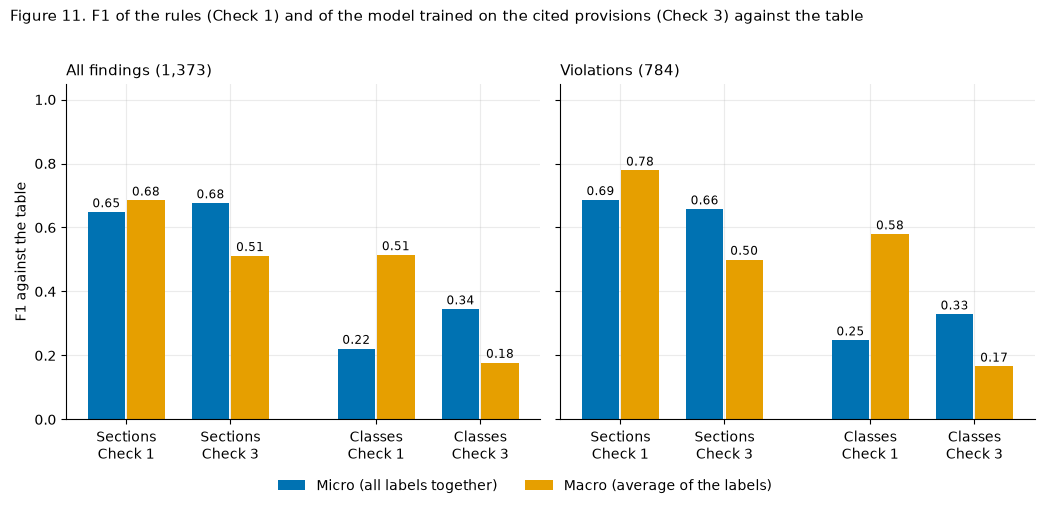

In [34]:
tf_fig, tf_axes = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
tf_panel_titles = {
    "all_findings": f"All findings ({len(units):,})",
    "violation_findings": f"Violations ({int(units['is_violation'].sum()):,})",
}
tf_groups = [("section", "Check 1", 0.0), ("section", "Check 3", 1.0), ("class", "Check 1", 2.4), ("class", "Check 3", 3.4)]
for tf_ax, tf_unit in zip(tf_axes, unit_sets):
    for tf_j, (tf_level, tf_check, tf_centre) in enumerate(tf_groups):
        for tf_offset, tf_avg, tf_colour, tf_label in ((-0.19, "micro", C_BLUE, "Micro (all labels together)"), (0.19, "macro", C_ORANGE, "Macro (average of the labels)")):
            if tf_check == "Check 1":
                tf_value = rule_metrics[(rule_metrics["unit"] == tf_unit) & (rule_metrics["level"] == tf_level) & (rule_metrics["label"] == tf_avg)]["f1"].iloc[0]
            else:
                tf_value = tf_ranges[(tf_ranges["unit"] == tf_unit) & (tf_ranges["level"] == tf_level) & (tf_ranges["averaging"] == tf_avg)]["f1"].iloc[0]
            tf_x = tf_centre + tf_offset
            tf_ax.bar(tf_x, tf_value, width=0.36, color=tf_colour, label=tf_label if tf_j == 0 else None)
            tf_ax.text(tf_x, tf_value + 0.015, f"{tf_value:.2f}", ha="center", fontsize=8.5)
    tf_ax.set_xticks([g[2] for g in tf_groups])
    tf_ax.set_xticklabels([f"{'Sections' if g[0] == 'section' else 'Classes'}\n{g[1]}" for g in tf_groups])
    tf_ax.set_ylim(0, 1.05)
    tf_ax.set_title(tf_panel_titles[tf_unit], loc="left")
tf_axes[0].set_ylabel("F1 against the table")
tf_handles, tf_names = tf_axes[0].get_legend_handles_labels()
tf_fig.legend(tf_handles, tf_names, ncol=2, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.06))
tf_fig.suptitle("Figure 11. F1 of the rules (Check 1) and of the model trained on the cited provisions (Check 3) against the table", x=0.01, ha="left", y=1.02, fontsize=11)
tf_fig.tight_layout()
tf_fig.savefig(FIG_DIR / "F11_rule_vs_tfidf.png", bbox_inches="tight")
plt.show()

**Reading Figure 11.** The micro F1 of the sections is 0.6481 for Check 1 and 0.6761 for Check 3 on all findings, and 0.6862 and 0.6571 on the violations. The macro F1 of the sections is 0.6846 and 0.5112 on all findings and 0.7783 and 0.4995 on the violations. For the classes the micro F1 is 0.2211 for Check 1 and 0.3446 for Check 3 on all findings, and 0.2475 and 0.3285 on the violations; the macro F1 is 0.5139 and 0.1773 on all findings and 0.5790 and 0.1655 on the violations. The micro F1 of the two checks is therefore within 0.03 for the sections and higher for Check 3 for the classes, and the macro F1 of Check 3 is lower than that of Check 1 in all four groups. The figure has no interval, so it does not show whether any of these differences is more than chance. It compares the agreement of each check with the table and not the correctness of any of them.

### (3) Limits

#### 8.3.1 What the check does and does not show

- The check measures **learnability against the table**, not correctness. The targets are the sections and the classes of the same table, so a model that reproduces them reproduces the table, including any error that it has. Whether a class is the right one for a finding is the question of the manual sample in Section 4.
- The only input is the column `provisions`. The table does not have the text of the conclusions of the reports, so the check says nothing on whether the text of a finding would predict its class better than its citation.
- 112 findings (9 violations) cite no provision. Their input is empty, and they get no label at either level.
- A class with support in fewer than 5 reports cannot appear in every test part, and a class with no positive example in a training part cannot be learned in that part: 4, 4, 4, 6 and 4 of the 53 classes in the 5 parts. Three classes (1.05, 5.04 and 10.04) have no finding in the table (support 0).
- The threshold 0.5 is applied to every label separately, so a finding can get several labels or none: the class is empty for 981 of the 1,373 findings. The settings were fixed before the computation and not tuned, and the effect of the settings on the recall was not measured.
- The fold range is the smallest and the largest value of the 5 test parts. It is not a confidence interval and it does not say how far the value would move in other reports. The value for the whole set is computed from all the out-of-fold predictions together. For the macro average it can lie outside the fold range, because the macro value of the whole set averages the labels that have support in the whole set, and the value of a part averages only the labels that have support in that part. This happens in two rows: the macro precision of the sections on all findings is 0.6813 against the fold range [0.6840; 0.8380], and the macro recall of the classes on all findings is 0.1397 against [0.1441; 0.2355].
- Check 1 and Check 3 are not compared by a test. Check 1 has a bootstrap interval and Check 3 has only a fold range, and neither gives an interval for the difference between the two.
- The values are an **indicator** of how far the cited provisions explain the classes of the table, not proof of a violation. The reports are a sample of the inspections, and the values describe these reports.

## Manifest of the data files

**What the next cell does.** It writes `data/MANIFEST.csv` with the size and the SHA-256 digest of every table and figure of the study, together with the source of each file and the date. Anyone can recompute the digests to check that a file has not been changed.

In [35]:
SOURCES = {
    "data/adfi_classification.csv": f"Fetched from {REF_REPO} at commit {REF_COMMIT} (SHA-256 checked)",
    "data/adfi_reports_meta.csv": "Prepared when the data were prepared (Section 2.2.4) from the register and the texts of the 560 reports",
    "data/derived/pii_scan.csv": "Prepared when the data were prepared (Sections 2.2.3 and 2.2.4): counts of candidate personal data per report",
    "data/derived/classifier_classes.csv": "Built in Section 2.2.7 from the classifier definition and the classification table",
    "validation/sample_design.csv": "Size of the sample in each stratum (Section 4.2.2), written in Section 4.2.3 after the draw",
    "validation/sample_blind.csv": "Drawn in Section 4.2.3; the column manual_class_index is empty for the annotator",
}
manifest_files = sorted([*DATA_DIR.glob("*.csv"), *DERIVED_DIR.glob("*.csv"), *VAL_DIR.glob("*.csv"), *FIG_DIR.glob("*.png")])
manifest_files = [p for p in manifest_files if p.name != "MANIFEST.csv"]
with open(DATA_DIR / "MANIFEST.csv", "w", encoding="utf-8", newline="") as f:
    w = csv.writer(f, delimiter=";", lineterminator="\n")
    w.writerow(["file", "size_bytes", "sha256", "source", "date"])
    for p in manifest_files:
        rel = p.relative_to(ROOT).as_posix()
        src = SOURCES.get(rel, "Figure drawn by this notebook" if rel.startswith("fig/") else "Table written by this notebook")
        w.writerow([rel, p.stat().st_size, sha256_file(p), src, BUILD_DATE])
manifest = pd.read_csv(DATA_DIR / "MANIFEST.csv", sep=";")
display(manifest[["file", "size_bytes", "source"]])

,file,size_bytes,source
0,data/adfi_classification.csv,977933,Fetched from beluhov/stem-collusion-npvu at co...
1,data/adfi_reports_meta.csv,214462,Prepared when the data were prepared (Section ...
2,data/derived/class_concentration.csv,6206,Table written by this notebook
3,data/derived/classifier_classes.csv,14491,Built in Section 2.2.7 from the classifier def...
4,data/derived/ex_ante_control_by_class.csv,512,Table written by this notebook
5,data/derived/h1a_sensitivity.csv,340,Table written by this notebook
6,data/derived/heterogeneity_by_class.csv,1377,Table written by this notebook
7,data/derived/pii_scan.csv,25505,Prepared when the data were prepared (Sections...
8,data/derived/reconciliation_summary.csv,3802,Table written by this notebook
9,data/derived/reconciliation_totals.csv,1407,Table written by this notebook


## References

1. **ADFI (2026)**. *Public Register of Reports from Public Financial Inspections Conducted under Art. 17 of the Public Financial Inspection Act*. Sofia: Public Financial Inspection Agency. [online] Available at: https://www.adfi.minfin.bg/bg/34 [Accessed: 1 November 2026].

2. **Beluhov, V. (2026)**. *Fiscal Exposure and Integrity Risk in School Public Procurement: Forensic Econometric and Network Analysis of the Bulgarian School STEM Programme (BG-RRP-1.015)*. [online] Available at: https://github.com/beluhov/stem-collusion-npvu [Accessed: 15 November 2026].

3. **Benjamini, Y. and Hochberg, Y. (1995)**. 'Controlling the false discovery rate: a practical and powerful approach to multiple testing', *Journal of the Royal Statistical Society: Series B (Methodological)*, 57(1), pp. 289–300. doi: [10.1111/j.2517-6161.1995.tb02031.x](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x).

4. **Bulgaria (2005)**. *Tax and Social Insurance Procedure Code* (Данъчно-осигурителен процесуален кодекс). State Gazette, No. 105, 29 December 2005.

5. **Bulgaria (2006a)**. *Financial Management and Control in the Public Sector Act* (Закон за финансовото управление и контрол в публичния сектор). State Gazette, No. 21, 10 March 2006.

6. **Bulgaria (2006b)**. *Public Financial Inspection Act* (Закон за държавната финансова инспекция). State Gazette, No. 33, 21 April 2006.

7. **Bulgaria (2016a)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016.

8. **Bulgaria (2016b)**. *Regulations for the Implementation of the Public Procurement Act* (Правилник за прилагане на Закона за обществените поръчки). State Gazette, No. 28, 8 April 2016.

9. **Cohen, J. (1960)**. 'A coefficient of agreement for nominal scales', *Educational and Psychological Measurement*, 20(1), pp. 37–46. doi: [10.1177/001316446002000104](https://doi.org/10.1177/001316446002000104).

10. **Cramér, H. (1946)**. *Mathematical Methods of Statistics*. Princeton, NJ: Princeton University Press, p. 282. [online] Available at: https://archive.org/details/in.ernet.dli.2015.223699 [Accessed: 15 November 2026].

11. **Efron, B. and Tibshirani, R.J. (1994)**. *An Introduction to the Bootstrap*. Chapman and Hall/CRC. doi: [10.1201/9780429246593](https://doi.org/10.1201/9780429246593).

12. **Pearson, K. (1900)**. 'On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling', *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science*, Series 5, 50(302), pp. 157–175. doi: [10.1080/14786440009463897](https://doi.org/10.1080/14786440009463897).

13. **Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. and Duchesnay, É. (2011)**. 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830. [online] Available at: https://jmlr.org/papers/v12/pedregosa11a.html [Accessed: 15 November 2026].

14. **Phipson, B. and Smyth, G.K. (2010)**. 'Permutation P-values should never be zero: calculating exact P-values when permutations are randomly drawn', *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39. doi: [10.2202/1544-6115.1585](https://doi.org/10.2202/1544-6115.1585).

15. **Salton, G. and Buckley, C. (1988)**. 'Term-weighting approaches in automatic text retrieval', *Information Processing & Management*, 24(5), pp. 513–523. doi: [10.1016/0306-4573(88)90021-0](https://doi.org/10.1016/0306-4573(88)90021-0).

16. **Wilson, E.B. (1927)**. 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, 22(158), pp. 209–212. doi: [10.1080/01621459.1927.10502953](https://doi.org/10.1080/01621459.1927.10502953).